<a href="https://colab.research.google.com/github/AnneliseMartins/mestrado/blob/main/Annelise_mestrado.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# ==============================================================
# REGRESSÃO LINEAR MÚLTIPLA — Dissertação (Conversação Social x Audiência Globoplay)
# Ambiente: Google Colab
# Bibliotecas: pandas + statsmodels
# ==============================================================

# --- 1. INSTALAÇÃO (rodar uma vez no Colab, se necessário) ---
# !pip install pandas statsmodels scipy matplotlib

import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson
from scipy import stats
import matplotlib.pyplot as plt

# --- 2. UPLOAD E LEITURA DO ARQUIVO ---
# No Colab, rode isto para subir o arquivo direto do seu computador:
# from google.colab import files
# uploaded = files.upload()

# Depois de subir, ajuste o nome do arquivo abaixo:
df = pd.read_csv("seu_arquivo.csv")  # ou pd.read_excel("seu_arquivo.xlsx")

# Confira as primeiras linhas e os tipos de dado
print(df.head())
print(df.info())

# --- 3. DEFINIÇÃO DAS VARIÁVEIS ---
# Nomes das colunas exatamente como aparecem no arquivo original

variavel_dependente = "Alcance (90d)"

variaveis_independentes = [
    "Talkability",
    "Buzz Score",
    "Views por post",
    "Tx de Engajamento",
]

# --- 4. VERIFICAÇÃO DE DADOS FALTANTES ---
print("\nValores ausentes por coluna:")
print(df[[variavel_dependente] + variaveis_independentes].isnull().sum())

# Remova ou trate linhas com dados faltantes antes de seguir, se houver
df = df.dropna(subset=[variavel_dependente] + variaveis_independentes)

# --- 5. ESTIMAÇÃO DO MODELO DE REGRESSÃO MÚLTIPLA ---
# Usando a interface de fórmula do statsmodels (mais legível)
# Como os nomes das colunas têm espaços/parênteses, é preciso "escapar"
# cada nome com Q("...") para a fórmula funcionar corretamente.

def escapar(nome_coluna):
    return f'Q("{nome_coluna}")'

formula = f"{escapar(variavel_dependente)} ~ " + " + ".join(
    escapar(v) for v in variaveis_independentes
)
modelo = smf.ols(formula=formula, data=df).fit()

# --- 6. SAÍDA COMPLETA DO MODELO ---
# Isto já traz: coeficientes, erro padrão, valores-t, p-valores, R², R² ajustado, F-estatística
print(modelo.summary())

# --- 7. TESTES DE PRESSUPOSTOS ---

# 7.1 Linearidade e Homocedasticidade — gráfico de resíduos vs. valores ajustados
plt.figure(figsize=(8, 5))
plt.scatter(modelo.fittedvalues, modelo.resid, alpha=0.6)
plt.axhline(y=0, color="red", linestyle="--")
plt.xlabel("Valores ajustados")
plt.ylabel("Resíduos")
plt.title("Resíduos vs. Valores Ajustados (Linearidade/Homocedasticidade)")
plt.show()

# 7.2 Homocedasticidade — Teste de Breusch-Pagan
# H0: homocedasticidade (variância constante) — p > 0,05 é o resultado desejado
bp_test = het_breuschpagan(modelo.resid, modelo.model.exog)
labels = ["LM Statistic", "LM p-value", "F-Statistic", "F p-value"]
print("\nTeste de Breusch-Pagan (Homocedasticidade):")
print(dict(zip(labels, bp_test)))

# 7.3 Independência dos resíduos — Durbin-Watson
# Valores próximos de 2 indicam ausência de autocorrelação
dw = durbin_watson(modelo.resid)
print(f"\nDurbin-Watson: {dw:.3f} (ideal: próximo de 2)")

# 7.4 Normalidade dos resíduos — Shapiro-Wilk
# H0: resíduos seguem distribuição normal — p > 0,05 é o resultado desejado
shapiro_test = stats.shapiro(modelo.resid)
print(f"\nTeste de Shapiro-Wilk (Normalidade): estatística={shapiro_test[0]:.4f}, p-valor={shapiro_test[1]:.4f}")

# Histograma dos resíduos (inspeção visual da normalidade)
plt.figure(figsize=(8, 5))
plt.hist(modelo.resid, bins=20, edgecolor="black")
plt.xlabel("Resíduos")
plt.ylabel("Frequência")
plt.title("Distribuição dos Resíduos")
plt.show()

# QQ-plot (outra forma visual de checar normalidade)
sm.qqplot(modelo.resid, line="45", fit=True)
plt.title("QQ-Plot dos Resíduos")
plt.show()

# 7.5 Multicolinearidade — VIF (Fator de Inflação da Variância)
# Importante quando há mais de uma variável independente (seu caso)
from statsmodels.stats.outliers_influence import variance_inflation_factor

X = sm.add_constant(df[variaveis_independentes])
vif_data = pd.DataFrame()
vif_data["Variável"] = X.columns
vif_data["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
print("\nFator de Inflação da Variância (VIF):")
print(vif_data)
# Regra prática: VIF > 10 indica problema sério de multicolinearidade

# --- 8. EXPORTAR RESULTADOS (opcional, para anexar na dissertação) ---
with open("resultado_regressao.txt", "w") as f:
    f.write(modelo.summary().as_text())

print("\nResumo do modelo salvo em 'resultado_regressao.txt'")



Arquivo carregado com sucesso usando encoding: latin-1
Separador detectado automaticamente. Colunas encontradas: ['Título/IP', 'Temporada', 'Lançamento', 'Território', 'Gênero Principal', 'Classe', 'Vertical', 'Formato', 'Episódios', 'Alcance', 'Buzz Score', 'Talkability', 'Posts', 'Views', 'Views por post', 'Tx de Engajamento']
                        Título/IP  Temporada  Lançamento   Território  \
0                         As Five          2  08/02/2023  dramaturgia   
1                          Origem          1  21/03/2023  dramaturgia   
2  The Good Doctor - O Bom Doutor          6  21/04/2023  dramaturgia   
3                       Os Outros          1  31/05/2023  dramaturgia   
4              A Vida Pela Frente          1  22/06/2023  dramaturgia   

    Gênero Principal      Classe        Vertical Formato  Episódios  Alcance  \
0              Drama    original  Entretenimento  séries          8   586125   
1  Suspense/Thriller  licenciado  Entretenimento  séries         10   

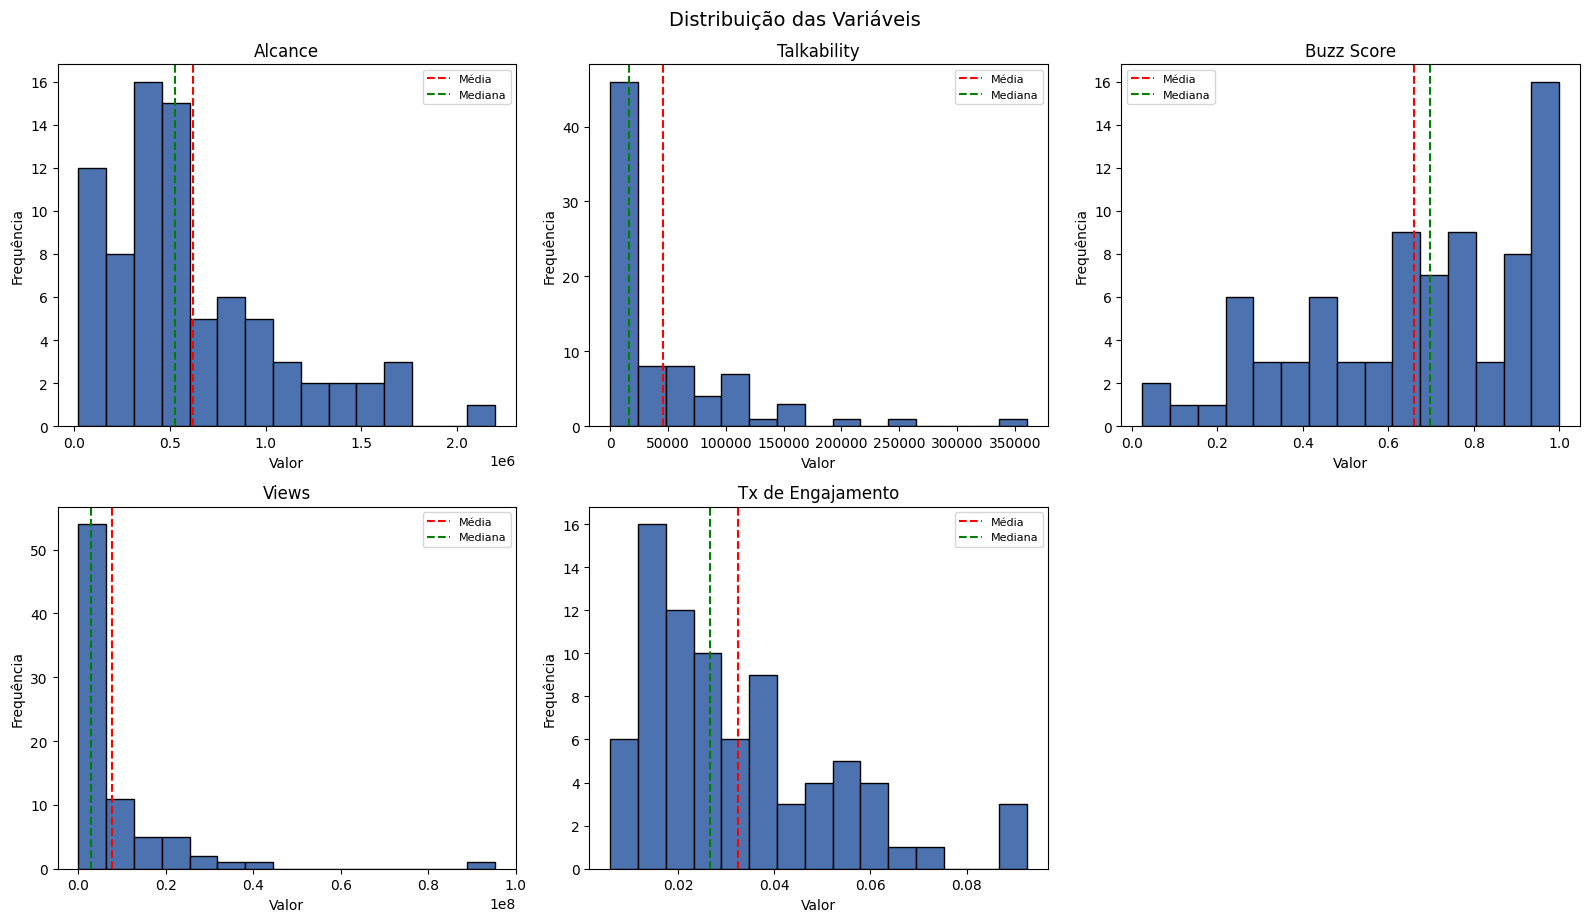

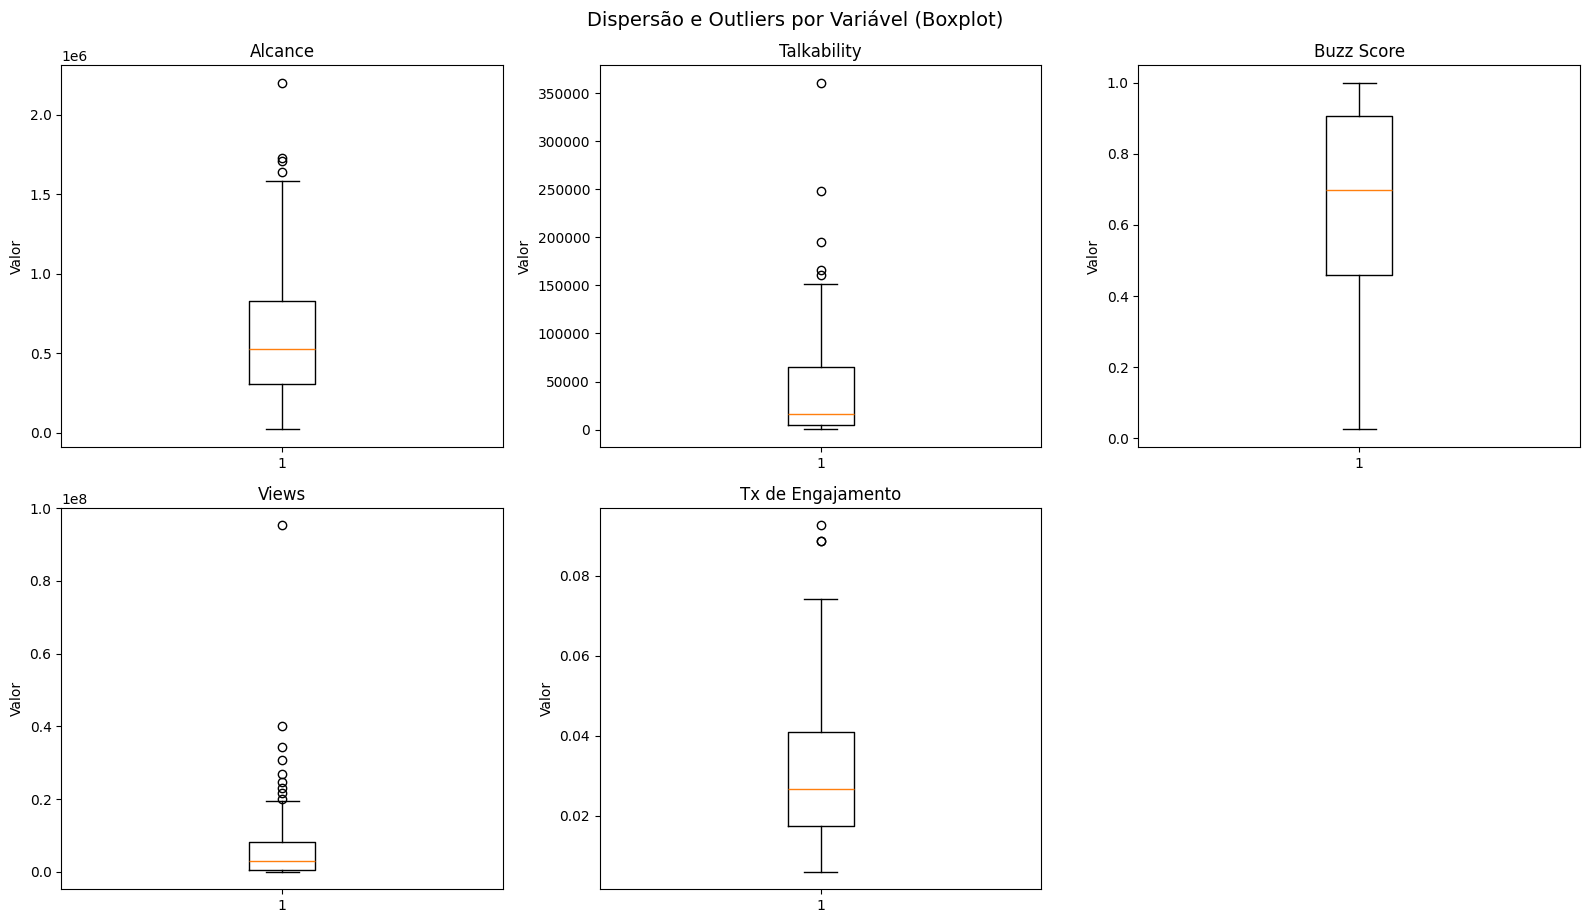


Valores ausentes por coluna:
Alcance              0
Talkability          0
Buzz Score           0
Views                0
Tx de Engajamento    0
dtype: int64
                            OLS Regression Results                            
Dep. Variable:           Q("Alcance")   R-squared:                       0.341
Model:                            OLS   Adj. R-squared:                  0.306
Method:                 Least Squares   F-statistic:                     9.692
Date:                Tue, 10 Nov 2026   Prob (F-statistic):           2.26e-06
Time:                        16:32:30   Log-Likelihood:                -1139.5
No. Observations:                  80   AIC:                             2289.
Df Residuals:                      75   BIC:                             2301.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                             coef    std err        

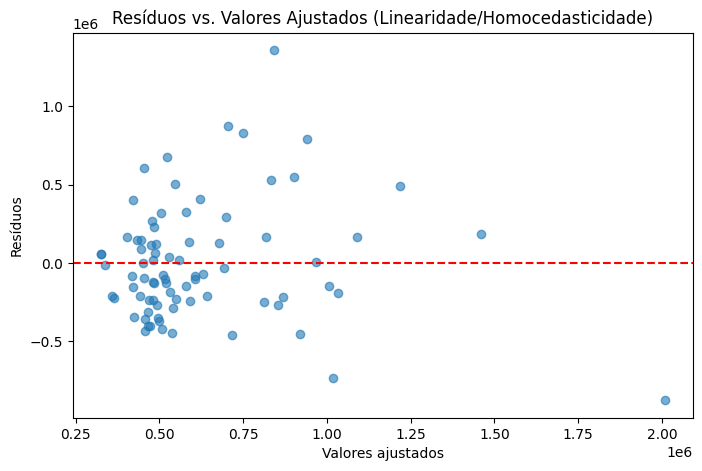


Teste de Breusch-Pagan (Homocedasticidade):
{'LM Statistic': np.float64(11.888745992762209), 'LM p-value': np.float64(0.018198041409571035), 'F-Statistic': np.float64(3.2727922956844044), 'F p-value': np.float64(0.015761118944370565)}

Durbin-Watson: 2.115 (ideal: próximo de 2)


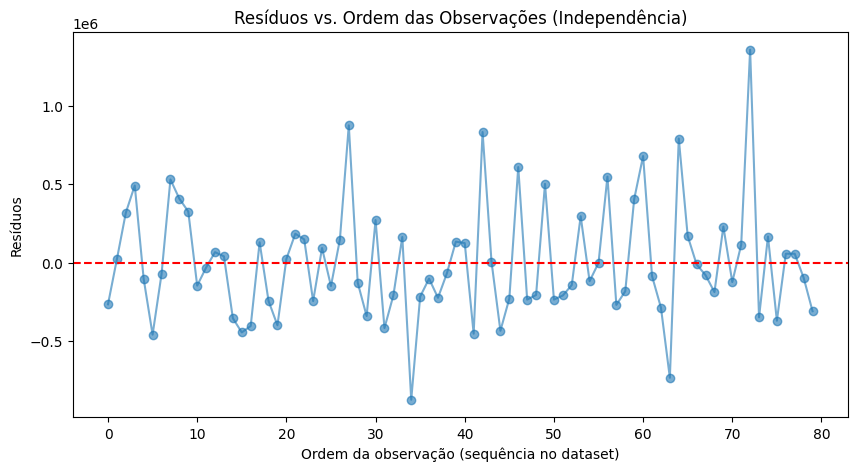


Teste de Shapiro-Wilk (Normalidade): estatística=0.9501, p-valor=0.0035


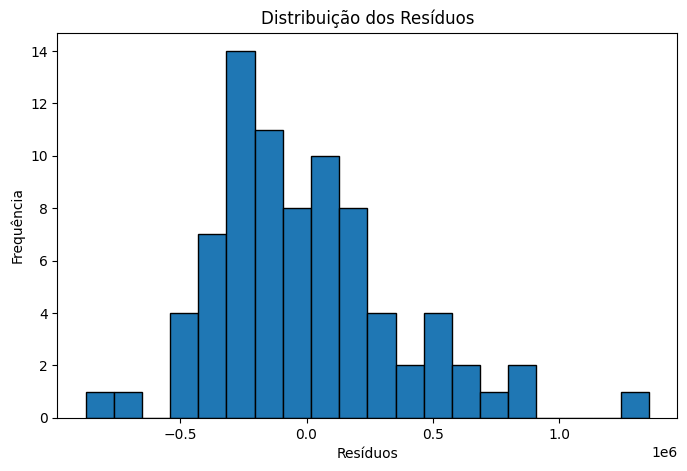

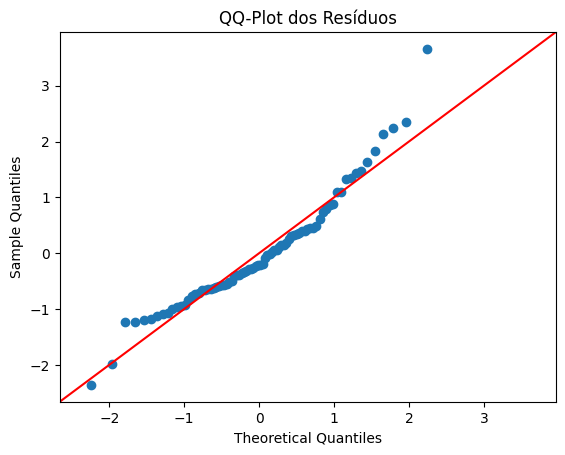


Fator de Inflação da Variância (VIF):
            Variável       VIF
0              const  1.000000
1        Talkability  3.004386
2         Buzz Score  1.038642
3              Views  3.040795
4  Tx de Engajamento  1.021791

Limite de referência para Distância de Cook (4/n): 0.0500

Casos com resíduo padronizado > |3| (outliers pelo critério de resíduo):
               Título/IP  Residuo_Padronizado  Distancia_Cook
34  Pra Sempre Paquitas             -3.579533        3.731221
72      Arcanjo Renegado             3.606917        0.096183

Casos com Distância de Cook acima do limite (observações influentes):
               Título/IP  Residuo_Padronizado  Distancia_Cook
3              Os Outros             1.407359        0.081551
34  Pra Sempre Paquitas             -3.579533        3.731221
63                Chaves            -2.116463        0.193971
72      Arcanjo Renegado             3.606917        0.096183

Diagnóstico específico para 'Arcanjo Renegado':
           Título/IP  Alca

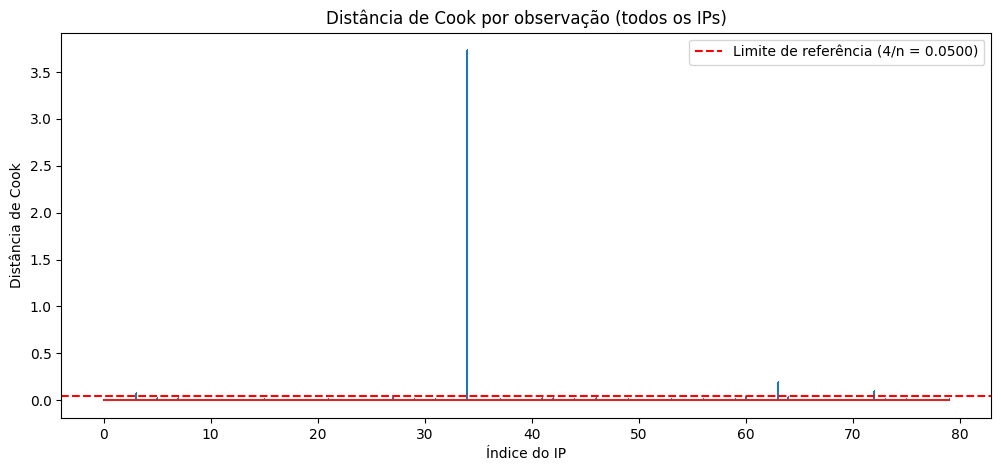


Resumo do modelo salvo em 'resultado_regressao.txt'


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:
# ==============================================================
# REGRESSÃO LINEAR MÚLTIPLA — Dissertação (Conversação Social x Audiência Globoplay)
# Ambiente: Google Colab
# Bibliotecas: pandas + statsmodels
# ==============================================================

# --- 1. INSTALAÇÃO (rodar uma vez no Colab, se necessário) ---
# !pip install pandas statsmodels scipy matplotlib

import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson
from scipy import stats
import matplotlib.pyplot as plt

# --- 2. LEITURA DO ARQUIVO ---
# O arquivo já está no ambiente do Colab (barra lateral de arquivos),
# então basta ler direto pelo nome.
#
# Arquivos .csv exportados do Excel no Brasil podem ter dois problemas comuns:
# 1) Encoding diferente de UTF-8 (ex.: latin-1, cp1252)
# 2) Separador ";" em vez de "," -- e quando isso não é tratado, vírgulas
#    dentro de textos (ex. títulos de programas) quebram a leitura.
#
# O código abaixo tenta detectar automaticamente o separador correto (usando
# o engine "python", que consegue inferir o delimitador com sep=None),
# combinando com os encodings mais comuns.

nome_arquivo = "Base_IPsGloboplay.csv"

encodings_para_tentar = ["utf-8", "latin-1", "cp1252"]

df = None
erro_final = None
for enc in encodings_para_tentar:
    try:
        df = pd.read_csv(nome_arquivo, encoding=enc, sep=None, engine="python")
        print(f"Arquivo carregado com sucesso usando encoding: {enc}")
        print(f"Separador detectado automaticamente. Colunas encontradas: {list(df.columns)}")
        break
    except (UnicodeDecodeError, pd.errors.ParserError) as e:
        erro_final = e
        continue

if df is None:
    raise ValueError(
        f"Não foi possível ler o arquivo automaticamente. Último erro: {erro_final}\n"
        "Isso geralmente indica que alguma linha do arquivo está com vírgulas "
        "ou ponto-e-vírgulas inconsistentes dentro do texto (ex.: título de "
        "programa com vírgula sem estar entre aspas no CSV original). "
        "Abra o arquivo original no Excel e verifique a linha indicada no erro, "
        "ou reexporte o arquivo garantindo que campos de texto com vírgula "
        "estejam entre aspas."
    )

# Confira as primeiras linhas e os tipos de dado
print(df.head())
print(df.info())

# --- 3. DEFINIÇÃO DAS VARIÁVEIS ---
# Nomes das colunas exatamente como aparecem no arquivo original

variavel_dependente = "Alcance"

variaveis_independentes = [
    "Talkability",
    "Buzz Score",
    "Views",
    "Tx de Engajamento",
]

# --- 3.1 DIAGNÓSTICO E LIMPEZA DE TIPOS DE DADOS ---
# Dados brasileiros exportados do Excel costumam vir como TEXTO, não número,
# por causa de vírgula decimal (ex. "12,5"), símbolo de % (ex. "12,5%") ou
# ponto como separador de milhar (ex. "1.234"). Se isso não for corrigido,
# o statsmodels trata a coluna como categórica e o modelo quebra.

print("Tipos de dados ANTES da limpeza:")
print(df[variaveis_independentes + [variavel_dependente]].dtypes)

def limpar_numero_br(coluna):
    """Converte uma coluna de texto em formato numérico brasileiro para float.
    Trata: espaços, símbolo de %, ponto de milhar e vírgula decimal."""
    if coluna.dtype == object:
        coluna = (
            coluna.astype(str)
            .str.strip()
            .str.replace("%", "", regex=False)
            .str.replace(".", "", regex=False)   # remove ponto de milhar
            .str.replace(",", ".", regex=False)   # vírgula -> ponto decimal
        )
        coluna = pd.to_numeric(coluna, errors="coerce")
    return coluna

for col in variaveis_independentes + [variavel_dependente]:
    df[col] = limpar_numero_br(df[col])

print("\nTipos de dados DEPOIS da limpeza:")
print(df[variaveis_independentes + [variavel_dependente]].dtypes)

# Se a limpeza gerou algum valor ausente (NaN) por não conseguir converter,
# isso aparece aqui -- vale checar antes de seguir:
print("\nValores que viraram NaN após a limpeza (se houver, investigue a fonte):")
print(df[variaveis_independentes + [variavel_dependente]].isnull().sum())

# --- 3.2 ANÁLISE DESCRITIVA DOS DADOS ---
# Estatísticas descritivas (média, mediana, desvio padrão, mínimo, máximo,
# quartis) e visualização da distribuição de cada variável, antes de rodar
# o modelo de regressão. Essa etapa costuma abrir a seção de Resultados,
# caracterizando a amostra antes de entrar na análise inferencial.

todas_variaveis_descritiva = [variavel_dependente] + variaveis_independentes

# Tabela de estatísticas descritivas
estatisticas_descritivas = df[todas_variaveis_descritiva].describe().T
estatisticas_descritivas["mediana"] = df[todas_variaveis_descritiva].median()
estatisticas_descritivas = estatisticas_descritivas[
    ["count", "mean", "mediana", "std", "min", "25%", "50%", "75%", "max"]
]
estatisticas_descritivas.columns = [
    "N", "Média", "Mediana", "Desvio Padrão", "Mínimo",
    "1º Quartil", "2º Quartil", "3º Quartil", "Máximo"
]

print("=" * 78)
print("ESTATÍSTICAS DESCRITIVAS")
print("=" * 78)
print(estatisticas_descritivas.round(2))

# Salvar a tabela descritiva em CSV (útil para colar direto numa tabela ABNT)
estatisticas_descritivas.round(2).to_csv("estatisticas_descritivas.csv")
print("\nTabela salva em 'estatisticas_descritivas.csv'")

# --- 3.3 HISTOGRAMAS — DISTRIBUIÇÃO DE CADA VARIÁVEL ---
fig, eixos = plt.subplots(2, 3, figsize=(16, 9))
eixos = eixos.flatten()

for i, col in enumerate(todas_variaveis_descritiva):
    eixos[i].hist(df[col], bins=15, edgecolor="black", color="#4C72B0")
    eixos[i].axvline(df[col].mean(), color="red", linestyle="--", label="Média")
    eixos[i].axvline(df[col].median(), color="green", linestyle="--", label="Mediana")
    eixos[i].set_title(col)
    eixos[i].set_xlabel("Valor")
    eixos[i].set_ylabel("Frequência")
    eixos[i].legend(fontsize=8)

# Remove eixo extra não utilizado (5 variáveis em grade 2x3 = 1 espaço sobra)
for j in range(len(todas_variaveis_descritiva), len(eixos)):
    fig.delaxes(eixos[j])

plt.tight_layout()
plt.suptitle("Distribuição das Variáveis", y=1.02, fontsize=14)
plt.savefig("histogramas_distribuicao.png", bbox_inches="tight", dpi=150)
plt.show()

# --- 3.4 BOXPLOTS — VISUALIZAR DISPERSÃO E OUTLIERS POR VARIÁVEL ---
fig, eixos = plt.subplots(2, 3, figsize=(16, 9))
eixos = eixos.flatten()

for i, col in enumerate(todas_variaveis_descritiva):
    eixos[i].boxplot(df[col], vert=True)
    eixos[i].set_title(col)
    eixos[i].set_ylabel("Valor")

for j in range(len(todas_variaveis_descritiva), len(eixos)):
    fig.delaxes(eixos[j])

plt.tight_layout()
plt.suptitle("Dispersão e Outliers por Variável (Boxplot)", y=1.02, fontsize=14)
plt.savefig("boxplots_variaveis.png", bbox_inches="tight", dpi=150)
plt.show()

# --- 4. VERIFICAÇÃO DE DADOS FALTANTES ---
print("\nValores ausentes por coluna:")
print(df[[variavel_dependente] + variaveis_independentes].isnull().sum())

# Remova ou trate linhas com dados faltantes antes de seguir, se houver
df = df.dropna(subset=[variavel_dependente] + variaveis_independentes)

# --- 5. ESTIMAÇÃO DO MODELO DE REGRESSÃO MÚLTIPLA ---
# Usando a interface de fórmula do statsmodels (mais legível)
# Como os nomes das colunas têm espaços/parênteses, é preciso "escapar"
# cada nome com Q("...") para a fórmula funcionar corretamente.

def escapar(nome_coluna):
    return f'Q("{nome_coluna}")'

formula = f"{escapar(variavel_dependente)} ~ " + " + ".join(
    escapar(v) for v in variaveis_independentes
)
modelo = smf.ols(formula=formula, data=df).fit()

# --- 6. SAÍDA COMPLETA DO MODELO ---
# Isto já traz: coeficientes, erro padrão, valores-t, p-valores, R², R² ajustado, F-estatística
print(modelo.summary())

# --- 6.1 MODELO PADRONIZADO (Z-SCORE) — para resolver problema de escala ---
# O número de condição alto (Cond. No.) no modelo acima geralmente indica que
# as variáveis estão em escalas muito diferentes entre si (ex. Talkability em
# unidades pequenas vs. Alcance na casa de centenas de milhares), e não
# necessariamente multicolinearidade real.
#
# Padronizar (transformar cada variável para média 0 e desvio padrão 1) resolve
# o problema numérico E torna os coeficientes comparáveis entre si — o maior
# coeficiente padronizado indica a variável com maior peso relativo no modelo.

from scipy.stats import zscore

df_padronizado = df.copy()
todas_variaveis = [variavel_dependente] + variaveis_independentes

for col in todas_variaveis:
    df_padronizado[col] = zscore(df_padronizado[col])

formula_padronizada = f"{escapar(variavel_dependente)} ~ " + " + ".join(
    escapar(v) for v in variaveis_independentes
)
modelo_padronizado = smf.ols(formula=formula_padronizada, data=df_padronizado).fit()

print("\n" + "=" * 78)
print("MODELO PADRONIZADO (coeficientes comparáveis entre si)")
print("=" * 78)
print(modelo_padronizado.summary())

# --- 7. TESTES DE PRESSUPOSTOS ---

# 7.1 Linearidade e Homocedasticidade — gráfico de resíduos vs. valores ajustados
plt.figure(figsize=(8, 5))
plt.scatter(modelo.fittedvalues, modelo.resid, alpha=0.6)
plt.axhline(y=0, color="red", linestyle="--")
plt.xlabel("Valores ajustados")
plt.ylabel("Resíduos")
plt.title("Resíduos vs. Valores Ajustados (Linearidade/Homocedasticidade)")
plt.savefig("residuos_vs_ajustados.png", bbox_inches="tight", dpi=150)
plt.show()

# 7.2 Homocedasticidade — Teste de Breusch-Pagan
# H0: homocedasticidade (variância constante) — p > 0,05 é o resultado desejado
bp_test = het_breuschpagan(modelo.resid, modelo.model.exog)
labels = ["LM Statistic", "LM p-value", "F-Statistic", "F p-value"]
print("\nTeste de Breusch-Pagan (Homocedasticidade):")
print(dict(zip(labels, bp_test)))

# 7.3 Independência dos resíduos — Durbin-Watson
# Valores próximos de 2 indicam ausência de autocorrelação
dw = durbin_watson(modelo.resid)
print(f"\nDurbin-Watson: {dw:.3f} (ideal: próximo de 2)")

# Gráfico de resíduos vs. ordem das observações (checagem visual de independência)
# Pressupõe que a ordem das linhas no dataset é significativa (ex. ordem
# cronológica de lançamento) -- o mesmo pressuposto do teste de Durbin-Watson.
plt.figure(figsize=(10, 5))
plt.plot(range(len(modelo.resid)), modelo.resid, marker="o", linestyle="-", alpha=0.6)
plt.axhline(y=0, color="red", linestyle="--")
plt.xlabel("Ordem da observação (sequência no dataset)")
plt.ylabel("Resíduos")
plt.title("Resíduos vs. Ordem das Observações (Independência)")
plt.savefig("residuos_vs_ordem.png", bbox_inches="tight", dpi=150)
plt.show()

# 7.4 Normalidade dos resíduos — Shapiro-Wilk
# H0: resíduos seguem distribuição normal — p > 0,05 é o resultado desejado
shapiro_test = stats.shapiro(modelo.resid)
print(f"\nTeste de Shapiro-Wilk (Normalidade): estatística={shapiro_test[0]:.4f}, p-valor={shapiro_test[1]:.4f}")

# Histograma dos resíduos (inspeção visual da normalidade)
plt.figure(figsize=(8, 5))
plt.hist(modelo.resid, bins=20, edgecolor="black")
plt.xlabel("Resíduos")
plt.ylabel("Frequência")
plt.title("Distribuição dos Resíduos")
plt.savefig("histograma_residuos.png", bbox_inches="tight", dpi=150)
plt.show()

# QQ-plot (outra forma visual de checar normalidade)
sm.qqplot(modelo.resid, line="45", fit=True)
plt.title("QQ-Plot dos Resíduos")
plt.savefig("qqplot_residuos.png", bbox_inches="tight", dpi=150)
plt.show()

# 7.5 Multicolinearidade — VIF (Fator de Inflação da Variância)
# Importante quando há mais de uma variável independente (seu caso)
from statsmodels.stats.outliers_influence import variance_inflation_factor

X = sm.add_constant(df[variaveis_independentes])
vif_data = pd.DataFrame()
vif_data["Variável"] = X.columns
vif_data["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
print("\nFator de Inflação da Variância (VIF):")
print(vif_data)
# Regra prática: VIF > 10 indica problema sério de multicolinearidade

# --- 7.6 DIAGNÓSTICO DE OUTLIERS E OBSERVAÇÕES INFLUENTES ---
# Antes de remover qualquer caso do modelo, é preciso justificativa estatística
# objetiva — não basta "achar" que um caso é outlier. Duas métricas padrão:
#
# 1) Resíduo padronizado: valores acima de |3| (ou às vezes |2|) indicam que
#    aquele caso está muito distante do que o modelo previu.
# 2) Distância de Cook: mede o quanto aquele caso, sozinho, influencia as
#    estimativas do modelo. Regra prática: valores acima de 4/n são notáveis.

influence = modelo.get_influence()
residuos_padronizados = influence.resid_studentized_internal
distancia_cook = influence.cooks_distance[0]

diagnostico = df.copy()
diagnostico["Residuo_Padronizado"] = residuos_padronizados
diagnostico["Distancia_Cook"] = distancia_cook

limite_cook = 4 / len(df)

print(f"\nLimite de referência para Distância de Cook (4/n): {limite_cook:.4f}")
print("\nCasos com resíduo padronizado > |3| (outliers pelo critério de resíduo):")
print(diagnostico[diagnostico["Residuo_Padronizado"].abs() > 3][
    ["Título/IP", "Residuo_Padronizado", "Distancia_Cook"]
])

print("\nCasos com Distância de Cook acima do limite (observações influentes):")
print(diagnostico[diagnostico["Distancia_Cook"] > limite_cook][
    ["Título/IP", "Residuo_Padronizado", "Distancia_Cook"]
])

# Para checar um IP específico (ex. "Arcanjo Renegado"), use:
ip_para_checar = "Arcanjo Renegado"
print(f"\nDiagnóstico específico para '{ip_para_checar}':")
print(diagnostico[diagnostico["Título/IP"] == ip_para_checar][
    ["Título/IP", variavel_dependente, "Residuo_Padronizado", "Distancia_Cook"]
])

# --- 7.7 DISTÂNCIA DE COOK — TODOS OS 80 IPs, ORDENADOS DO MAIS INFLUENTE ---
# Visão completa para identificar rapidamente se há outros candidatos a
# observação influente além do que já foi identificado manualmente.

tabela_cook_completa = diagnostico[
    ["Título/IP", variavel_dependente, "Residuo_Padronizado", "Distancia_Cook"]
].sort_values("Distancia_Cook", ascending=False).reset_index(drop=True)

print("\n" + "=" * 78)
print("DISTÂNCIA DE COOK — TODOS OS IPs (ordenado do mais para o menos influente)")
print("=" * 78)
print(tabela_cook_completa.to_string())

# Gráfico de distância de Cook por observação (facilita visualizar outliers)
plt.figure(figsize=(12, 5))
plt.stem(range(len(diagnostico)), diagnostico["Distancia_Cook"], markerfmt=",")
plt.axhline(y=limite_cook, color="red", linestyle="--",
            label=f"Limite de referência (4/n = {limite_cook:.4f})")
plt.xlabel("Índice do IP")
plt.ylabel("Distância de Cook")
plt.title("Distância de Cook por observação (todos os IPs)")
plt.legend()
plt.show()

# --- 8. EXPORTAR RESULTADOS (opcional, para anexar na dissertação) ---
with open("resultado_regressao.txt", "w") as f:
    f.write(modelo.summary().as_text())

print("\nResumo do modelo salvo em 'resultado_regressao.txt'")

# Baixa o arquivo automaticamente para o seu computador
from google.colab import files
files.download("resultado_regressao.txt")


Arquivo carregado com sucesso usando encoding: latin-1
Separador detectado automaticamente. Colunas encontradas: ['Título/IP', 'Temporada', 'Lançamento', 'Território', 'Gênero Principal', 'Classe', 'Vertical', 'Formato', 'Episódios', 'Alcance', 'Buzz Score', 'Talkability', 'Posts', 'Views', 'Views por post', 'Tx de Engajamento']
                        Título/IP  Temporada  Lançamento   Território  \
0                         As Five          2  08/02/2023  dramaturgia   
1                          Origem          1  21/03/2023  dramaturgia   
2  The Good Doctor - O Bom Doutor          6  21/04/2023  dramaturgia   
3                       Os Outros          1  31/05/2023  dramaturgia   
4              A Vida Pela Frente          1  22/06/2023  dramaturgia   

    Gênero Principal      Classe        Vertical Formato  Episódios  Alcance  \
0              Drama    original  Entretenimento  séries          8   586125   
1  Suspense/Thriller  licenciado  Entretenimento  séries         10   

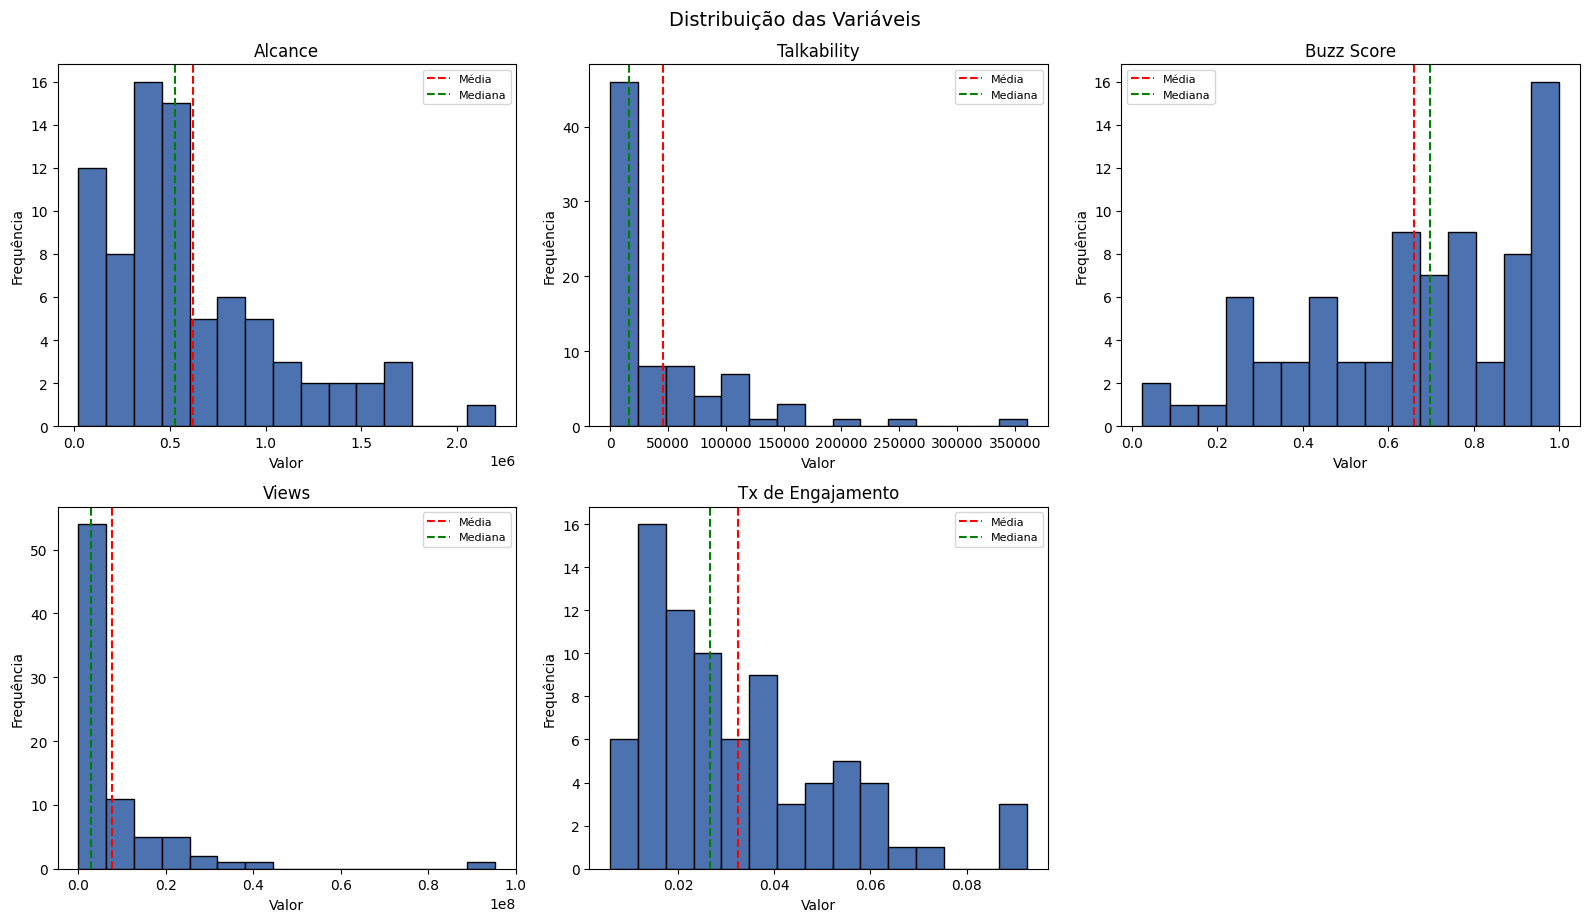

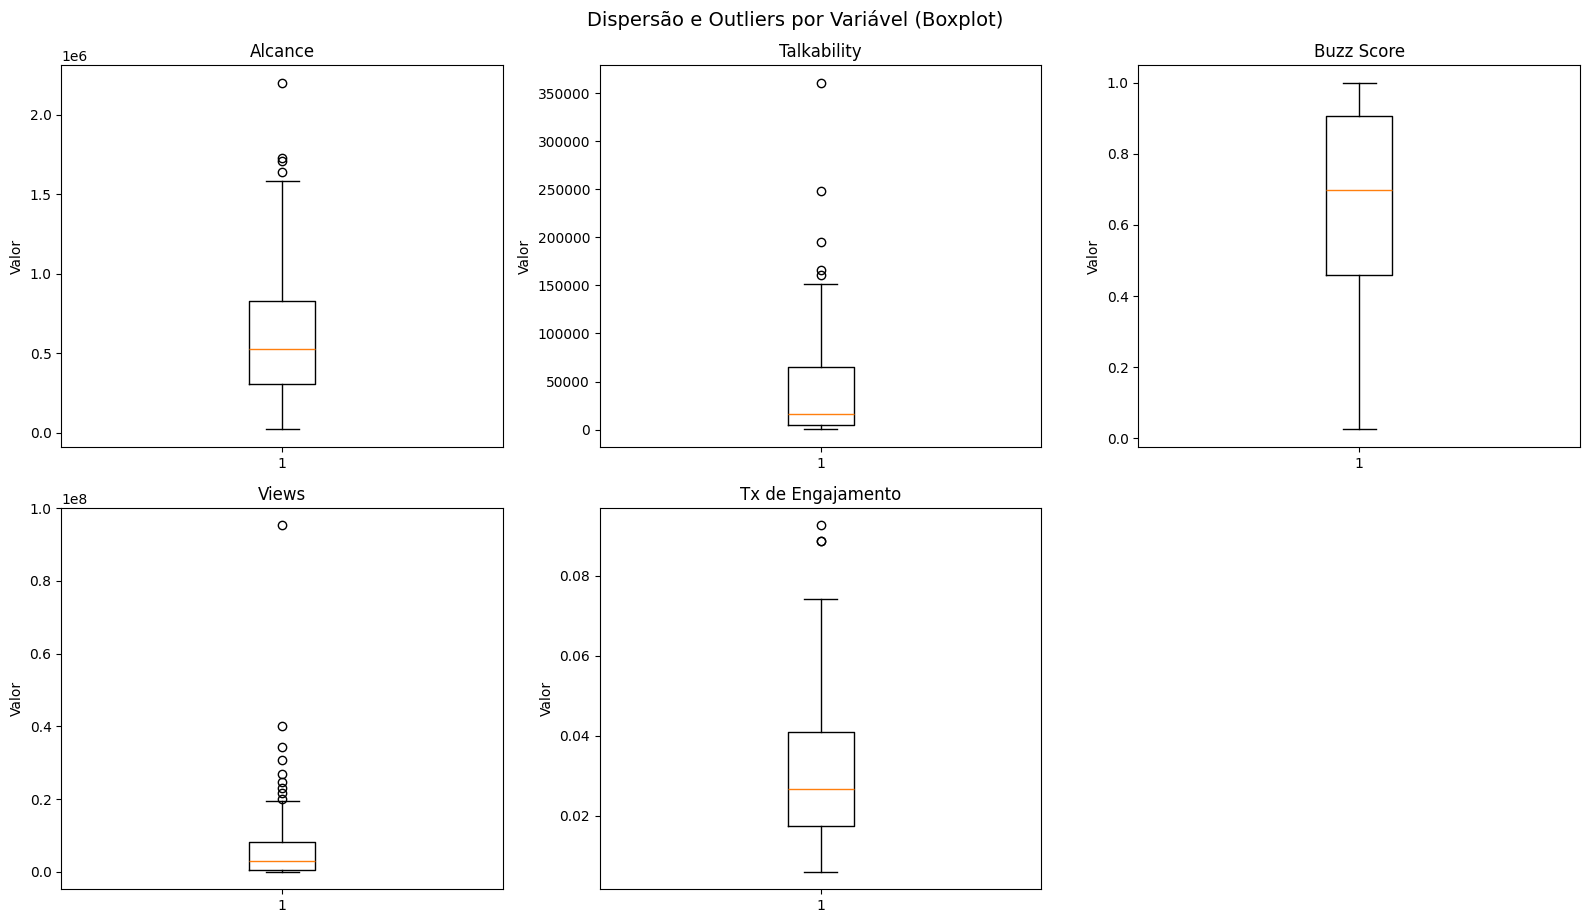


Valores ausentes por coluna:
Alcance              0
Talkability          0
Buzz Score           0
Views                0
Tx de Engajamento    0
dtype: int64
                            OLS Regression Results                            
Dep. Variable:           Q("Alcance")   R-squared:                       0.341
Model:                            OLS   Adj. R-squared:                  0.306
Method:                 Least Squares   F-statistic:                     9.692
Date:                Tue, 10 Nov 2026   Prob (F-statistic):           2.26e-06
Time:                        16:55:32   Log-Likelihood:                -1139.5
No. Observations:                  80   AIC:                             2289.
Df Residuals:                      75   BIC:                             2301.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                             coef    std err        

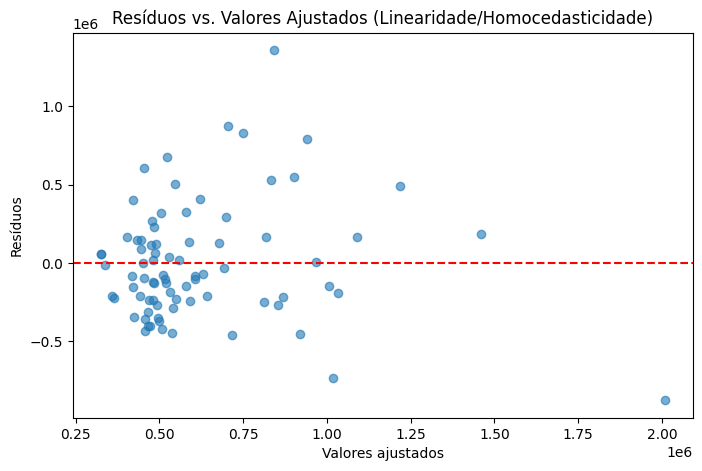


Teste de Breusch-Pagan (Homocedasticidade):
{'LM Statistic': np.float64(11.888745992762209), 'LM p-value': np.float64(0.018198041409571035), 'F-Statistic': np.float64(3.2727922956844044), 'F p-value': np.float64(0.015761118944370565)}

Durbin-Watson: 2.115 (ideal: próximo de 2)


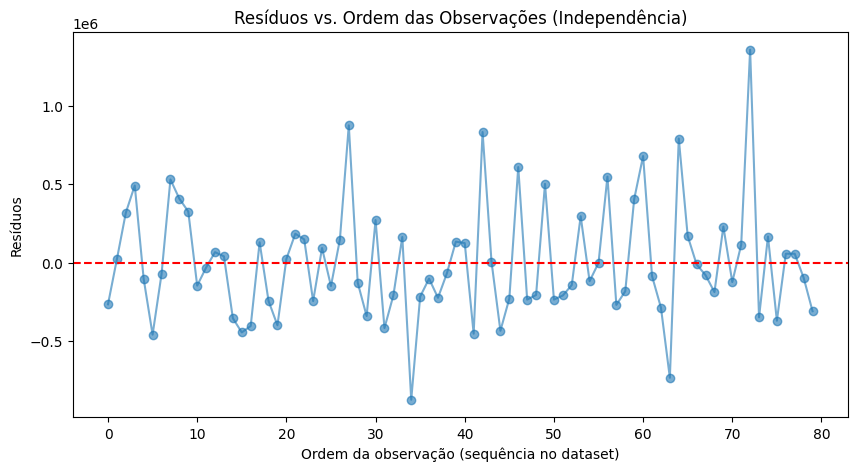


Teste de Shapiro-Wilk (Normalidade): estatística=0.9501, p-valor=0.0035


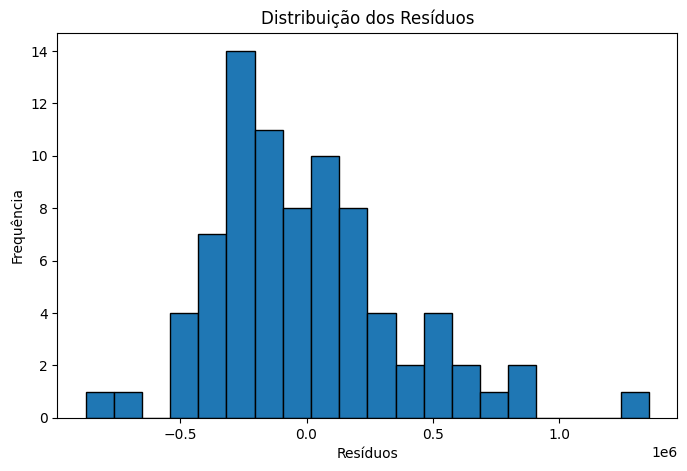

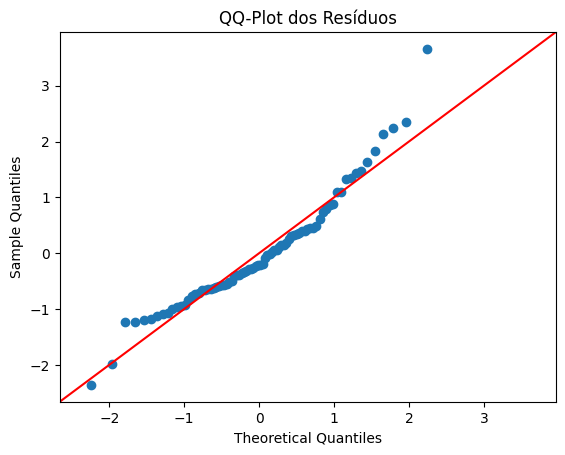


Fator de Inflação da Variância (VIF):
            Variável       VIF
0              const  1.000000
1        Talkability  3.004386
2         Buzz Score  1.038642
3              Views  3.040795
4  Tx de Engajamento  1.021791

Limite de referência para Distância de Cook (4/n): 0.0500

Casos com resíduo padronizado > |3| (outliers pelo critério de resíduo):
               Título/IP  Residuo_Padronizado  Distancia_Cook
34  Pra Sempre Paquitas             -3.579533        3.731221
72      Arcanjo Renegado             3.606917        0.096183

Casos com Distância de Cook acima do limite (observações influentes):
               Título/IP  Residuo_Padronizado  Distancia_Cook
3              Os Outros             1.407359        0.081551
34  Pra Sempre Paquitas             -3.579533        3.731221
63                Chaves            -2.116463        0.193971
72      Arcanjo Renegado             3.606917        0.096183

Diagnóstico específico para 'Arcanjo Renegado':
           Título/IP  Alca

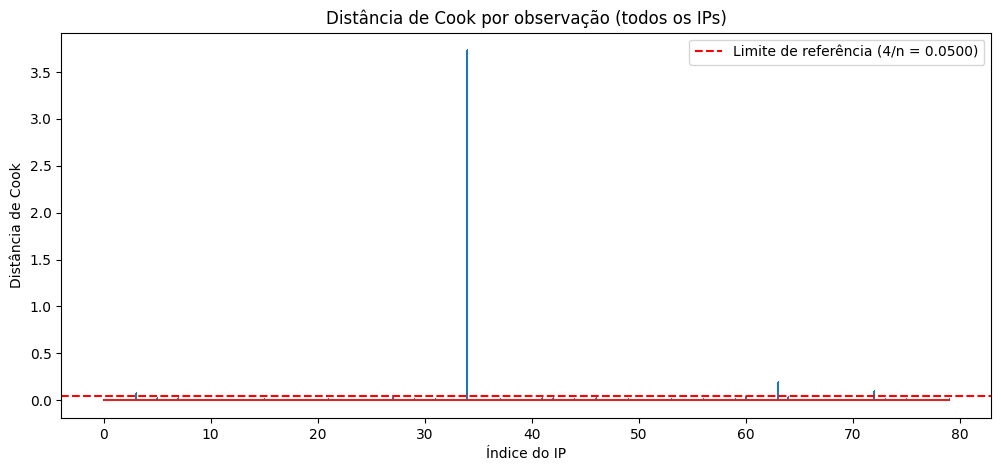


Resultados salvos em 'resultados_dissertacao.zip'


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [2]:
# ==============================================================
# REGRESSÃO LINEAR MÚLTIPLA — Dissertação (Conversação Social x Audiência Globoplay)
# Ambiente: Google Colab
# Bibliotecas: pandas + statsmodels
# ==============================================================

# --- 1. INSTALAÇÃO (rodar uma vez no Colab, se necessário) ---
# !pip install pandas statsmodels scipy matplotlib

import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson
from scipy import stats
import matplotlib.pyplot as plt

# --- 2. LEITURA DO ARQUIVO ---
# O arquivo já está no ambiente do Colab (barra lateral de arquivos),
# então basta ler direto pelo nome.
#
# Arquivos .csv exportados do Excel no Brasil podem ter dois problemas comuns:
# 1) Encoding diferente de UTF-8 (ex.: latin-1, cp1252)
# 2) Separador ";" em vez de "," -- e quando isso não é tratado, vírgulas
#    dentro de textos (ex. títulos de programas) quebram a leitura.
#
# O código abaixo tenta detectar automaticamente o separador correto (usando
# o engine "python", que consegue inferir o delimitador com sep=None),
# combinando com os encodings mais comuns.

nome_arquivo = "Base_IPsGloboplay.csv"

encodings_para_tentar = ["utf-8", "latin-1", "cp1252"]

df = None
erro_final = None
for enc in encodings_para_tentar:
    try:
        df = pd.read_csv(nome_arquivo, encoding=enc, sep=None, engine="python")
        print(f"Arquivo carregado com sucesso usando encoding: {enc}")
        print(f"Separador detectado automaticamente. Colunas encontradas: {list(df.columns)}")
        break
    except (UnicodeDecodeError, pd.errors.ParserError) as e:
        erro_final = e
        continue

if df is None:
    raise ValueError(
        f"Não foi possível ler o arquivo automaticamente. Último erro: {erro_final}\n"
        "Isso geralmente indica que alguma linha do arquivo está com vírgulas "
        "ou ponto-e-vírgulas inconsistentes dentro do texto (ex.: título de "
        "programa com vírgula sem estar entre aspas no CSV original). "
        "Abra o arquivo original no Excel e verifique a linha indicada no erro, "
        "ou reexporte o arquivo garantindo que campos de texto com vírgula "
        "estejam entre aspas."
    )

# Confira as primeiras linhas e os tipos de dado
print(df.head())
print(df.info())

# --- 3. DEFINIÇÃO DAS VARIÁVEIS ---
# Nomes das colunas exatamente como aparecem no arquivo original

variavel_dependente = "Alcance"

variaveis_independentes = [
    "Talkability",
    "Buzz Score",
    "Views",
    "Tx de Engajamento",
]

# --- 3.1 DIAGNÓSTICO E LIMPEZA DE TIPOS DE DADOS ---
# Dados brasileiros exportados do Excel costumam vir como TEXTO, não número,
# por causa de vírgula decimal (ex. "12,5"), símbolo de % (ex. "12,5%") ou
# ponto como separador de milhar (ex. "1.234"). Se isso não for corrigido,
# o statsmodels trata a coluna como categórica e o modelo quebra.

print("Tipos de dados ANTES da limpeza:")
print(df[variaveis_independentes + [variavel_dependente]].dtypes)

def limpar_numero_br(coluna):
    """Converte uma coluna de texto em formato numérico brasileiro para float.
    Trata: espaços, símbolo de %, ponto de milhar e vírgula decimal."""
    if coluna.dtype == object:
        coluna = (
            coluna.astype(str)
            .str.strip()
            .str.replace("%", "", regex=False)
            .str.replace(".", "", regex=False)   # remove ponto de milhar
            .str.replace(",", ".", regex=False)   # vírgula -> ponto decimal
        )
        coluna = pd.to_numeric(coluna, errors="coerce")
    return coluna

for col in variaveis_independentes + [variavel_dependente]:
    df[col] = limpar_numero_br(df[col])

print("\nTipos de dados DEPOIS da limpeza:")
print(df[variaveis_independentes + [variavel_dependente]].dtypes)

# Se a limpeza gerou algum valor ausente (NaN) por não conseguir converter,
# isso aparece aqui -- vale checar antes de seguir:
print("\nValores que viraram NaN após a limpeza (se houver, investigue a fonte):")
print(df[variaveis_independentes + [variavel_dependente]].isnull().sum())

# --- 3.2 ANÁLISE DESCRITIVA DOS DADOS ---
# Estatísticas descritivas (média, mediana, desvio padrão, mínimo, máximo,
# quartis) e visualização da distribuição de cada variável, antes de rodar
# o modelo de regressão. Essa etapa costuma abrir a seção de Resultados,
# caracterizando a amostra antes de entrar na análise inferencial.

todas_variaveis_descritiva = [variavel_dependente] + variaveis_independentes

# Tabela de estatísticas descritivas
estatisticas_descritivas = df[todas_variaveis_descritiva].describe().T
estatisticas_descritivas["mediana"] = df[todas_variaveis_descritiva].median()
estatisticas_descritivas = estatisticas_descritivas[
    ["count", "mean", "mediana", "std", "min", "25%", "50%", "75%", "max"]
]
estatisticas_descritivas.columns = [
    "N", "Média", "Mediana", "Desvio Padrão", "Mínimo",
    "1º Quartil", "2º Quartil", "3º Quartil", "Máximo"
]

print("=" * 78)
print("ESTATÍSTICAS DESCRITIVAS")
print("=" * 78)
print(estatisticas_descritivas.round(2))

# Salvar a tabela descritiva em CSV (útil para colar direto numa tabela ABNT)
estatisticas_descritivas.round(2).to_csv("estatisticas_descritivas.csv")
print("\nTabela salva em 'estatisticas_descritivas.csv'")

# --- 3.3 HISTOGRAMAS — DISTRIBUIÇÃO DE CADA VARIÁVEL ---
fig, eixos = plt.subplots(2, 3, figsize=(16, 9))
eixos = eixos.flatten()

for i, col in enumerate(todas_variaveis_descritiva):
    eixos[i].hist(df[col], bins=15, edgecolor="black", color="#4C72B0")
    eixos[i].axvline(df[col].mean(), color="red", linestyle="--", label="Média")
    eixos[i].axvline(df[col].median(), color="green", linestyle="--", label="Mediana")
    eixos[i].set_title(col)
    eixos[i].set_xlabel("Valor")
    eixos[i].set_ylabel("Frequência")
    eixos[i].legend(fontsize=8)

# Remove eixo extra não utilizado (5 variáveis em grade 2x3 = 1 espaço sobra)
for j in range(len(todas_variaveis_descritiva), len(eixos)):
    fig.delaxes(eixos[j])

plt.tight_layout()
plt.suptitle("Distribuição das Variáveis", y=1.02, fontsize=14)
plt.savefig("histogramas_distribuicao.png", bbox_inches="tight", dpi=150)
plt.show()

# --- 3.4 BOXPLOTS — VISUALIZAR DISPERSÃO E OUTLIERS POR VARIÁVEL ---
fig, eixos = plt.subplots(2, 3, figsize=(16, 9))
eixos = eixos.flatten()

for i, col in enumerate(todas_variaveis_descritiva):
    eixos[i].boxplot(df[col], vert=True)
    eixos[i].set_title(col)
    eixos[i].set_ylabel("Valor")

for j in range(len(todas_variaveis_descritiva), len(eixos)):
    fig.delaxes(eixos[j])

plt.tight_layout()
plt.suptitle("Dispersão e Outliers por Variável (Boxplot)", y=1.02, fontsize=14)
plt.savefig("boxplots_variaveis.png", bbox_inches="tight", dpi=150)
plt.show()

# --- 4. VERIFICAÇÃO DE DADOS FALTANTES ---
print("\nValores ausentes por coluna:")
print(df[[variavel_dependente] + variaveis_independentes].isnull().sum())

# Remova ou trate linhas com dados faltantes antes de seguir, se houver
df = df.dropna(subset=[variavel_dependente] + variaveis_independentes)

# --- 5. ESTIMAÇÃO DO MODELO DE REGRESSÃO MÚLTIPLA ---
# Usando a interface de fórmula do statsmodels (mais legível)
# Como os nomes das colunas têm espaços/parênteses, é preciso "escapar"
# cada nome com Q("...") para a fórmula funcionar corretamente.

def escapar(nome_coluna):
    return f'Q("{nome_coluna}")'

formula = f"{escapar(variavel_dependente)} ~ " + " + ".join(
    escapar(v) for v in variaveis_independentes
)
modelo = smf.ols(formula=formula, data=df).fit()

# --- 6. SAÍDA COMPLETA DO MODELO ---
# Isto já traz: coeficientes, erro padrão, valores-t, p-valores, R², R² ajustado, F-estatística
print(modelo.summary())

# --- 6.1 MODELO PADRONIZADO (Z-SCORE) — para resolver problema de escala ---
# O número de condição alto (Cond. No.) no modelo acima geralmente indica que
# as variáveis estão em escalas muito diferentes entre si (ex. Talkability em
# unidades pequenas vs. Alcance na casa de centenas de milhares), e não
# necessariamente multicolinearidade real.
#
# Padronizar (transformar cada variável para média 0 e desvio padrão 1) resolve
# o problema numérico E torna os coeficientes comparáveis entre si — o maior
# coeficiente padronizado indica a variável com maior peso relativo no modelo.

from scipy.stats import zscore

df_padronizado = df.copy()
todas_variaveis = [variavel_dependente] + variaveis_independentes

for col in todas_variaveis:
    df_padronizado[col] = zscore(df_padronizado[col])

formula_padronizada = f"{escapar(variavel_dependente)} ~ " + " + ".join(
    escapar(v) for v in variaveis_independentes
)
modelo_padronizado = smf.ols(formula=formula_padronizada, data=df_padronizado).fit()

print("\n" + "=" * 78)
print("MODELO PADRONIZADO (coeficientes comparáveis entre si)")
print("=" * 78)
print(modelo_padronizado.summary())

# --- 7. TESTES DE PRESSUPOSTOS ---

# 7.1 Linearidade e Homocedasticidade — gráfico de resíduos vs. valores ajustados
plt.figure(figsize=(8, 5))
plt.scatter(modelo.fittedvalues, modelo.resid, alpha=0.6)
plt.axhline(y=0, color="red", linestyle="--")
plt.xlabel("Valores ajustados")
plt.ylabel("Resíduos")
plt.title("Resíduos vs. Valores Ajustados (Linearidade/Homocedasticidade)")
plt.savefig("residuos_vs_ajustados.png", bbox_inches="tight", dpi=150)
plt.show()

# 7.2 Homocedasticidade — Teste de Breusch-Pagan
# H0: homocedasticidade (variância constante) — p > 0,05 é o resultado desejado
bp_test = het_breuschpagan(modelo.resid, modelo.model.exog)
labels = ["LM Statistic", "LM p-value", "F-Statistic", "F p-value"]
print("\nTeste de Breusch-Pagan (Homocedasticidade):")
print(dict(zip(labels, bp_test)))

# 7.3 Independência dos resíduos — Durbin-Watson
# Valores próximos de 2 indicam ausência de autocorrelação
dw = durbin_watson(modelo.resid)
print(f"\nDurbin-Watson: {dw:.3f} (ideal: próximo de 2)")

# Gráfico de resíduos vs. ordem das observações (checagem visual de independência)
# Pressupõe que a ordem das linhas no dataset é significativa (ex. ordem
# cronológica de lançamento) -- o mesmo pressuposto do teste de Durbin-Watson.
plt.figure(figsize=(10, 5))
plt.plot(range(len(modelo.resid)), modelo.resid, marker="o", linestyle="-", alpha=0.6)
plt.axhline(y=0, color="red", linestyle="--")
plt.xlabel("Ordem da observação (sequência no dataset)")
plt.ylabel("Resíduos")
plt.title("Resíduos vs. Ordem das Observações (Independência)")
plt.savefig("residuos_vs_ordem.png", bbox_inches="tight", dpi=150)
plt.show()

# 7.4 Normalidade dos resíduos — Shapiro-Wilk
# H0: resíduos seguem distribuição normal — p > 0,05 é o resultado desejado
shapiro_test = stats.shapiro(modelo.resid)
print(f"\nTeste de Shapiro-Wilk (Normalidade): estatística={shapiro_test[0]:.4f}, p-valor={shapiro_test[1]:.4f}")

# Histograma dos resíduos (inspeção visual da normalidade)
plt.figure(figsize=(8, 5))
plt.hist(modelo.resid, bins=20, edgecolor="black")
plt.xlabel("Resíduos")
plt.ylabel("Frequência")
plt.title("Distribuição dos Resíduos")
plt.savefig("histograma_residuos.png", bbox_inches="tight", dpi=150)
plt.show()

# QQ-plot (outra forma visual de checar normalidade)
sm.qqplot(modelo.resid, line="45", fit=True)
plt.title("QQ-Plot dos Resíduos")
plt.savefig("qqplot_residuos.png", bbox_inches="tight", dpi=150)
plt.show()

# 7.5 Multicolinearidade — VIF (Fator de Inflação da Variância)
# Importante quando há mais de uma variável independente (seu caso)
from statsmodels.stats.outliers_influence import variance_inflation_factor

X = sm.add_constant(df[variaveis_independentes])
vif_data = pd.DataFrame()
vif_data["Variável"] = X.columns
vif_data["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
print("\nFator de Inflação da Variância (VIF):")
print(vif_data)
# Regra prática: VIF > 10 indica problema sério de multicolinearidade

# --- 7.6 DIAGNÓSTICO DE OUTLIERS E OBSERVAÇÕES INFLUENTES ---
# Antes de remover qualquer caso do modelo, é preciso justificativa estatística
# objetiva — não basta "achar" que um caso é outlier. Duas métricas padrão:
#
# 1) Resíduo padronizado: valores acima de |3| (ou às vezes |2|) indicam que
#    aquele caso está muito distante do que o modelo previu.
# 2) Distância de Cook: mede o quanto aquele caso, sozinho, influencia as
#    estimativas do modelo. Regra prática: valores acima de 4/n são notáveis.

influence = modelo.get_influence()
residuos_padronizados = influence.resid_studentized_internal
distancia_cook = influence.cooks_distance[0]

diagnostico = df.copy()
diagnostico["Residuo_Padronizado"] = residuos_padronizados
diagnostico["Distancia_Cook"] = distancia_cook

limite_cook = 4 / len(df)

print(f"\nLimite de referência para Distância de Cook (4/n): {limite_cook:.4f}")
print("\nCasos com resíduo padronizado > |3| (outliers pelo critério de resíduo):")
print(diagnostico[diagnostico["Residuo_Padronizado"].abs() > 3][
    ["Título/IP", "Residuo_Padronizado", "Distancia_Cook"]
])

print("\nCasos com Distância de Cook acima do limite (observações influentes):")
print(diagnostico[diagnostico["Distancia_Cook"] > limite_cook][
    ["Título/IP", "Residuo_Padronizado", "Distancia_Cook"]
])

# Para checar um IP específico (ex. "Arcanjo Renegado"), use:
ip_para_checar = "Arcanjo Renegado"
print(f"\nDiagnóstico específico para '{ip_para_checar}':")
print(diagnostico[diagnostico["Título/IP"] == ip_para_checar][
    ["Título/IP", variavel_dependente, "Residuo_Padronizado", "Distancia_Cook"]
])

# --- 7.7 DISTÂNCIA DE COOK — TODOS OS 80 IPs, ORDENADOS DO MAIS INFLUENTE ---
# Visão completa para identificar rapidamente se há outros candidatos a
# observação influente além do que já foi identificado manualmente.

tabela_cook_completa = diagnostico[
    ["Título/IP", variavel_dependente, "Residuo_Padronizado", "Distancia_Cook"]
].sort_values("Distancia_Cook", ascending=False).reset_index(drop=True)

print("\n" + "=" * 78)
print("DISTÂNCIA DE COOK — TODOS OS IPs (ordenado do mais para o menos influente)")
print("=" * 78)
print(tabela_cook_completa.to_string())

# Gráfico de distância de Cook por observação (facilita visualizar outliers)
plt.figure(figsize=(12, 5))
plt.stem(range(len(diagnostico)), diagnostico["Distancia_Cook"], markerfmt=",")
plt.axhline(y=limite_cook, color="red", linestyle="--",
            label=f"Limite de referência (4/n = {limite_cook:.4f})")
plt.xlabel("Índice do IP")
plt.ylabel("Distância de Cook")
plt.title("Distância de Cook por observação (todos os IPs)")
plt.legend()
plt.show()

# --- 8. EXPORTAR TODOS OS RESULTADOS (um único .zip para baixar) ---
# Junta num só arquivo de texto: modelo original, modelo padronizado, testes
# de pressupostos, VIF e a lista de observações influentes. Também salva a
# tabela de Cook e o VIF em CSV e empacota tudo (com os gráficos .png que o
# script já salvou) em "resultados_dissertacao.zip".

import os
import zipfile

with open("resultado_regressao.txt", "w", encoding="utf-8") as f:
    f.write("MODELO ORIGINAL (escala bruta)\n")
    f.write(modelo.summary().as_text())

    f.write("\n\n" + "=" * 78 + "\n")
    f.write("MODELO PADRONIZADO (z-score)\n")
    f.write("=" * 78 + "\n")
    f.write(modelo_padronizado.summary().as_text())

    f.write("\n\n" + "=" * 78 + "\n")
    f.write("TESTES DE PRESSUPOSTOS\n")
    f.write("=" * 78 + "\n")
    f.write("Breusch-Pagan (homocedasticidade):\n")
    for nome, valor in zip(labels, bp_test):
        f.write(f"  {nome}: {valor:.6f}\n")
    f.write(f"\nDurbin-Watson: {dw:.3f}\n")
    f.write(
        f"\nShapiro-Wilk (normalidade): estatística={shapiro_test[0]:.4f}, "
        f"p-valor={shapiro_test[1]:.4f}\n"
    )

    f.write("\n" + "=" * 78 + "\n")
    f.write("VIF (multicolinearidade)\n")
    f.write("=" * 78 + "\n")
    f.write(vif_data.to_string(index=False))

    f.write("\n\n" + "=" * 78 + "\n")
    f.write(f"OBSERVAÇÕES INFLUENTES (Distância de Cook > 4/n = {limite_cook:.4f})\n")
    f.write("=" * 78 + "\n")
    f.write(
        diagnostico[diagnostico["Distancia_Cook"] > limite_cook][
            ["Título/IP", variavel_dependente, "Residuo_Padronizado", "Distancia_Cook"]
        ].to_string()
    )

# Tabelas em CSV (fáceis de abrir no Excel)
vif_data.to_csv("vif.csv", index=False)
tabela_cook_completa.to_csv("distancia_cook_todos_ips.csv", index=False)

# Empacota tudo num único .zip (só inclui o que existir na pasta)
arquivos_para_zip = [
    "resultado_regressao.txt",
    "vif.csv",
    "distancia_cook_todos_ips.csv",
    "estatisticas_descritivas.csv",
    "histogramas_distribuicao.png",
    "boxplots_variaveis.png",
    "residuos_vs_ajustados.png",
    "residuos_vs_ordem.png",
    "histograma_residuos.png",
    "qqplot_residuos.png",
]

with zipfile.ZipFile("resultados_dissertacao.zip", "w") as zf:
    for arquivo in arquivos_para_zip:
        if os.path.exists(arquivo):
            zf.write(arquivo)

print("\nResultados salvos em 'resultados_dissertacao.zip'")

# Baixa o .zip automaticamente para o seu computador
from google.colab import files
files.download("resultados_dissertacao.zip")


Arquivo carregado com sucesso usando encoding: latin-1
Separador detectado automaticamente. Colunas encontradas: ['Título/IP', 'Temporada', 'Lançamento', 'Território', 'Gênero Principal', 'Classe', 'Vertical', 'Formato', 'Episódios', 'Alcance', 'Buzz Score', 'Talkability', 'Posts', 'Views', 'Views por post', 'Tx de Engajamento']
                        Título/IP  Temporada  Lançamento   Território  \
0                         As Five          2  08/02/2023  dramaturgia   
1                          Origem          1  21/03/2023  dramaturgia   
2  The Good Doctor - O Bom Doutor          6  21/04/2023  dramaturgia   
3                       Os Outros          1  31/05/2023  dramaturgia   
4              A Vida Pela Frente          1  22/06/2023  dramaturgia   

    Gênero Principal      Classe        Vertical Formato  Episódios  Alcance  \
0              Drama    original  Entretenimento  séries          8   586125   
1  Suspense/Thriller  licenciado  Entretenimento  séries         10   

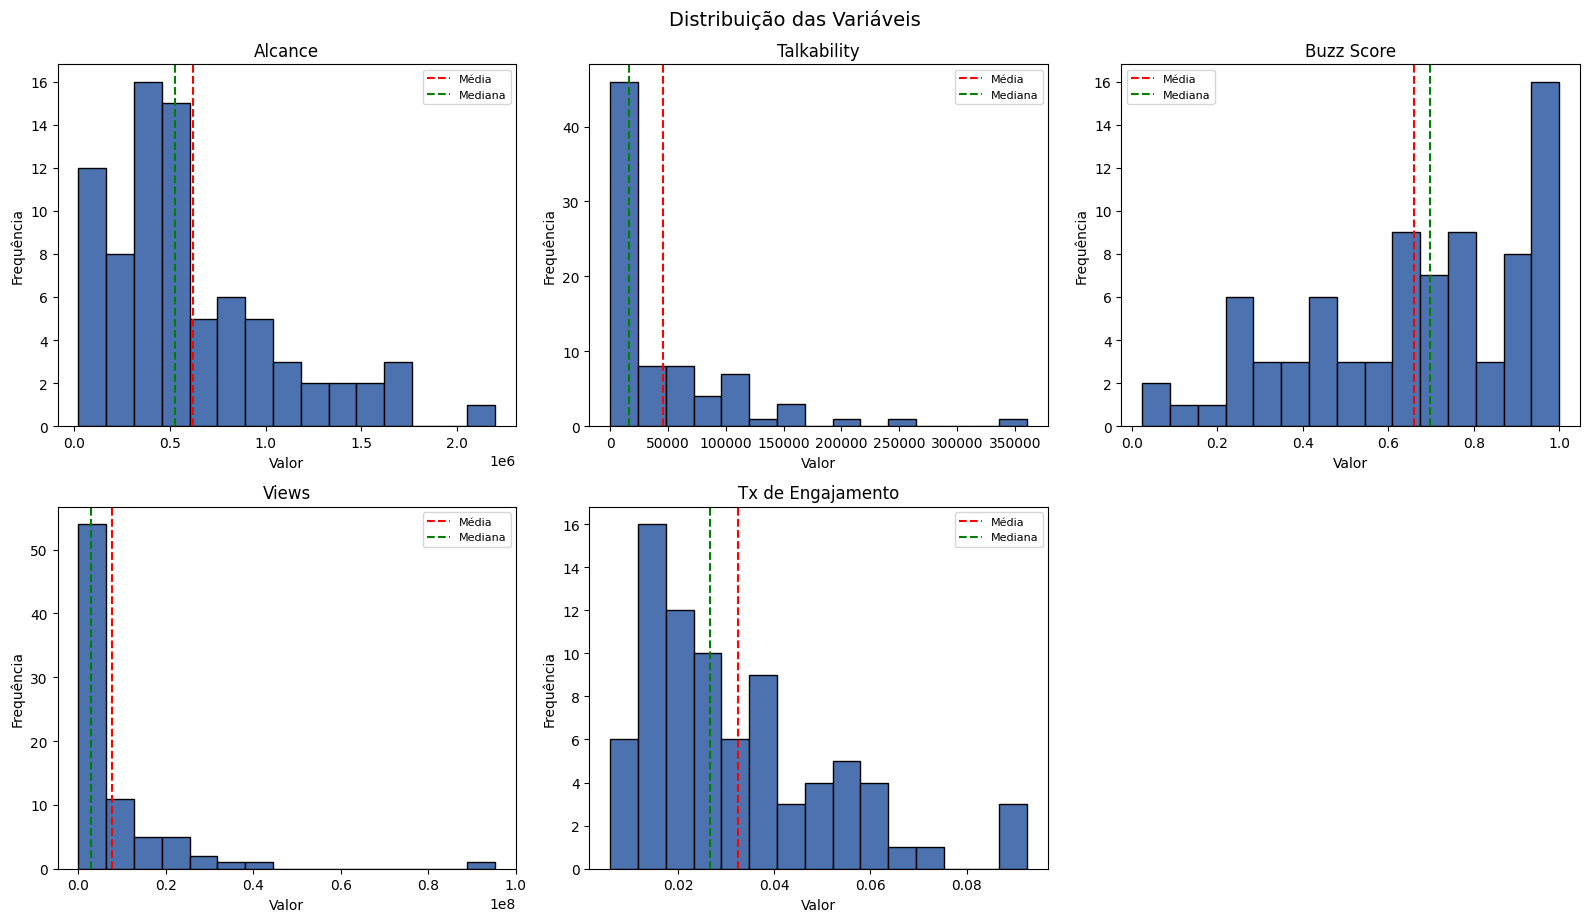

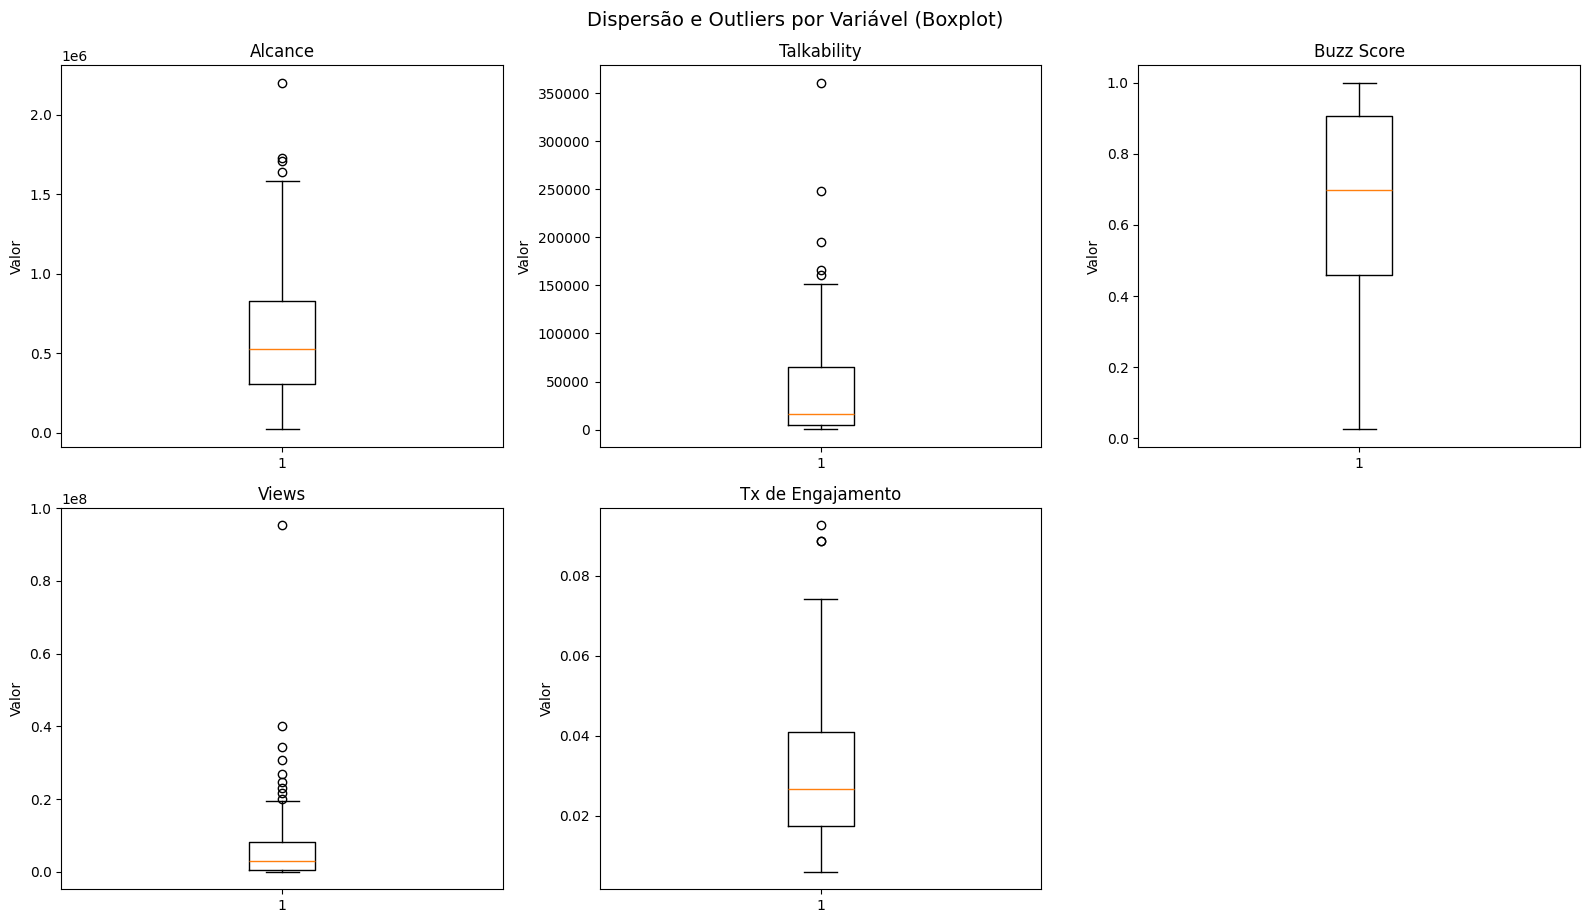


Valores ausentes por coluna:
Alcance              0
Talkability          0
Buzz Score           0
Views                0
Tx de Engajamento    0
dtype: int64
                            OLS Regression Results                            
Dep. Variable:           Q("Alcance")   R-squared:                       0.341
Model:                            OLS   Adj. R-squared:                  0.306
Method:                 Least Squares   F-statistic:                     9.692
Date:                Tue, 10 Nov 2026   Prob (F-statistic):           2.26e-06
Time:                        17:08:29   Log-Likelihood:                -1139.5
No. Observations:                  80   AIC:                             2289.
Df Residuals:                      75   BIC:                             2301.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                             coef    std err        

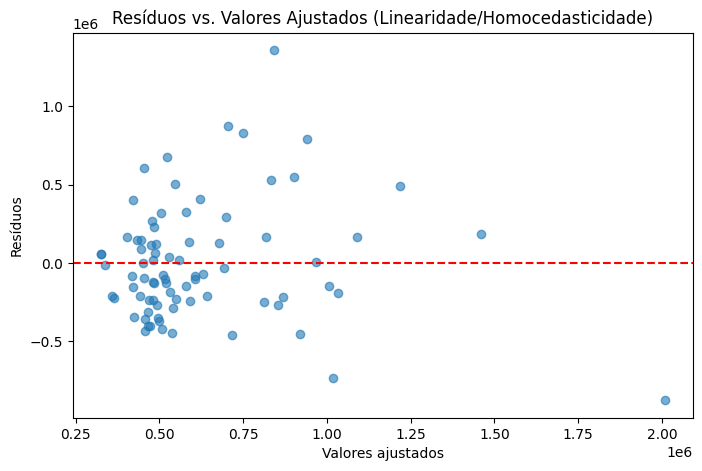


Teste de Breusch-Pagan (Homocedasticidade):
{'LM Statistic': np.float64(11.888745992762209), 'LM p-value': np.float64(0.018198041409571035), 'F-Statistic': np.float64(3.2727922956844044), 'F p-value': np.float64(0.015761118944370565)}

Durbin-Watson: 2.115 (ideal: próximo de 2)


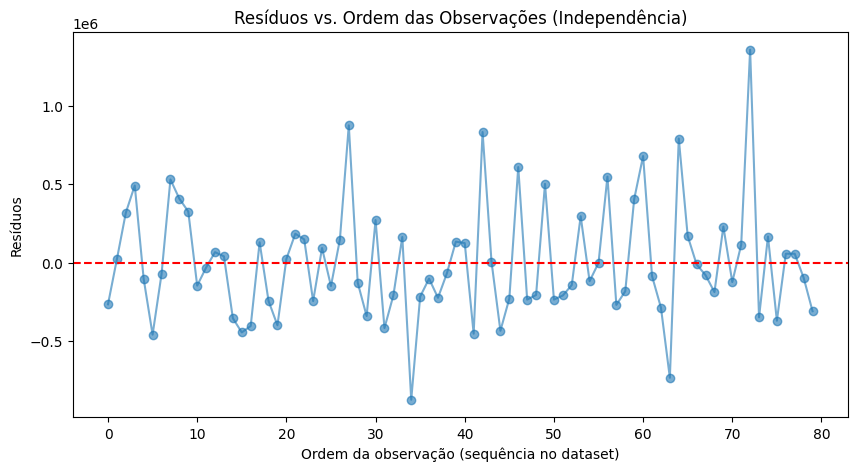


Teste de Shapiro-Wilk (Normalidade): estatística=0.9501, p-valor=0.0035


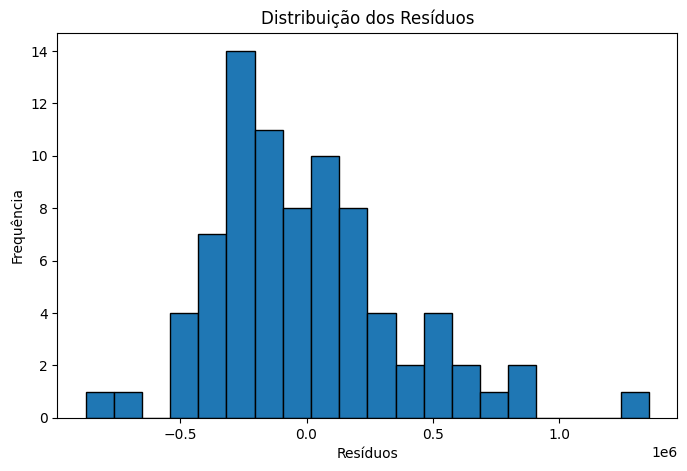

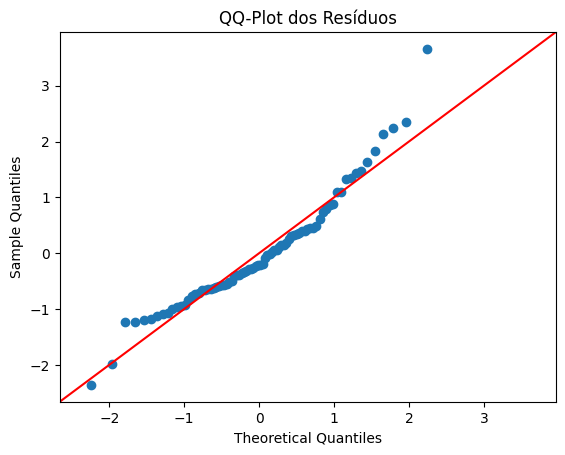


Fator de Inflação da Variância (VIF):
            Variável       VIF
0              const  1.000000
1        Talkability  3.004386
2         Buzz Score  1.038642
3              Views  3.040795
4  Tx de Engajamento  1.021791

Limite de referência para Distância de Cook (4/n): 0.0500

Casos com resíduo padronizado > |3| (outliers pelo critério de resíduo):
               Título/IP  Residuo_Padronizado  Distancia_Cook
34  Pra Sempre Paquitas             -3.579533        3.731221
72      Arcanjo Renegado             3.606917        0.096183

Casos com Distância de Cook acima do limite (observações influentes):
               Título/IP  Residuo_Padronizado  Distancia_Cook
3              Os Outros             1.407359        0.081551
34  Pra Sempre Paquitas             -3.579533        3.731221
63                Chaves            -2.116463        0.193971
72      Arcanjo Renegado             3.606917        0.096183

Diagnóstico específico para 'Arcanjo Renegado':
           Título/IP  Alca

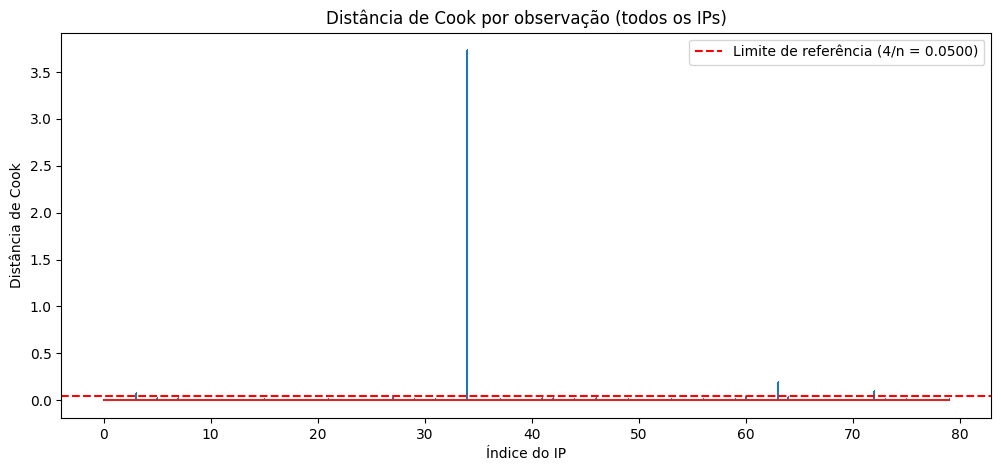


ANÁLISE DE SENSIBILIDADE — SEM 'Pra Sempre Paquitas'
Observações removidas: 0 | Amostra: 80 IPs
ATENÇÃO: era esperado remover exatamente 1 observação. Confira o nome do IP na coluna 'Título/IP'.

MODELO ORIGINAL SEM O IP:
                            OLS Regression Results                            
Dep. Variable:           Q("Alcance")   R-squared:                       0.341
Model:                            OLS   Adj. R-squared:                  0.306
Method:                 Least Squares   F-statistic:                     9.692
Date:                Tue, 10 Nov 2026   Prob (F-statistic):           2.26e-06
Time:                        17:08:31   Log-Likelihood:                -1139.5
No. Observations:                  80   AIC:                             2289.
Df Residuals:                      75   BIC:                             2301.
Df Model:                           4                                         
Covariance Type:            nonrobust                             

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [3]:
# ==============================================================
# REGRESSÃO LINEAR MÚLTIPLA — Dissertação (Conversação Social x Audiência Globoplay)
# Ambiente: Google Colab
# Bibliotecas: pandas + statsmodels
# ==============================================================

# --- 1. INSTALAÇÃO (rodar uma vez no Colab, se necessário) ---
# !pip install pandas statsmodels scipy matplotlib

import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson
from scipy import stats
import matplotlib.pyplot as plt

# --- 2. LEITURA DO ARQUIVO ---
# O arquivo já está no ambiente do Colab (barra lateral de arquivos),
# então basta ler direto pelo nome.
#
# Arquivos .csv exportados do Excel no Brasil podem ter dois problemas comuns:
# 1) Encoding diferente de UTF-8 (ex.: latin-1, cp1252)
# 2) Separador ";" em vez de "," -- e quando isso não é tratado, vírgulas
#    dentro de textos (ex. títulos de programas) quebram a leitura.
#
# O código abaixo tenta detectar automaticamente o separador correto (usando
# o engine "python", que consegue inferir o delimitador com sep=None),
# combinando com os encodings mais comuns.

nome_arquivo = "Base_IPsGloboplay.csv"

encodings_para_tentar = ["utf-8", "latin-1", "cp1252"]

df = None
erro_final = None
for enc in encodings_para_tentar:
    try:
        df = pd.read_csv(nome_arquivo, encoding=enc, sep=None, engine="python")
        print(f"Arquivo carregado com sucesso usando encoding: {enc}")
        print(f"Separador detectado automaticamente. Colunas encontradas: {list(df.columns)}")
        break
    except (UnicodeDecodeError, pd.errors.ParserError) as e:
        erro_final = e
        continue

if df is None:
    raise ValueError(
        f"Não foi possível ler o arquivo automaticamente. Último erro: {erro_final}\n"
        "Isso geralmente indica que alguma linha do arquivo está com vírgulas "
        "ou ponto-e-vírgulas inconsistentes dentro do texto (ex.: título de "
        "programa com vírgula sem estar entre aspas no CSV original). "
        "Abra o arquivo original no Excel e verifique a linha indicada no erro, "
        "ou reexporte o arquivo garantindo que campos de texto com vírgula "
        "estejam entre aspas."
    )

# Confira as primeiras linhas e os tipos de dado
print(df.head())
print(df.info())

# --- 3. DEFINIÇÃO DAS VARIÁVEIS ---
# Nomes das colunas exatamente como aparecem no arquivo original

variavel_dependente = "Alcance"

variaveis_independentes = [
    "Talkability",
    "Buzz Score",
    "Views",
    "Tx de Engajamento",
]

# --- 3.1 DIAGNÓSTICO E LIMPEZA DE TIPOS DE DADOS ---
# Dados brasileiros exportados do Excel costumam vir como TEXTO, não número,
# por causa de vírgula decimal (ex. "12,5"), símbolo de % (ex. "12,5%") ou
# ponto como separador de milhar (ex. "1.234"). Se isso não for corrigido,
# o statsmodels trata a coluna como categórica e o modelo quebra.

print("Tipos de dados ANTES da limpeza:")
print(df[variaveis_independentes + [variavel_dependente]].dtypes)

def limpar_numero_br(coluna):
    """Converte uma coluna de texto em formato numérico brasileiro para float.
    Trata: espaços, símbolo de %, ponto de milhar e vírgula decimal."""
    if coluna.dtype == object:
        coluna = (
            coluna.astype(str)
            .str.strip()
            .str.replace("%", "", regex=False)
            .str.replace(".", "", regex=False)   # remove ponto de milhar
            .str.replace(",", ".", regex=False)   # vírgula -> ponto decimal
        )
        coluna = pd.to_numeric(coluna, errors="coerce")
    return coluna

for col in variaveis_independentes + [variavel_dependente]:
    df[col] = limpar_numero_br(df[col])

print("\nTipos de dados DEPOIS da limpeza:")
print(df[variaveis_independentes + [variavel_dependente]].dtypes)

# Se a limpeza gerou algum valor ausente (NaN) por não conseguir converter,
# isso aparece aqui -- vale checar antes de seguir:
print("\nValores que viraram NaN após a limpeza (se houver, investigue a fonte):")
print(df[variaveis_independentes + [variavel_dependente]].isnull().sum())

# --- 3.2 ANÁLISE DESCRITIVA DOS DADOS ---
# Estatísticas descritivas (média, mediana, desvio padrão, mínimo, máximo,
# quartis) e visualização da distribuição de cada variável, antes de rodar
# o modelo de regressão. Essa etapa costuma abrir a seção de Resultados,
# caracterizando a amostra antes de entrar na análise inferencial.

todas_variaveis_descritiva = [variavel_dependente] + variaveis_independentes

# Tabela de estatísticas descritivas
estatisticas_descritivas = df[todas_variaveis_descritiva].describe().T
estatisticas_descritivas["mediana"] = df[todas_variaveis_descritiva].median()
estatisticas_descritivas = estatisticas_descritivas[
    ["count", "mean", "mediana", "std", "min", "25%", "50%", "75%", "max"]
]
estatisticas_descritivas.columns = [
    "N", "Média", "Mediana", "Desvio Padrão", "Mínimo",
    "1º Quartil", "2º Quartil", "3º Quartil", "Máximo"
]

print("=" * 78)
print("ESTATÍSTICAS DESCRITIVAS")
print("=" * 78)
print(estatisticas_descritivas.round(2))

# Salvar a tabela descritiva em CSV (útil para colar direto numa tabela ABNT)
estatisticas_descritivas.round(2).to_csv("estatisticas_descritivas.csv")
print("\nTabela salva em 'estatisticas_descritivas.csv'")

# --- 3.3 HISTOGRAMAS — DISTRIBUIÇÃO DE CADA VARIÁVEL ---
fig, eixos = plt.subplots(2, 3, figsize=(16, 9))
eixos = eixos.flatten()

for i, col in enumerate(todas_variaveis_descritiva):
    eixos[i].hist(df[col], bins=15, edgecolor="black", color="#4C72B0")
    eixos[i].axvline(df[col].mean(), color="red", linestyle="--", label="Média")
    eixos[i].axvline(df[col].median(), color="green", linestyle="--", label="Mediana")
    eixos[i].set_title(col)
    eixos[i].set_xlabel("Valor")
    eixos[i].set_ylabel("Frequência")
    eixos[i].legend(fontsize=8)

# Remove eixo extra não utilizado (5 variáveis em grade 2x3 = 1 espaço sobra)
for j in range(len(todas_variaveis_descritiva), len(eixos)):
    fig.delaxes(eixos[j])

plt.tight_layout()
plt.suptitle("Distribuição das Variáveis", y=1.02, fontsize=14)
plt.savefig("histogramas_distribuicao.png", bbox_inches="tight", dpi=150)
plt.show()

# --- 3.4 BOXPLOTS — VISUALIZAR DISPERSÃO E OUTLIERS POR VARIÁVEL ---
fig, eixos = plt.subplots(2, 3, figsize=(16, 9))
eixos = eixos.flatten()

for i, col in enumerate(todas_variaveis_descritiva):
    eixos[i].boxplot(df[col], vert=True)
    eixos[i].set_title(col)
    eixos[i].set_ylabel("Valor")

for j in range(len(todas_variaveis_descritiva), len(eixos)):
    fig.delaxes(eixos[j])

plt.tight_layout()
plt.suptitle("Dispersão e Outliers por Variável (Boxplot)", y=1.02, fontsize=14)
plt.savefig("boxplots_variaveis.png", bbox_inches="tight", dpi=150)
plt.show()

# --- 4. VERIFICAÇÃO DE DADOS FALTANTES ---
print("\nValores ausentes por coluna:")
print(df[[variavel_dependente] + variaveis_independentes].isnull().sum())

# Remova ou trate linhas com dados faltantes antes de seguir, se houver
df = df.dropna(subset=[variavel_dependente] + variaveis_independentes)

# --- 5. ESTIMAÇÃO DO MODELO DE REGRESSÃO MÚLTIPLA ---
# Usando a interface de fórmula do statsmodels (mais legível)
# Como os nomes das colunas têm espaços/parênteses, é preciso "escapar"
# cada nome com Q("...") para a fórmula funcionar corretamente.

def escapar(nome_coluna):
    return f'Q("{nome_coluna}")'

formula = f"{escapar(variavel_dependente)} ~ " + " + ".join(
    escapar(v) for v in variaveis_independentes
)
modelo = smf.ols(formula=formula, data=df).fit()

# --- 6. SAÍDA COMPLETA DO MODELO ---
# Isto já traz: coeficientes, erro padrão, valores-t, p-valores, R², R² ajustado, F-estatística
print(modelo.summary())

# --- 6.1 MODELO PADRONIZADO (Z-SCORE) — para resolver problema de escala ---
# O número de condição alto (Cond. No.) no modelo acima geralmente indica que
# as variáveis estão em escalas muito diferentes entre si (ex. Talkability em
# unidades pequenas vs. Alcance na casa de centenas de milhares), e não
# necessariamente multicolinearidade real.
#
# Padronizar (transformar cada variável para média 0 e desvio padrão 1) resolve
# o problema numérico E torna os coeficientes comparáveis entre si — o maior
# coeficiente padronizado indica a variável com maior peso relativo no modelo.

from scipy.stats import zscore

df_padronizado = df.copy()
todas_variaveis = [variavel_dependente] + variaveis_independentes

for col in todas_variaveis:
    df_padronizado[col] = zscore(df_padronizado[col])

formula_padronizada = f"{escapar(variavel_dependente)} ~ " + " + ".join(
    escapar(v) for v in variaveis_independentes
)
modelo_padronizado = smf.ols(formula=formula_padronizada, data=df_padronizado).fit()

print("\n" + "=" * 78)
print("MODELO PADRONIZADO (coeficientes comparáveis entre si)")
print("=" * 78)
print(modelo_padronizado.summary())

# --- 7. TESTES DE PRESSUPOSTOS ---

# 7.1 Linearidade e Homocedasticidade — gráfico de resíduos vs. valores ajustados
plt.figure(figsize=(8, 5))
plt.scatter(modelo.fittedvalues, modelo.resid, alpha=0.6)
plt.axhline(y=0, color="red", linestyle="--")
plt.xlabel("Valores ajustados")
plt.ylabel("Resíduos")
plt.title("Resíduos vs. Valores Ajustados (Linearidade/Homocedasticidade)")
plt.savefig("residuos_vs_ajustados.png", bbox_inches="tight", dpi=150)
plt.show()

# 7.2 Homocedasticidade — Teste de Breusch-Pagan
# H0: homocedasticidade (variância constante) — p > 0,05 é o resultado desejado
bp_test = het_breuschpagan(modelo.resid, modelo.model.exog)
labels = ["LM Statistic", "LM p-value", "F-Statistic", "F p-value"]
print("\nTeste de Breusch-Pagan (Homocedasticidade):")
print(dict(zip(labels, bp_test)))

# 7.3 Independência dos resíduos — Durbin-Watson
# Valores próximos de 2 indicam ausência de autocorrelação
dw = durbin_watson(modelo.resid)
print(f"\nDurbin-Watson: {dw:.3f} (ideal: próximo de 2)")

# Gráfico de resíduos vs. ordem das observações (checagem visual de independência)
# Pressupõe que a ordem das linhas no dataset é significativa (ex. ordem
# cronológica de lançamento) -- o mesmo pressuposto do teste de Durbin-Watson.
plt.figure(figsize=(10, 5))
plt.plot(range(len(modelo.resid)), modelo.resid, marker="o", linestyle="-", alpha=0.6)
plt.axhline(y=0, color="red", linestyle="--")
plt.xlabel("Ordem da observação (sequência no dataset)")
plt.ylabel("Resíduos")
plt.title("Resíduos vs. Ordem das Observações (Independência)")
plt.savefig("residuos_vs_ordem.png", bbox_inches="tight", dpi=150)
plt.show()

# 7.4 Normalidade dos resíduos — Shapiro-Wilk
# H0: resíduos seguem distribuição normal — p > 0,05 é o resultado desejado
shapiro_test = stats.shapiro(modelo.resid)
print(f"\nTeste de Shapiro-Wilk (Normalidade): estatística={shapiro_test[0]:.4f}, p-valor={shapiro_test[1]:.4f}")

# Histograma dos resíduos (inspeção visual da normalidade)
plt.figure(figsize=(8, 5))
plt.hist(modelo.resid, bins=20, edgecolor="black")
plt.xlabel("Resíduos")
plt.ylabel("Frequência")
plt.title("Distribuição dos Resíduos")
plt.savefig("histograma_residuos.png", bbox_inches="tight", dpi=150)
plt.show()

# QQ-plot (outra forma visual de checar normalidade)
sm.qqplot(modelo.resid, line="45", fit=True)
plt.title("QQ-Plot dos Resíduos")
plt.savefig("qqplot_residuos.png", bbox_inches="tight", dpi=150)
plt.show()

# 7.5 Multicolinearidade — VIF (Fator de Inflação da Variância)
# Importante quando há mais de uma variável independente (seu caso)
from statsmodels.stats.outliers_influence import variance_inflation_factor

X = sm.add_constant(df[variaveis_independentes])
vif_data = pd.DataFrame()
vif_data["Variável"] = X.columns
vif_data["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
print("\nFator de Inflação da Variância (VIF):")
print(vif_data)
# Regra prática: VIF > 10 indica problema sério de multicolinearidade

# --- 7.6 DIAGNÓSTICO DE OUTLIERS E OBSERVAÇÕES INFLUENTES ---
# Antes de remover qualquer caso do modelo, é preciso justificativa estatística
# objetiva — não basta "achar" que um caso é outlier. Duas métricas padrão:
#
# 1) Resíduo padronizado: valores acima de |3| (ou às vezes |2|) indicam que
#    aquele caso está muito distante do que o modelo previu.
# 2) Distância de Cook: mede o quanto aquele caso, sozinho, influencia as
#    estimativas do modelo. Regra prática: valores acima de 4/n são notáveis.

influence = modelo.get_influence()
residuos_padronizados = influence.resid_studentized_internal
distancia_cook = influence.cooks_distance[0]

diagnostico = df.copy()
diagnostico["Residuo_Padronizado"] = residuos_padronizados
diagnostico["Distancia_Cook"] = distancia_cook

limite_cook = 4 / len(df)

print(f"\nLimite de referência para Distância de Cook (4/n): {limite_cook:.4f}")
print("\nCasos com resíduo padronizado > |3| (outliers pelo critério de resíduo):")
print(diagnostico[diagnostico["Residuo_Padronizado"].abs() > 3][
    ["Título/IP", "Residuo_Padronizado", "Distancia_Cook"]
])

print("\nCasos com Distância de Cook acima do limite (observações influentes):")
print(diagnostico[diagnostico["Distancia_Cook"] > limite_cook][
    ["Título/IP", "Residuo_Padronizado", "Distancia_Cook"]
])

# Para checar um IP específico (ex. "Arcanjo Renegado"), use:
ip_para_checar = "Arcanjo Renegado"
print(f"\nDiagnóstico específico para '{ip_para_checar}':")
print(diagnostico[diagnostico["Título/IP"] == ip_para_checar][
    ["Título/IP", variavel_dependente, "Residuo_Padronizado", "Distancia_Cook"]
])

# --- 7.7 DISTÂNCIA DE COOK — TODOS OS 80 IPs, ORDENADOS DO MAIS INFLUENTE ---
# Visão completa para identificar rapidamente se há outros candidatos a
# observação influente além do que já foi identificado manualmente.

tabela_cook_completa = diagnostico[
    ["Título/IP", variavel_dependente, "Residuo_Padronizado", "Distancia_Cook"]
].sort_values("Distancia_Cook", ascending=False).reset_index(drop=True)

print("\n" + "=" * 78)
print("DISTÂNCIA DE COOK — TODOS OS IPs (ordenado do mais para o menos influente)")
print("=" * 78)
print(tabela_cook_completa.to_string())

# Gráfico de distância de Cook por observação (facilita visualizar outliers)
plt.figure(figsize=(12, 5))
plt.stem(range(len(diagnostico)), diagnostico["Distancia_Cook"], markerfmt=",")
plt.axhline(y=limite_cook, color="red", linestyle="--",
            label=f"Limite de referência (4/n = {limite_cook:.4f})")
plt.xlabel("Índice do IP")
plt.ylabel("Distância de Cook")
plt.title("Distância de Cook por observação (todos os IPs)")
plt.legend()
plt.show()

# --- 7.8 ANÁLISE DE SENSIBILIDADE: MODELO SEM "PRA SEMPRE PAQUITAS" ---
# O modelo principal (80 IPs) mantém todos os casos. Aqui o mesmo modelo é
# reestimado excluindo o IP de maior influência (distância de Cook), para
# verificar se as conclusões dependem dele. A exclusão vale só para este
# bloco: o "df" original, com os 80 IPs, não é alterado.

ip_excluido = "Pra Sempre Paquitas"

df_sem = df[df["Título/IP"] != ip_excluido].copy()
n_removidos = len(df) - len(df_sem)

print("\n" + "=" * 78)
print(f"ANÁLISE DE SENSIBILIDADE — SEM '{ip_excluido}'")
print("=" * 78)
print(f"Observações removidas: {n_removidos} | Amostra: {len(df_sem)} IPs")
if n_removidos != 1:
    print("ATENÇÃO: era esperado remover exatamente 1 observação. "
          "Confira o nome do IP na coluna 'Título/IP'.")

# Modelo na escala original
modelo_sem = smf.ols(formula=formula, data=df_sem).fit()
print("\nMODELO ORIGINAL SEM O IP:")
print(modelo_sem.summary())

# Modelo padronizado (z-score recalculado só com os IPs restantes)
df_sem_pad = df_sem.copy()
for col in todas_variaveis:
    df_sem_pad[col] = zscore(df_sem_pad[col])
modelo_sem_pad = smf.ols(formula=formula_padronizada, data=df_sem_pad).fit()
print("\nMODELO PADRONIZADO SEM O IP:")
print(modelo_sem_pad.summary())

# Pressupostos do modelo sem o IP
bp_sem = het_breuschpagan(modelo_sem.resid, modelo_sem.model.exog)
dw_sem = durbin_watson(modelo_sem.resid)
shapiro_sem = stats.shapiro(modelo_sem.resid)

X_sem = sm.add_constant(df_sem[variaveis_independentes])
vif_sem = pd.DataFrame({
    "Variável": X_sem.columns,
    "VIF": [variance_inflation_factor(X_sem.values, i) for i in range(X_sem.shape[1])],
})

print("\nPRESSUPOSTOS SEM O IP:")
for nome, valor in zip(labels, bp_sem):
    print(f"  Breusch-Pagan {nome}: {valor:.6f}")
print(f"  Durbin-Watson: {dw_sem:.3f}")
print(f"  Shapiro-Wilk: estatística={shapiro_sem[0]:.4f}, p-valor={shapiro_sem[1]:.4f}")
print("\nVIF sem o IP:")
print(vif_sem.to_string(index=False))

# Observações influentes no modelo sem o IP
influence_sem = modelo_sem.get_influence()
diag_sem = df_sem.copy()
diag_sem["Residuo_Padronizado"] = influence_sem.resid_studentized_internal
diag_sem["Distancia_Cook"] = influence_sem.cooks_distance[0]
limite_cook_sem = 4 / len(df_sem)
influentes_sem = diag_sem[diag_sem["Distancia_Cook"] > limite_cook_sem][
    ["Título/IP", variavel_dependente, "Residuo_Padronizado", "Distancia_Cook"]
]
print(f"\nObservações influentes sem o IP (Cook > 4/n = {limite_cook_sem:.4f}):")
print(influentes_sem.to_string())

# Comparação lado a lado: com os 80 IPs x sem o IP
comparacao_coef = pd.DataFrame({
    "Coef. padronizado (todos)": modelo_padronizado.params,
    "p-valor (todos)": modelo_padronizado.pvalues,
    "Coef. padronizado (sem o IP)": modelo_sem_pad.params,
    "p-valor (sem o IP)": modelo_sem_pad.pvalues,
}).round(4)

comparacao_ajuste = pd.DataFrame({
    "N": [int(modelo.nobs), int(modelo_sem.nobs)],
    "R²": [modelo.rsquared, modelo_sem.rsquared],
    "R² ajustado": [modelo.rsquared_adj, modelo_sem.rsquared_adj],
    "p-valor do teste F": [modelo.f_pvalue, modelo_sem.f_pvalue],
}, index=["Todos os IPs", f"Sem {ip_excluido}"]).round(4)

print("\n" + "=" * 78)
print("COMPARAÇÃO: COM x SEM O IP")
print("=" * 78)
print(comparacao_ajuste.to_string())
print()
print(comparacao_coef.to_string())

# Salva tudo em arquivo de texto e CSV
with open("resultado_sensibilidade.txt", "w", encoding="utf-8") as f:
    f.write(f"ANÁLISE DE SENSIBILIDADE — SEM '{ip_excluido}' (n = {len(df_sem)})\n\n")
    f.write("MODELO ORIGINAL SEM O IP\n")
    f.write(modelo_sem.summary().as_text())
    f.write("\n\n" + "=" * 78 + "\n")
    f.write("MODELO PADRONIZADO SEM O IP\n")
    f.write(modelo_sem_pad.summary().as_text())
    f.write("\n\n" + "=" * 78 + "\n")
    f.write("PRESSUPOSTOS SEM O IP\n")
    for nome, valor in zip(labels, bp_sem):
        f.write(f"  Breusch-Pagan {nome}: {valor:.6f}\n")
    f.write(f"  Durbin-Watson: {dw_sem:.3f}\n")
    f.write(f"  Shapiro-Wilk: estatística={shapiro_sem[0]:.4f}, p-valor={shapiro_sem[1]:.4f}\n\n")
    f.write("VIF SEM O IP\n")
    f.write(vif_sem.to_string(index=False))
    f.write(f"\n\nOBSERVAÇÕES INFLUENTES SEM O IP (Cook > 4/n = {limite_cook_sem:.4f})\n")
    f.write(influentes_sem.to_string())
    f.write("\n\n" + "=" * 78 + "\n")
    f.write("COMPARAÇÃO: COM x SEM O IP\n")
    f.write(comparacao_ajuste.to_string())
    f.write("\n\n")
    f.write(comparacao_coef.to_string())

comparacao_coef.to_csv("comparacao_sensibilidade.csv")

# --- 8. EXPORTAR TODOS OS RESULTADOS (um único .zip para baixar) ---
# Junta num só arquivo de texto: modelo original, modelo padronizado, testes
# de pressupostos, VIF e a lista de observações influentes. Também salva a
# tabela de Cook e o VIF em CSV e empacota tudo (com os gráficos .png que o
# script já salvou) em "resultados_dissertacao.zip".

import os
import zipfile

with open("resultado_regressao.txt", "w", encoding="utf-8") as f:
    f.write("MODELO ORIGINAL (escala bruta)\n")
    f.write(modelo.summary().as_text())

    f.write("\n\n" + "=" * 78 + "\n")
    f.write("MODELO PADRONIZADO (z-score)\n")
    f.write("=" * 78 + "\n")
    f.write(modelo_padronizado.summary().as_text())

    f.write("\n\n" + "=" * 78 + "\n")
    f.write("TESTES DE PRESSUPOSTOS\n")
    f.write("=" * 78 + "\n")
    f.write("Breusch-Pagan (homocedasticidade):\n")
    for nome, valor in zip(labels, bp_test):
        f.write(f"  {nome}: {valor:.6f}\n")
    f.write(f"\nDurbin-Watson: {dw:.3f}\n")
    f.write(
        f"\nShapiro-Wilk (normalidade): estatística={shapiro_test[0]:.4f}, "
        f"p-valor={shapiro_test[1]:.4f}\n"
    )

    f.write("\n" + "=" * 78 + "\n")
    f.write("VIF (multicolinearidade)\n")
    f.write("=" * 78 + "\n")
    f.write(vif_data.to_string(index=False))

    f.write("\n\n" + "=" * 78 + "\n")
    f.write(f"OBSERVAÇÕES INFLUENTES (Distância de Cook > 4/n = {limite_cook:.4f})\n")
    f.write("=" * 78 + "\n")
    f.write(
        diagnostico[diagnostico["Distancia_Cook"] > limite_cook][
            ["Título/IP", variavel_dependente, "Residuo_Padronizado", "Distancia_Cook"]
        ].to_string()
    )

# Tabelas em CSV (fáceis de abrir no Excel)
vif_data.to_csv("vif.csv", index=False)
tabela_cook_completa.to_csv("distancia_cook_todos_ips.csv", index=False)

# Empacota tudo num único .zip (só inclui o que existir na pasta)
arquivos_para_zip = [
    "resultado_regressao.txt",
    "resultado_sensibilidade.txt",
    "comparacao_sensibilidade.csv",
    "vif.csv",
    "distancia_cook_todos_ips.csv",
    "estatisticas_descritivas.csv",
    "histogramas_distribuicao.png",
    "boxplots_variaveis.png",
    "residuos_vs_ajustados.png",
    "residuos_vs_ordem.png",
    "histograma_residuos.png",
    "qqplot_residuos.png",
]

with zipfile.ZipFile("resultados_dissertacao.zip", "w") as zf:
    for arquivo in arquivos_para_zip:
        if os.path.exists(arquivo):
            zf.write(arquivo)

print("\nResultados salvos em 'resultados_dissertacao.zip'")

# Baixa o .zip automaticamente para o seu computador
from google.colab import files
files.download("resultados_dissertacao.zip")



Arquivo carregado com sucesso usando encoding: latin-1
Separador detectado automaticamente. Colunas encontradas: ['Título/IP', 'Temporada', 'Lançamento', 'Território', 'Gênero Principal', 'Classe', 'Vertical', 'Formato', 'Episódios', 'Alcance', 'Buzz Score', 'Talkability', 'Posts', 'Views', 'Views por post', 'Tx de Engajamento']
                        Título/IP  Temporada  Lançamento   Território  \
0                         As Five          2  08/02/2023  dramaturgia   
1                          Origem          1  21/03/2023  dramaturgia   
2  The Good Doctor - O Bom Doutor          6  21/04/2023  dramaturgia   
3                       Os Outros          1  31/05/2023  dramaturgia   
4              A Vida Pela Frente          1  22/06/2023  dramaturgia   

    Gênero Principal      Classe        Vertical Formato  Episódios  Alcance  \
0              Drama    original  Entretenimento  séries          8   586125   
1  Suspense/Thriller  licenciado  Entretenimento  séries         10   

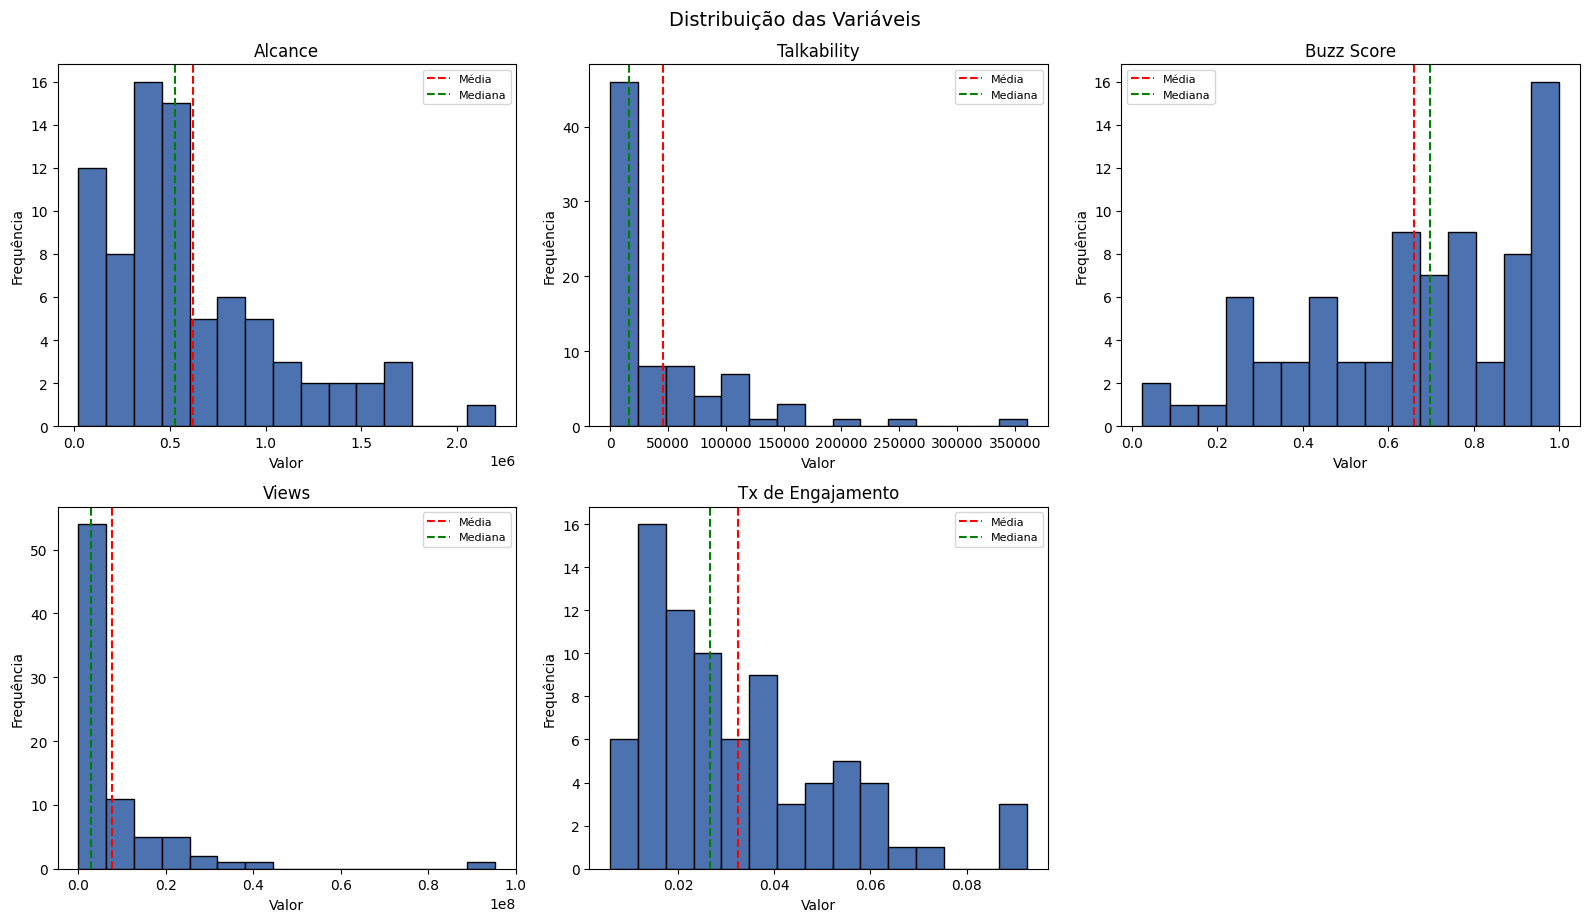

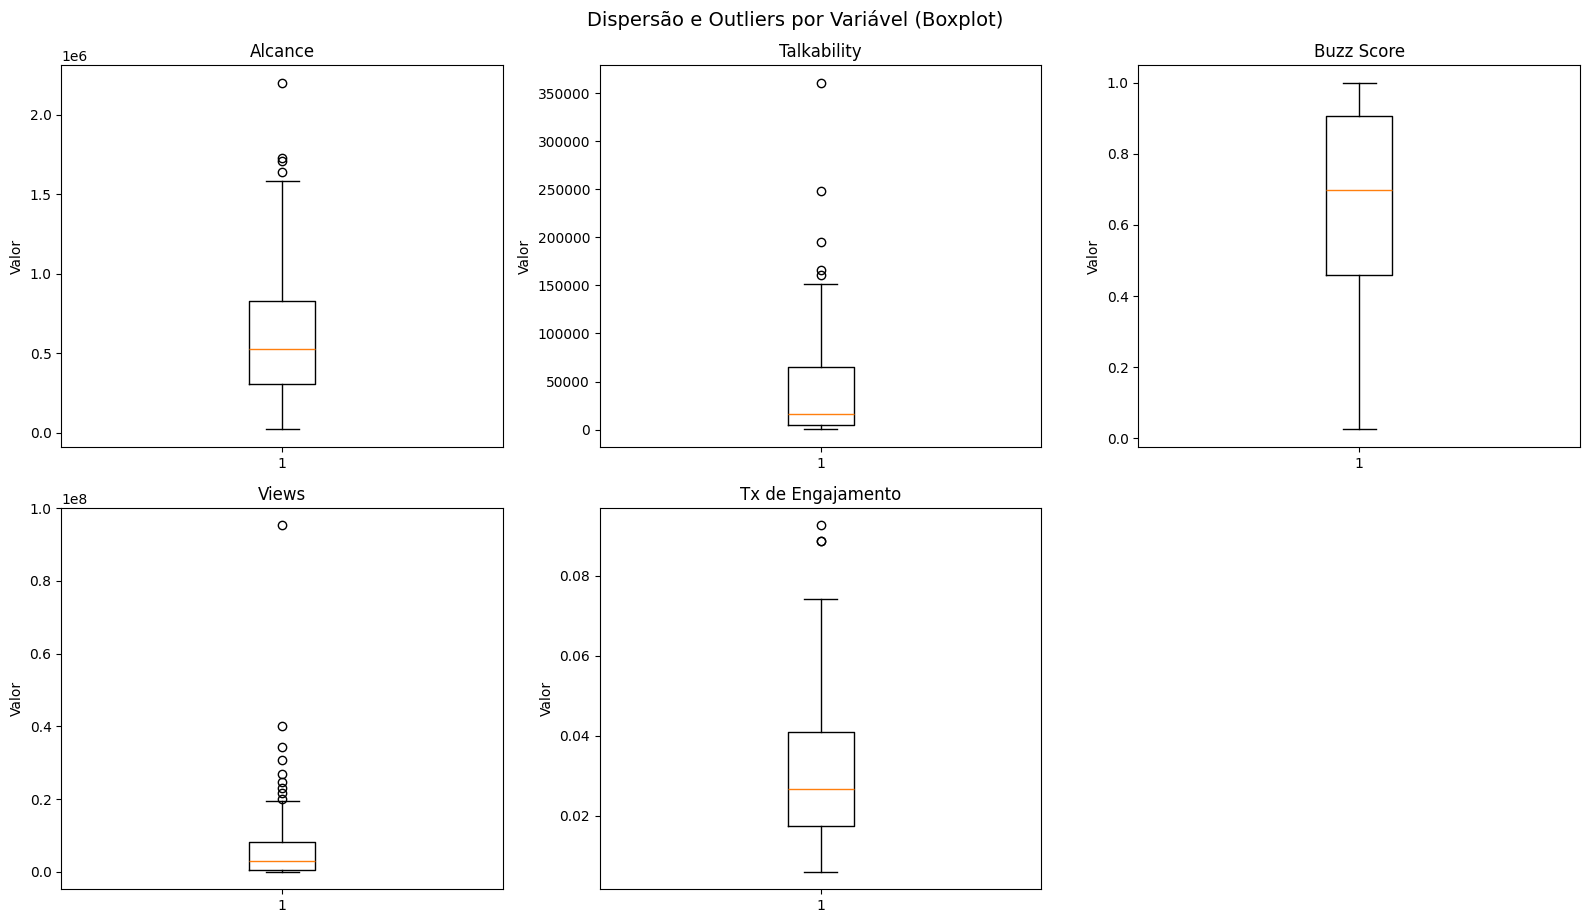


Valores ausentes por coluna:
Alcance              0
Talkability          0
Buzz Score           0
Views                0
Tx de Engajamento    0
dtype: int64
                            OLS Regression Results                            
Dep. Variable:           Q("Alcance")   R-squared:                       0.341
Model:                            OLS   Adj. R-squared:                  0.306
Method:                 Least Squares   F-statistic:                     9.692
Date:                Tue, 10 Nov 2026   Prob (F-statistic):           2.26e-06
Time:                        17:12:36   Log-Likelihood:                -1139.5
No. Observations:                  80   AIC:                             2289.
Df Residuals:                      75   BIC:                             2301.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                             coef    std err        

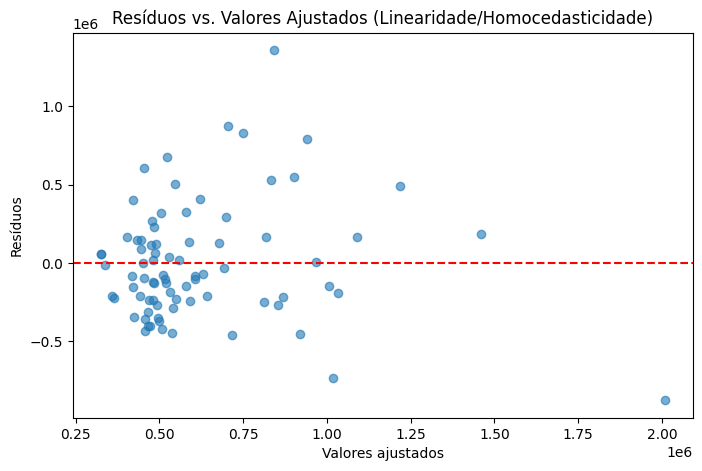


Teste de Breusch-Pagan (Homocedasticidade):
{'LM Statistic': np.float64(11.888745992762209), 'LM p-value': np.float64(0.018198041409571035), 'F-Statistic': np.float64(3.2727922956844044), 'F p-value': np.float64(0.015761118944370565)}

Durbin-Watson: 2.115 (ideal: próximo de 2)


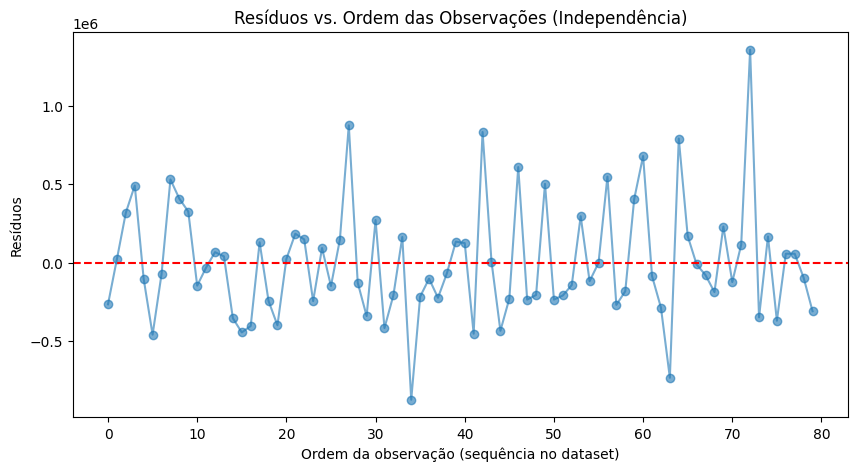


Teste de Shapiro-Wilk (Normalidade): estatística=0.9501, p-valor=0.0035


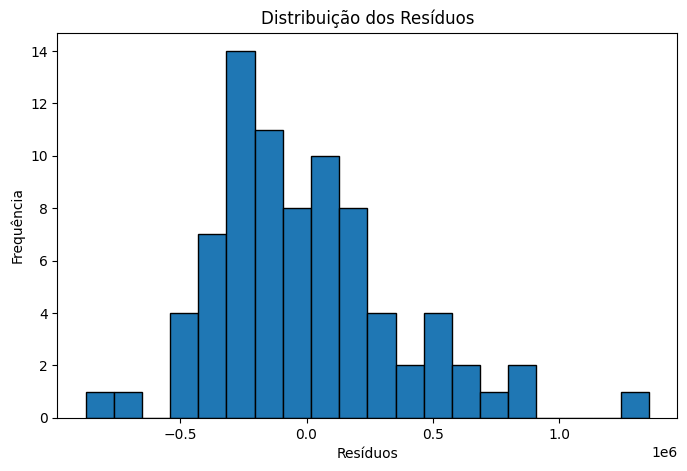

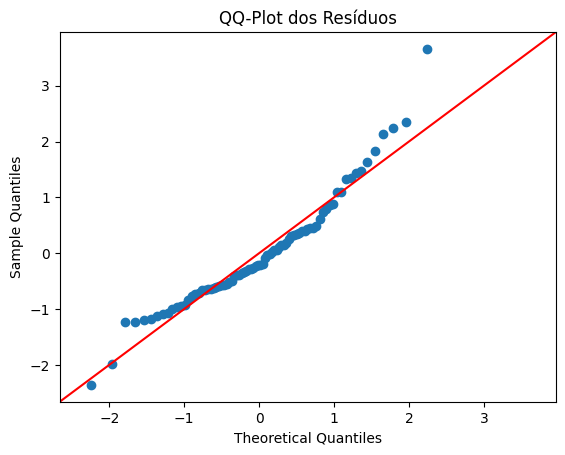


Fator de Inflação da Variância (VIF):
            Variável       VIF
0              const  1.000000
1        Talkability  3.004386
2         Buzz Score  1.038642
3              Views  3.040795
4  Tx de Engajamento  1.021791

Limite de referência para Distância de Cook (4/n): 0.0500

Casos com resíduo padronizado > |3| (outliers pelo critério de resíduo):
               Título/IP  Residuo_Padronizado  Distancia_Cook
34  Pra Sempre Paquitas             -3.579533        3.731221
72      Arcanjo Renegado             3.606917        0.096183

Casos com Distância de Cook acima do limite (observações influentes):
               Título/IP  Residuo_Padronizado  Distancia_Cook
3              Os Outros             1.407359        0.081551
34  Pra Sempre Paquitas             -3.579533        3.731221
63                Chaves            -2.116463        0.193971
72      Arcanjo Renegado             3.606917        0.096183

Diagnóstico específico para 'Arcanjo Renegado':
           Título/IP  Alca

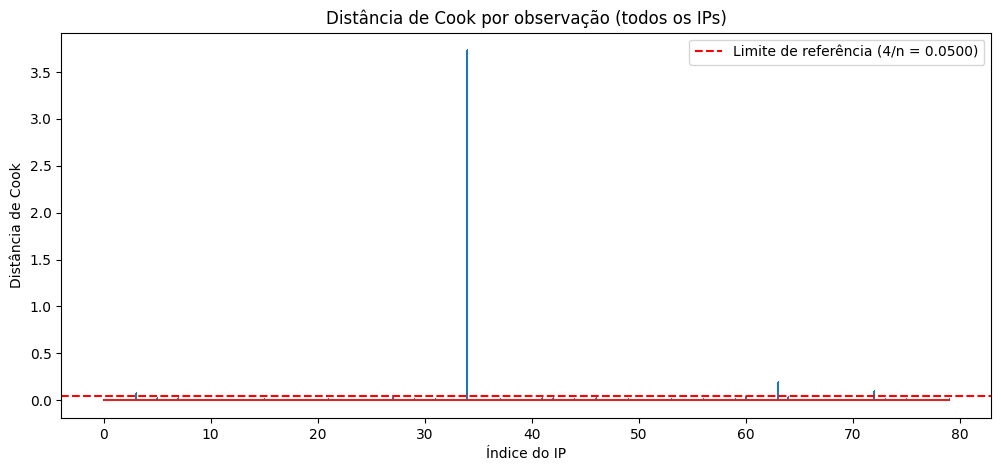


ANÁLISE DE SENSIBILIDADE — SEM 'Pra Sempre Paquitas'
Observações removidas: 1 | Amostra: 79 IPs

MODELO ORIGINAL SEM O IP:
                            OLS Regression Results                            
Dep. Variable:           Q("Alcance")   R-squared:                       0.445
Model:                            OLS   Adj. R-squared:                  0.415
Method:                 Least Squares   F-statistic:                     14.81
Date:                Tue, 10 Nov 2026   Prob (F-statistic):           6.21e-09
Time:                        17:12:39   Log-Likelihood:                -1118.3
No. Observations:                  79   AIC:                             2247.
Df Residuals:                      74   BIC:                             2258.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                             coef    std err          t      P>|t|      [0.025      0.

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [4]:
# ==============================================================
# REGRESSÃO LINEAR MÚLTIPLA — Dissertação (Conversação Social x Audiência Globoplay)
# Ambiente: Google Colab
# Bibliotecas: pandas + statsmodels
# ==============================================================

# --- 1. INSTALAÇÃO (rodar uma vez no Colab, se necessário) ---
# !pip install pandas statsmodels scipy matplotlib

import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson
from scipy import stats
import matplotlib.pyplot as plt

# --- 2. LEITURA DO ARQUIVO ---
# O arquivo já está no ambiente do Colab (barra lateral de arquivos),
# então basta ler direto pelo nome.
#
# Arquivos .csv exportados do Excel no Brasil podem ter dois problemas comuns:
# 1) Encoding diferente de UTF-8 (ex.: latin-1, cp1252)
# 2) Separador ";" em vez de "," -- e quando isso não é tratado, vírgulas
#    dentro de textos (ex. títulos de programas) quebram a leitura.
#
# O código abaixo tenta detectar automaticamente o separador correto (usando
# o engine "python", que consegue inferir o delimitador com sep=None),
# combinando com os encodings mais comuns.

nome_arquivo = "Base_IPsGloboplay.csv"

encodings_para_tentar = ["utf-8", "latin-1", "cp1252"]

df = None
erro_final = None
for enc in encodings_para_tentar:
    try:
        df = pd.read_csv(nome_arquivo, encoding=enc, sep=None, engine="python")
        print(f"Arquivo carregado com sucesso usando encoding: {enc}")
        print(f"Separador detectado automaticamente. Colunas encontradas: {list(df.columns)}")
        break
    except (UnicodeDecodeError, pd.errors.ParserError) as e:
        erro_final = e
        continue

if df is None:
    raise ValueError(
        f"Não foi possível ler o arquivo automaticamente. Último erro: {erro_final}\n"
        "Isso geralmente indica que alguma linha do arquivo está com vírgulas "
        "ou ponto-e-vírgulas inconsistentes dentro do texto (ex.: título de "
        "programa com vírgula sem estar entre aspas no CSV original). "
        "Abra o arquivo original no Excel e verifique a linha indicada no erro, "
        "ou reexporte o arquivo garantindo que campos de texto com vírgula "
        "estejam entre aspas."
    )

# Confira as primeiras linhas e os tipos de dado
print(df.head())
print(df.info())

# --- 3. DEFINIÇÃO DAS VARIÁVEIS ---
# Nomes das colunas exatamente como aparecem no arquivo original

variavel_dependente = "Alcance"

variaveis_independentes = [
    "Talkability",
    "Buzz Score",
    "Views",
    "Tx de Engajamento",
]

# --- 3.1 DIAGNÓSTICO E LIMPEZA DE TIPOS DE DADOS ---
# Dados brasileiros exportados do Excel costumam vir como TEXTO, não número,
# por causa de vírgula decimal (ex. "12,5"), símbolo de % (ex. "12,5%") ou
# ponto como separador de milhar (ex. "1.234"). Se isso não for corrigido,
# o statsmodels trata a coluna como categórica e o modelo quebra.

print("Tipos de dados ANTES da limpeza:")
print(df[variaveis_independentes + [variavel_dependente]].dtypes)

def limpar_numero_br(coluna):
    """Converte uma coluna de texto em formato numérico brasileiro para float.
    Trata: espaços, símbolo de %, ponto de milhar e vírgula decimal."""
    if coluna.dtype == object:
        coluna = (
            coluna.astype(str)
            .str.strip()
            .str.replace("%", "", regex=False)
            .str.replace(".", "", regex=False)   # remove ponto de milhar
            .str.replace(",", ".", regex=False)   # vírgula -> ponto decimal
        )
        coluna = pd.to_numeric(coluna, errors="coerce")
    return coluna

for col in variaveis_independentes + [variavel_dependente]:
    df[col] = limpar_numero_br(df[col])

print("\nTipos de dados DEPOIS da limpeza:")
print(df[variaveis_independentes + [variavel_dependente]].dtypes)

# Se a limpeza gerou algum valor ausente (NaN) por não conseguir converter,
# isso aparece aqui -- vale checar antes de seguir:
print("\nValores que viraram NaN após a limpeza (se houver, investigue a fonte):")
print(df[variaveis_independentes + [variavel_dependente]].isnull().sum())

# --- 3.2 ANÁLISE DESCRITIVA DOS DADOS ---
# Estatísticas descritivas (média, mediana, desvio padrão, mínimo, máximo,
# quartis) e visualização da distribuição de cada variável, antes de rodar
# o modelo de regressão. Essa etapa costuma abrir a seção de Resultados,
# caracterizando a amostra antes de entrar na análise inferencial.

todas_variaveis_descritiva = [variavel_dependente] + variaveis_independentes

# Tabela de estatísticas descritivas
estatisticas_descritivas = df[todas_variaveis_descritiva].describe().T
estatisticas_descritivas["mediana"] = df[todas_variaveis_descritiva].median()
estatisticas_descritivas = estatisticas_descritivas[
    ["count", "mean", "mediana", "std", "min", "25%", "50%", "75%", "max"]
]
estatisticas_descritivas.columns = [
    "N", "Média", "Mediana", "Desvio Padrão", "Mínimo",
    "1º Quartil", "2º Quartil", "3º Quartil", "Máximo"
]

print("=" * 78)
print("ESTATÍSTICAS DESCRITIVAS")
print("=" * 78)
print(estatisticas_descritivas.round(2))

# Salvar a tabela descritiva em CSV (útil para colar direto numa tabela ABNT)
estatisticas_descritivas.round(2).to_csv("estatisticas_descritivas.csv")
print("\nTabela salva em 'estatisticas_descritivas.csv'")

# --- 3.3 HISTOGRAMAS — DISTRIBUIÇÃO DE CADA VARIÁVEL ---
fig, eixos = plt.subplots(2, 3, figsize=(16, 9))
eixos = eixos.flatten()

for i, col in enumerate(todas_variaveis_descritiva):
    eixos[i].hist(df[col], bins=15, edgecolor="black", color="#4C72B0")
    eixos[i].axvline(df[col].mean(), color="red", linestyle="--", label="Média")
    eixos[i].axvline(df[col].median(), color="green", linestyle="--", label="Mediana")
    eixos[i].set_title(col)
    eixos[i].set_xlabel("Valor")
    eixos[i].set_ylabel("Frequência")
    eixos[i].legend(fontsize=8)

# Remove eixo extra não utilizado (5 variáveis em grade 2x3 = 1 espaço sobra)
for j in range(len(todas_variaveis_descritiva), len(eixos)):
    fig.delaxes(eixos[j])

plt.tight_layout()
plt.suptitle("Distribuição das Variáveis", y=1.02, fontsize=14)
plt.savefig("histogramas_distribuicao.png", bbox_inches="tight", dpi=150)
plt.show()

# --- 3.4 BOXPLOTS — VISUALIZAR DISPERSÃO E OUTLIERS POR VARIÁVEL ---
fig, eixos = plt.subplots(2, 3, figsize=(16, 9))
eixos = eixos.flatten()

for i, col in enumerate(todas_variaveis_descritiva):
    eixos[i].boxplot(df[col], vert=True)
    eixos[i].set_title(col)
    eixos[i].set_ylabel("Valor")

for j in range(len(todas_variaveis_descritiva), len(eixos)):
    fig.delaxes(eixos[j])

plt.tight_layout()
plt.suptitle("Dispersão e Outliers por Variável (Boxplot)", y=1.02, fontsize=14)
plt.savefig("boxplots_variaveis.png", bbox_inches="tight", dpi=150)
plt.show()

# --- 4. VERIFICAÇÃO DE DADOS FALTANTES ---
print("\nValores ausentes por coluna:")
print(df[[variavel_dependente] + variaveis_independentes].isnull().sum())

# Remova ou trate linhas com dados faltantes antes de seguir, se houver
df = df.dropna(subset=[variavel_dependente] + variaveis_independentes)

# --- 5. ESTIMAÇÃO DO MODELO DE REGRESSÃO MÚLTIPLA ---
# Usando a interface de fórmula do statsmodels (mais legível)
# Como os nomes das colunas têm espaços/parênteses, é preciso "escapar"
# cada nome com Q("...") para a fórmula funcionar corretamente.

def escapar(nome_coluna):
    return f'Q("{nome_coluna}")'

formula = f"{escapar(variavel_dependente)} ~ " + " + ".join(
    escapar(v) for v in variaveis_independentes
)
modelo = smf.ols(formula=formula, data=df).fit()

# --- 6. SAÍDA COMPLETA DO MODELO ---
# Isto já traz: coeficientes, erro padrão, valores-t, p-valores, R², R² ajustado, F-estatística
print(modelo.summary())

# --- 6.1 MODELO PADRONIZADO (Z-SCORE) — para resolver problema de escala ---
# O número de condição alto (Cond. No.) no modelo acima geralmente indica que
# as variáveis estão em escalas muito diferentes entre si (ex. Talkability em
# unidades pequenas vs. Alcance na casa de centenas de milhares), e não
# necessariamente multicolinearidade real.
#
# Padronizar (transformar cada variável para média 0 e desvio padrão 1) resolve
# o problema numérico E torna os coeficientes comparáveis entre si — o maior
# coeficiente padronizado indica a variável com maior peso relativo no modelo.

from scipy.stats import zscore

df_padronizado = df.copy()
todas_variaveis = [variavel_dependente] + variaveis_independentes

for col in todas_variaveis:
    df_padronizado[col] = zscore(df_padronizado[col])

formula_padronizada = f"{escapar(variavel_dependente)} ~ " + " + ".join(
    escapar(v) for v in variaveis_independentes
)
modelo_padronizado = smf.ols(formula=formula_padronizada, data=df_padronizado).fit()

print("\n" + "=" * 78)
print("MODELO PADRONIZADO (coeficientes comparáveis entre si)")
print("=" * 78)
print(modelo_padronizado.summary())

# --- 7. TESTES DE PRESSUPOSTOS ---

# 7.1 Linearidade e Homocedasticidade — gráfico de resíduos vs. valores ajustados
plt.figure(figsize=(8, 5))
plt.scatter(modelo.fittedvalues, modelo.resid, alpha=0.6)
plt.axhline(y=0, color="red", linestyle="--")
plt.xlabel("Valores ajustados")
plt.ylabel("Resíduos")
plt.title("Resíduos vs. Valores Ajustados (Linearidade/Homocedasticidade)")
plt.savefig("residuos_vs_ajustados.png", bbox_inches="tight", dpi=150)
plt.show()

# 7.2 Homocedasticidade — Teste de Breusch-Pagan
# H0: homocedasticidade (variância constante) — p > 0,05 é o resultado desejado
bp_test = het_breuschpagan(modelo.resid, modelo.model.exog)
labels = ["LM Statistic", "LM p-value", "F-Statistic", "F p-value"]
print("\nTeste de Breusch-Pagan (Homocedasticidade):")
print(dict(zip(labels, bp_test)))

# 7.3 Independência dos resíduos — Durbin-Watson
# Valores próximos de 2 indicam ausência de autocorrelação
dw = durbin_watson(modelo.resid)
print(f"\nDurbin-Watson: {dw:.3f} (ideal: próximo de 2)")

# Gráfico de resíduos vs. ordem das observações (checagem visual de independência)
# Pressupõe que a ordem das linhas no dataset é significativa (ex. ordem
# cronológica de lançamento) -- o mesmo pressuposto do teste de Durbin-Watson.
plt.figure(figsize=(10, 5))
plt.plot(range(len(modelo.resid)), modelo.resid, marker="o", linestyle="-", alpha=0.6)
plt.axhline(y=0, color="red", linestyle="--")
plt.xlabel("Ordem da observação (sequência no dataset)")
plt.ylabel("Resíduos")
plt.title("Resíduos vs. Ordem das Observações (Independência)")
plt.savefig("residuos_vs_ordem.png", bbox_inches="tight", dpi=150)
plt.show()

# 7.4 Normalidade dos resíduos — Shapiro-Wilk
# H0: resíduos seguem distribuição normal — p > 0,05 é o resultado desejado
shapiro_test = stats.shapiro(modelo.resid)
print(f"\nTeste de Shapiro-Wilk (Normalidade): estatística={shapiro_test[0]:.4f}, p-valor={shapiro_test[1]:.4f}")

# Histograma dos resíduos (inspeção visual da normalidade)
plt.figure(figsize=(8, 5))
plt.hist(modelo.resid, bins=20, edgecolor="black")
plt.xlabel("Resíduos")
plt.ylabel("Frequência")
plt.title("Distribuição dos Resíduos")
plt.savefig("histograma_residuos.png", bbox_inches="tight", dpi=150)
plt.show()

# QQ-plot (outra forma visual de checar normalidade)
sm.qqplot(modelo.resid, line="45", fit=True)
plt.title("QQ-Plot dos Resíduos")
plt.savefig("qqplot_residuos.png", bbox_inches="tight", dpi=150)
plt.show()

# 7.5 Multicolinearidade — VIF (Fator de Inflação da Variância)
# Importante quando há mais de uma variável independente (seu caso)
from statsmodels.stats.outliers_influence import variance_inflation_factor

X = sm.add_constant(df[variaveis_independentes])
vif_data = pd.DataFrame()
vif_data["Variável"] = X.columns
vif_data["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
print("\nFator de Inflação da Variância (VIF):")
print(vif_data)
# Regra prática: VIF > 10 indica problema sério de multicolinearidade

# --- 7.6 DIAGNÓSTICO DE OUTLIERS E OBSERVAÇÕES INFLUENTES ---
# Antes de remover qualquer caso do modelo, é preciso justificativa estatística
# objetiva — não basta "achar" que um caso é outlier. Duas métricas padrão:
#
# 1) Resíduo padronizado: valores acima de |3| (ou às vezes |2|) indicam que
#    aquele caso está muito distante do que o modelo previu.
# 2) Distância de Cook: mede o quanto aquele caso, sozinho, influencia as
#    estimativas do modelo. Regra prática: valores acima de 4/n são notáveis.

influence = modelo.get_influence()
residuos_padronizados = influence.resid_studentized_internal
distancia_cook = influence.cooks_distance[0]

diagnostico = df.copy()
diagnostico["Residuo_Padronizado"] = residuos_padronizados
diagnostico["Distancia_Cook"] = distancia_cook

limite_cook = 4 / len(df)

print(f"\nLimite de referência para Distância de Cook (4/n): {limite_cook:.4f}")
print("\nCasos com resíduo padronizado > |3| (outliers pelo critério de resíduo):")
print(diagnostico[diagnostico["Residuo_Padronizado"].abs() > 3][
    ["Título/IP", "Residuo_Padronizado", "Distancia_Cook"]
])

print("\nCasos com Distância de Cook acima do limite (observações influentes):")
print(diagnostico[diagnostico["Distancia_Cook"] > limite_cook][
    ["Título/IP", "Residuo_Padronizado", "Distancia_Cook"]
])

# Para checar um IP específico (ex. "Arcanjo Renegado"), use:
ip_para_checar = "Arcanjo Renegado"
print(f"\nDiagnóstico específico para '{ip_para_checar}':")
print(diagnostico[diagnostico["Título/IP"] == ip_para_checar][
    ["Título/IP", variavel_dependente, "Residuo_Padronizado", "Distancia_Cook"]
])

# --- 7.7 DISTÂNCIA DE COOK — TODOS OS 80 IPs, ORDENADOS DO MAIS INFLUENTE ---
# Visão completa para identificar rapidamente se há outros candidatos a
# observação influente além do que já foi identificado manualmente.

tabela_cook_completa = diagnostico[
    ["Título/IP", variavel_dependente, "Residuo_Padronizado", "Distancia_Cook"]
].sort_values("Distancia_Cook", ascending=False).reset_index(drop=True)

print("\n" + "=" * 78)
print("DISTÂNCIA DE COOK — TODOS OS IPs (ordenado do mais para o menos influente)")
print("=" * 78)
print(tabela_cook_completa.to_string())

# Gráfico de distância de Cook por observação (facilita visualizar outliers)
plt.figure(figsize=(12, 5))
plt.stem(range(len(diagnostico)), diagnostico["Distancia_Cook"], markerfmt=",")
plt.axhline(y=limite_cook, color="red", linestyle="--",
            label=f"Limite de referência (4/n = {limite_cook:.4f})")
plt.xlabel("Índice do IP")
plt.ylabel("Distância de Cook")
plt.title("Distância de Cook por observação (todos os IPs)")
plt.legend()
plt.show()

# --- 7.8 ANÁLISE DE SENSIBILIDADE: MODELO SEM "PRA SEMPRE PAQUITAS" ---
# O modelo principal (80 IPs) mantém todos os casos. Aqui o mesmo modelo é
# reestimado excluindo o IP de maior influência (distância de Cook), para
# verificar se as conclusões dependem dele. A exclusão vale só para este
# bloco: o "df" original, com os 80 IPs, não é alterado.

ip_excluido = "Pra Sempre Paquitas"

# Compara os títulos ignorando espaços extras (no CSV o nome vem como
# "Pra Sempre Paquitas " com espaço no final), espaços especiais e maiúsculas.
def normalizar_titulo(texto):
    return " ".join(str(texto).replace("\xa0", " ").split()).casefold()

mascara_ip = df["Título/IP"].map(normalizar_titulo) == normalizar_titulo(ip_excluido)

# Trava de segurança: em vez de seguir com um modelo idêntico ao original,
# o script para se não encontrar exatamente 1 IP para excluir.
if mascara_ip.sum() != 1:
    parecidos = df.loc[
        df["Título/IP"].str.contains("paquita", case=False, na=False), "Título/IP"
    ].tolist()
    raise ValueError(
        f"Era esperado excluir exatamente 1 IP, mas {int(mascara_ip.sum())} foram "
        f"encontrados para '{ip_excluido}'. Títulos parecidos na base: {parecidos}"
    )

df_sem = df[~mascara_ip].copy()
n_removidos = len(df) - len(df_sem)

print("\n" + "=" * 78)
print(f"ANÁLISE DE SENSIBILIDADE — SEM '{ip_excluido}'")
print("=" * 78)
print(f"Observações removidas: {n_removidos} | Amostra: {len(df_sem)} IPs")
if n_removidos != 1:
    print("ATENÇÃO: era esperado remover exatamente 1 observação. "
          "Confira o nome do IP na coluna 'Título/IP'.")

# Modelo na escala original
modelo_sem = smf.ols(formula=formula, data=df_sem).fit()
print("\nMODELO ORIGINAL SEM O IP:")
print(modelo_sem.summary())

# Modelo padronizado (z-score recalculado só com os IPs restantes)
df_sem_pad = df_sem.copy()
for col in todas_variaveis:
    df_sem_pad[col] = zscore(df_sem_pad[col])
modelo_sem_pad = smf.ols(formula=formula_padronizada, data=df_sem_pad).fit()
print("\nMODELO PADRONIZADO SEM O IP:")
print(modelo_sem_pad.summary())

# Pressupostos do modelo sem o IP
bp_sem = het_breuschpagan(modelo_sem.resid, modelo_sem.model.exog)
dw_sem = durbin_watson(modelo_sem.resid)
shapiro_sem = stats.shapiro(modelo_sem.resid)

X_sem = sm.add_constant(df_sem[variaveis_independentes])
vif_sem = pd.DataFrame({
    "Variável": X_sem.columns,
    "VIF": [variance_inflation_factor(X_sem.values, i) for i in range(X_sem.shape[1])],
})

print("\nPRESSUPOSTOS SEM O IP:")
for nome, valor in zip(labels, bp_sem):
    print(f"  Breusch-Pagan {nome}: {valor:.6f}")
print(f"  Durbin-Watson: {dw_sem:.3f}")
print(f"  Shapiro-Wilk: estatística={shapiro_sem[0]:.4f}, p-valor={shapiro_sem[1]:.4f}")
print("\nVIF sem o IP:")
print(vif_sem.to_string(index=False))

# Observações influentes no modelo sem o IP
influence_sem = modelo_sem.get_influence()
diag_sem = df_sem.copy()
diag_sem["Residuo_Padronizado"] = influence_sem.resid_studentized_internal
diag_sem["Distancia_Cook"] = influence_sem.cooks_distance[0]
limite_cook_sem = 4 / len(df_sem)
influentes_sem = diag_sem[diag_sem["Distancia_Cook"] > limite_cook_sem][
    ["Título/IP", variavel_dependente, "Residuo_Padronizado", "Distancia_Cook"]
]
print(f"\nObservações influentes sem o IP (Cook > 4/n = {limite_cook_sem:.4f}):")
print(influentes_sem.to_string())

# Comparação lado a lado: com os 80 IPs x sem o IP
comparacao_coef = pd.DataFrame({
    "Coef. padronizado (todos)": modelo_padronizado.params,
    "p-valor (todos)": modelo_padronizado.pvalues,
    "Coef. padronizado (sem o IP)": modelo_sem_pad.params,
    "p-valor (sem o IP)": modelo_sem_pad.pvalues,
}).round(4)

comparacao_ajuste = pd.DataFrame({
    "N": [int(modelo.nobs), int(modelo_sem.nobs)],
    "R²": [modelo.rsquared, modelo_sem.rsquared],
    "R² ajustado": [modelo.rsquared_adj, modelo_sem.rsquared_adj],
    "p-valor do teste F": [modelo.f_pvalue, modelo_sem.f_pvalue],
}, index=["Todos os IPs", f"Sem {ip_excluido}"]).round(4)

print("\n" + "=" * 78)
print("COMPARAÇÃO: COM x SEM O IP")
print("=" * 78)
print(comparacao_ajuste.to_string())
print()
print(comparacao_coef.to_string())

# Salva tudo em arquivo de texto e CSV
with open("resultado_sensibilidade.txt", "w", encoding="utf-8") as f:
    f.write(f"ANÁLISE DE SENSIBILIDADE — SEM '{ip_excluido}' (n = {len(df_sem)})\n\n")
    f.write("MODELO ORIGINAL SEM O IP\n")
    f.write(modelo_sem.summary().as_text())
    f.write("\n\n" + "=" * 78 + "\n")
    f.write("MODELO PADRONIZADO SEM O IP\n")
    f.write(modelo_sem_pad.summary().as_text())
    f.write("\n\n" + "=" * 78 + "\n")
    f.write("PRESSUPOSTOS SEM O IP\n")
    for nome, valor in zip(labels, bp_sem):
        f.write(f"  Breusch-Pagan {nome}: {valor:.6f}\n")
    f.write(f"  Durbin-Watson: {dw_sem:.3f}\n")
    f.write(f"  Shapiro-Wilk: estatística={shapiro_sem[0]:.4f}, p-valor={shapiro_sem[1]:.4f}\n\n")
    f.write("VIF SEM O IP\n")
    f.write(vif_sem.to_string(index=False))
    f.write(f"\n\nOBSERVAÇÕES INFLUENTES SEM O IP (Cook > 4/n = {limite_cook_sem:.4f})\n")
    f.write(influentes_sem.to_string())
    f.write("\n\n" + "=" * 78 + "\n")
    f.write("COMPARAÇÃO: COM x SEM O IP\n")
    f.write(comparacao_ajuste.to_string())
    f.write("\n\n")
    f.write(comparacao_coef.to_string())

comparacao_coef.to_csv("comparacao_sensibilidade.csv")

# --- 8. EXPORTAR TODOS OS RESULTADOS (um único .zip para baixar) ---
# Junta num só arquivo de texto: modelo original, modelo padronizado, testes
# de pressupostos, VIF e a lista de observações influentes. Também salva a
# tabela de Cook e o VIF em CSV e empacota tudo (com os gráficos .png que o
# script já salvou) em "resultados_dissertacao.zip".

import os
import zipfile

with open("resultado_regressao.txt", "w", encoding="utf-8") as f:
    f.write("MODELO ORIGINAL (escala bruta)\n")
    f.write(modelo.summary().as_text())

    f.write("\n\n" + "=" * 78 + "\n")
    f.write("MODELO PADRONIZADO (z-score)\n")
    f.write("=" * 78 + "\n")
    f.write(modelo_padronizado.summary().as_text())

    f.write("\n\n" + "=" * 78 + "\n")
    f.write("TESTES DE PRESSUPOSTOS\n")
    f.write("=" * 78 + "\n")
    f.write("Breusch-Pagan (homocedasticidade):\n")
    for nome, valor in zip(labels, bp_test):
        f.write(f"  {nome}: {valor:.6f}\n")
    f.write(f"\nDurbin-Watson: {dw:.3f}\n")
    f.write(
        f"\nShapiro-Wilk (normalidade): estatística={shapiro_test[0]:.4f}, "
        f"p-valor={shapiro_test[1]:.4f}\n"
    )

    f.write("\n" + "=" * 78 + "\n")
    f.write("VIF (multicolinearidade)\n")
    f.write("=" * 78 + "\n")
    f.write(vif_data.to_string(index=False))

    f.write("\n\n" + "=" * 78 + "\n")
    f.write(f"OBSERVAÇÕES INFLUENTES (Distância de Cook > 4/n = {limite_cook:.4f})\n")
    f.write("=" * 78 + "\n")
    f.write(
        diagnostico[diagnostico["Distancia_Cook"] > limite_cook][
            ["Título/IP", variavel_dependente, "Residuo_Padronizado", "Distancia_Cook"]
        ].to_string()
    )

# Tabelas em CSV (fáceis de abrir no Excel)
vif_data.to_csv("vif.csv", index=False)
tabela_cook_completa.to_csv("distancia_cook_todos_ips.csv", index=False)

# Empacota tudo num único .zip (só inclui o que existir na pasta)
arquivos_para_zip = [
    "resultado_regressao.txt",
    "resultado_sensibilidade.txt",
    "comparacao_sensibilidade.csv",
    "vif.csv",
    "distancia_cook_todos_ips.csv",
    "estatisticas_descritivas.csv",
    "histogramas_distribuicao.png",
    "boxplots_variaveis.png",
    "residuos_vs_ajustados.png",
    "residuos_vs_ordem.png",
    "histograma_residuos.png",
    "qqplot_residuos.png",
]

with zipfile.ZipFile("resultados_dissertacao.zip", "w") as zf:
    for arquivo in arquivos_para_zip:
        if os.path.exists(arquivo):
            zf.write(arquivo)

print("\nResultados salvos em 'resultados_dissertacao.zip'")

# Baixa o .zip automaticamente para o seu computador
from google.colab import files
files.download("resultados_dissertacao.zip")


Arquivo carregado com sucesso usando encoding: latin-1
Separador detectado automaticamente. Colunas encontradas: ['Título/IP', 'Temporada', 'Lançamento', 'Território', 'Gênero Principal', 'Classe', 'Vertical', 'Formato', 'Episódios', 'Alcance', 'Buzz Score', 'Talkability', 'Posts', 'Views', 'Views por post', 'Tx de Engajamento']
                        Título/IP  Temporada  Lançamento   Território  \
0                         As Five          2  08/02/2023  dramaturgia   
1                          Origem          1  21/03/2023  dramaturgia   
2  The Good Doctor - O Bom Doutor          6  21/04/2023  dramaturgia   
3                       Os Outros          1  31/05/2023  dramaturgia   
4              A Vida Pela Frente          1  22/06/2023  dramaturgia   

    Gênero Principal      Classe        Vertical Formato  Episódios  Alcance  \
0              Drama    original  Entretenimento  séries          8   586125   
1  Suspense/Thriller  licenciado  Entretenimento  séries         10   

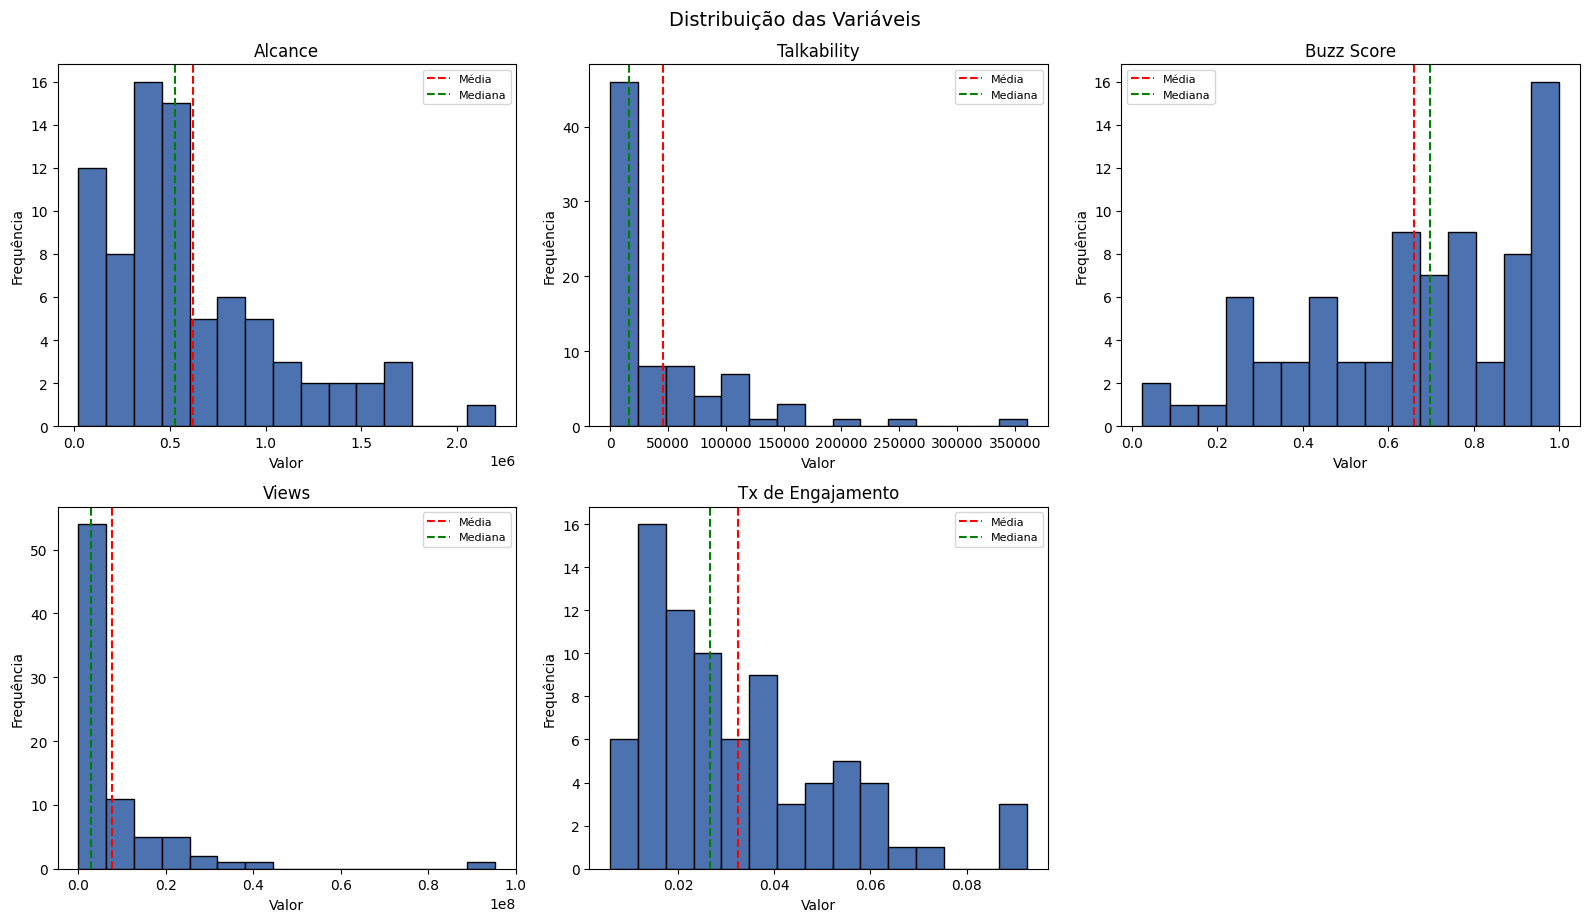

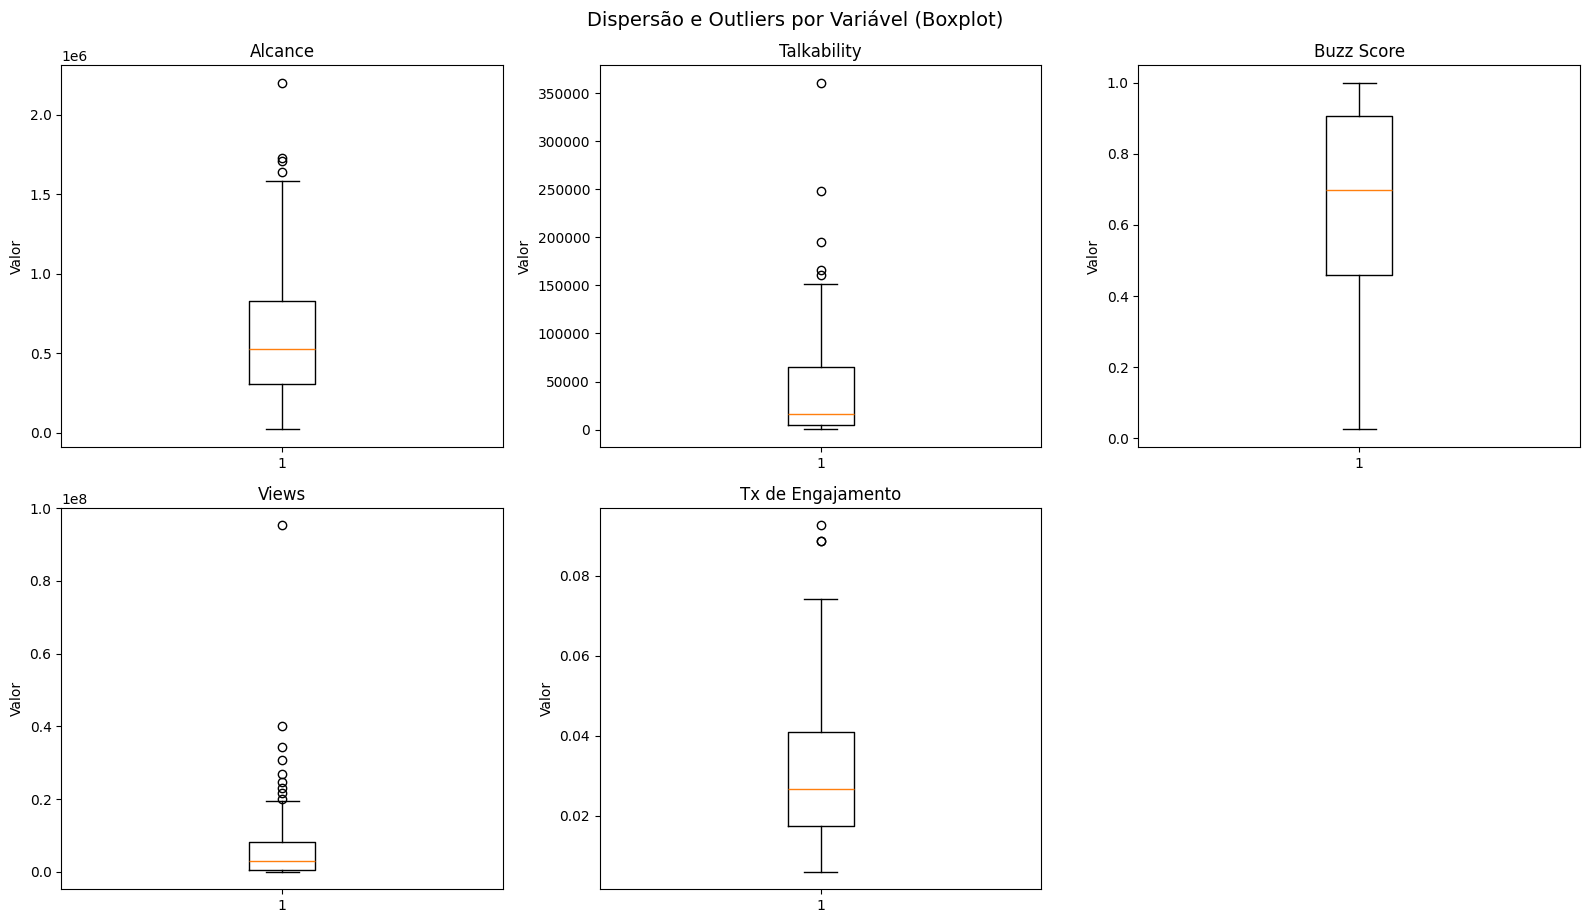


Valores ausentes por coluna:
Alcance              0
Talkability          0
Buzz Score           0
Views                0
Tx de Engajamento    0
dtype: int64
                            OLS Regression Results                            
Dep. Variable:           Q("Alcance")   R-squared:                       0.341
Model:                            OLS   Adj. R-squared:                  0.306
Method:                 Least Squares   F-statistic:                     9.692
Date:                Tue, 10 Nov 2026   Prob (F-statistic):           2.26e-06
Time:                        17:31:44   Log-Likelihood:                -1139.5
No. Observations:                  80   AIC:                             2289.
Df Residuals:                      75   BIC:                             2301.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                             coef    std err        

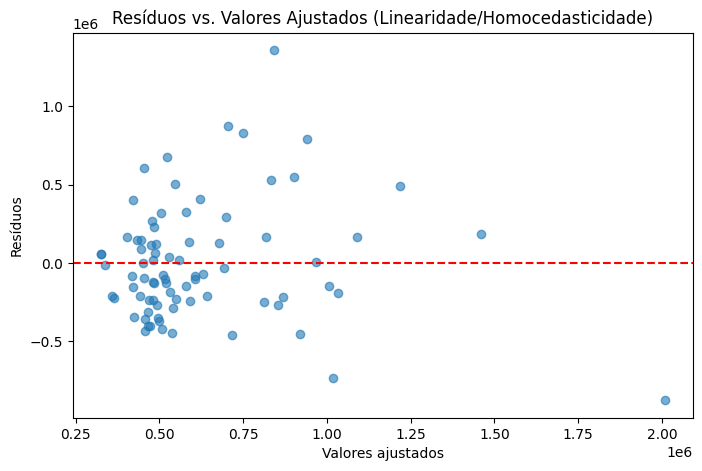


Teste de Breusch-Pagan (Homocedasticidade):
{'LM Statistic': np.float64(11.888745992762209), 'LM p-value': np.float64(0.018198041409571035), 'F-Statistic': np.float64(3.2727922956844044), 'F p-value': np.float64(0.015761118944370565)}

Durbin-Watson: 2.115 (ideal: próximo de 2)


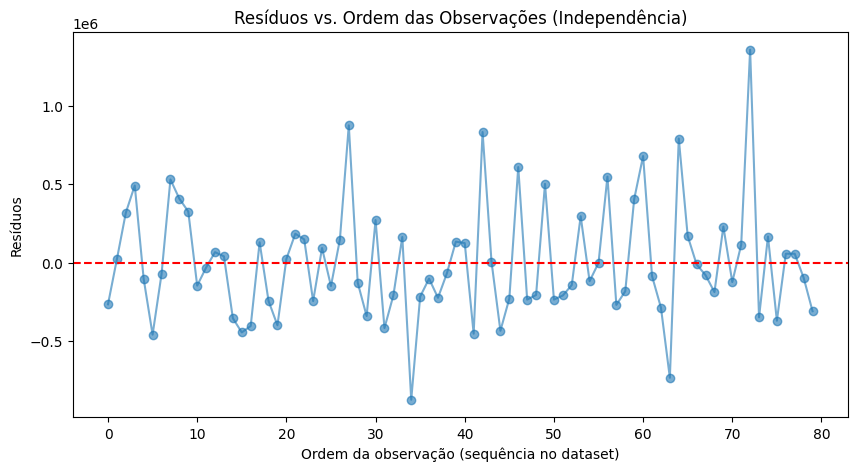


Teste de Shapiro-Wilk (Normalidade): estatística=0.9501, p-valor=0.0035


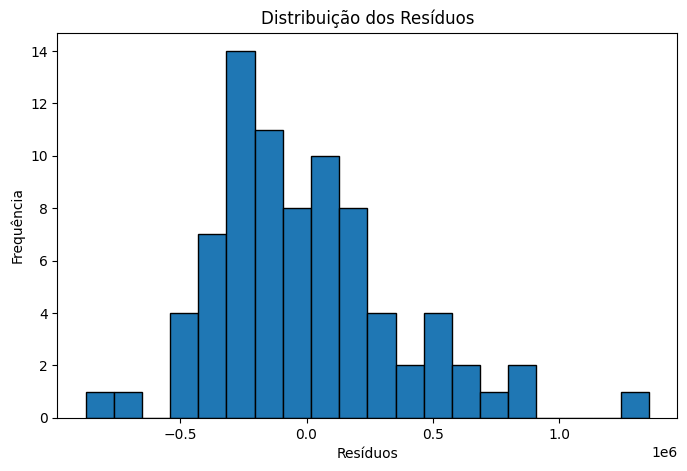

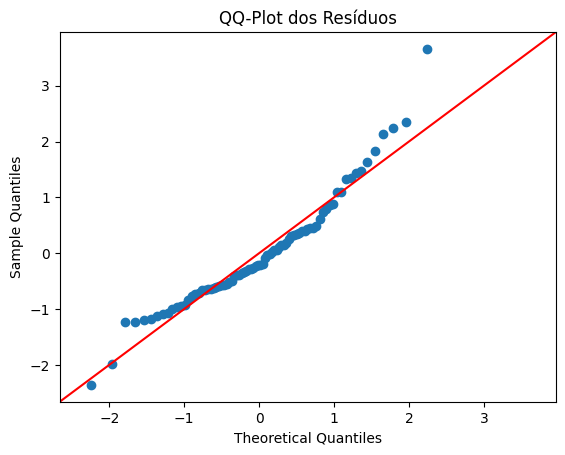


Fator de Inflação da Variância (VIF):
            Variável       VIF
0              const  1.000000
1        Talkability  3.004386
2         Buzz Score  1.038642
3              Views  3.040795
4  Tx de Engajamento  1.021791

Limite de referência para Distância de Cook (4/n): 0.0500

Casos com resíduo padronizado > |3| (outliers pelo critério de resíduo):
               Título/IP  Residuo_Padronizado  Distancia_Cook
34  Pra Sempre Paquitas             -3.579533        3.731221
72      Arcanjo Renegado             3.606917        0.096183

Casos com Distância de Cook acima do limite (observações influentes):
               Título/IP  Residuo_Padronizado  Distancia_Cook
3              Os Outros             1.407359        0.081551
34  Pra Sempre Paquitas             -3.579533        3.731221
63                Chaves            -2.116463        0.193971
72      Arcanjo Renegado             3.606917        0.096183

Diagnóstico específico para 'Arcanjo Renegado':
           Título/IP  Alca

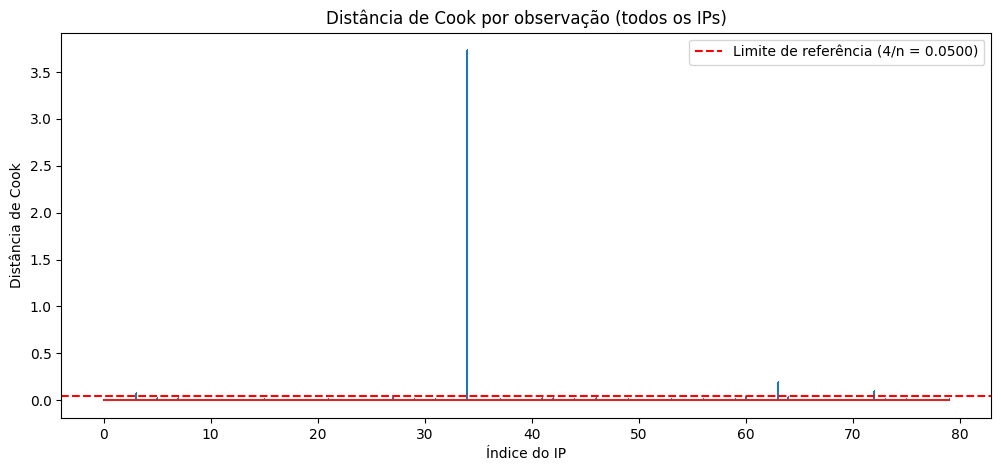


ANÁLISE DE SENSIBILIDADE — SEM 'Pra Sempre Paquitas'
Observações removidas: 1 | Amostra: 79 IPs

MODELO ORIGINAL SEM O IP:
                            OLS Regression Results                            
Dep. Variable:           Q("Alcance")   R-squared:                       0.445
Model:                            OLS   Adj. R-squared:                  0.415
Method:                 Least Squares   F-statistic:                     14.81
Date:                Tue, 10 Nov 2026   Prob (F-statistic):           6.21e-09
Time:                        17:31:46   Log-Likelihood:                -1118.3
No. Observations:                  79   AIC:                             2247.
Df Residuals:                      74   BIC:                             2258.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                             coef    std err          t      P>|t|      [0.025      0.

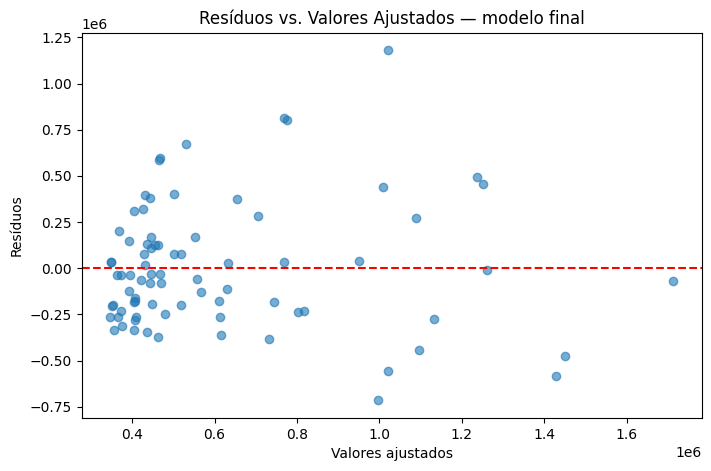

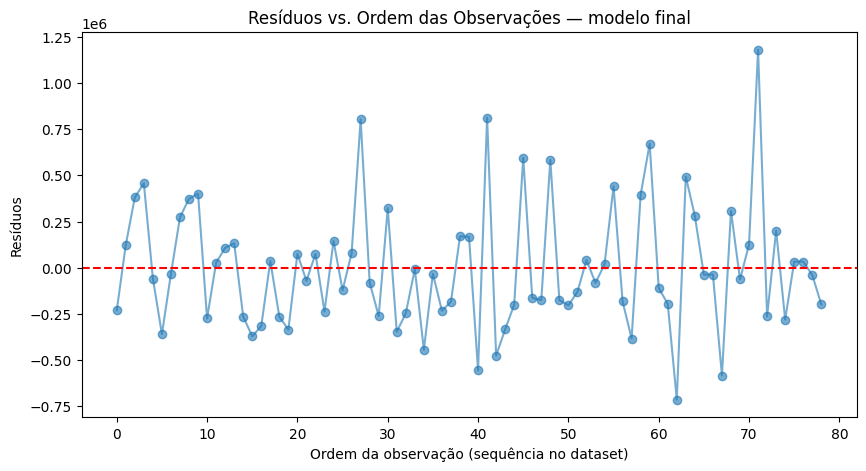

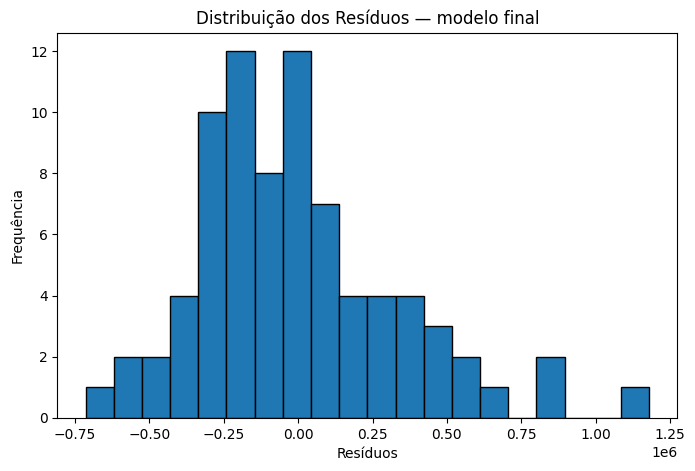

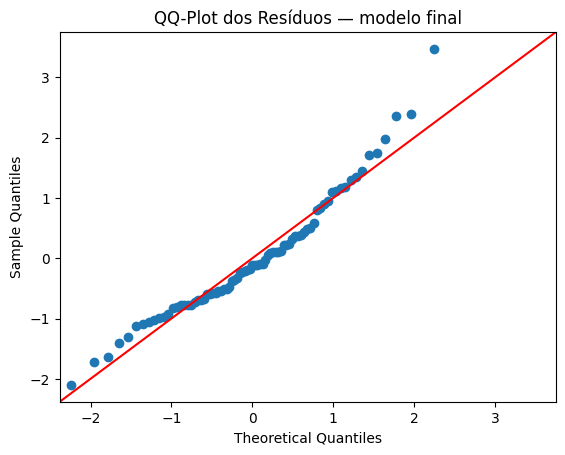


COMPARAÇÃO: COM x SEM O IP
                          N      R²  R² ajustado  p-valor do teste F
Todos os IPs             80  0.3408       0.3056                 0.0
Sem Pra Sempre Paquitas  79  0.4446       0.4146                 0.0

                        Coef. padronizado (todos)  p-valor (todos)  Coef. padronizado (sem o IP)  p-valor (sem o IP)
Intercept                                  0.0000           1.0000                       -0.0000              1.0000
Q("Talkability")                           0.4855           0.0038                        0.3388              0.0085
Q("Buzz Score")                            0.0426           0.6573                        0.0519              0.5574
Q("Views")                                 0.1142           0.4869                        0.3792              0.0037
Q("Tx de Engajamento")                    -0.0931           0.3293                       -0.0296              0.7378

Resultados salvos em 'resultados_dissertacao.zip'


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [5]:
# ==============================================================
# REGRESSÃO LINEAR MÚLTIPLA — Dissertação (Conversação Social x Audiência Globoplay)
# Ambiente: Google Colab
# Bibliotecas: pandas + statsmodels
# ==============================================================

# --- 1. INSTALAÇÃO (rodar uma vez no Colab, se necessário) ---
# !pip install pandas statsmodels scipy matplotlib

import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson
from scipy import stats
import matplotlib.pyplot as plt

# --- 2. LEITURA DO ARQUIVO ---
# O arquivo já está no ambiente do Colab (barra lateral de arquivos),
# então basta ler direto pelo nome.
#
# Arquivos .csv exportados do Excel no Brasil podem ter dois problemas comuns:
# 1) Encoding diferente de UTF-8 (ex.: latin-1, cp1252)
# 2) Separador ";" em vez de "," -- e quando isso não é tratado, vírgulas
#    dentro de textos (ex. títulos de programas) quebram a leitura.
#
# O código abaixo tenta detectar automaticamente o separador correto (usando
# o engine "python", que consegue inferir o delimitador com sep=None),
# combinando com os encodings mais comuns.

nome_arquivo = "Base_IPsGloboplay.csv"

encodings_para_tentar = ["utf-8", "latin-1", "cp1252"]

df = None
erro_final = None
for enc in encodings_para_tentar:
    try:
        df = pd.read_csv(nome_arquivo, encoding=enc, sep=None, engine="python")
        print(f"Arquivo carregado com sucesso usando encoding: {enc}")
        print(f"Separador detectado automaticamente. Colunas encontradas: {list(df.columns)}")
        break
    except (UnicodeDecodeError, pd.errors.ParserError) as e:
        erro_final = e
        continue

if df is None:
    raise ValueError(
        f"Não foi possível ler o arquivo automaticamente. Último erro: {erro_final}\n"
        "Isso geralmente indica que alguma linha do arquivo está com vírgulas "
        "ou ponto-e-vírgulas inconsistentes dentro do texto (ex.: título de "
        "programa com vírgula sem estar entre aspas no CSV original). "
        "Abra o arquivo original no Excel e verifique a linha indicada no erro, "
        "ou reexporte o arquivo garantindo que campos de texto com vírgula "
        "estejam entre aspas."
    )

# Confira as primeiras linhas e os tipos de dado
print(df.head())
print(df.info())

# --- 3. DEFINIÇÃO DAS VARIÁVEIS ---
# Nomes das colunas exatamente como aparecem no arquivo original

variavel_dependente = "Alcance"

variaveis_independentes = [
    "Talkability",
    "Buzz Score",
    "Views",
    "Tx de Engajamento",
]

# --- 3.1 DIAGNÓSTICO E LIMPEZA DE TIPOS DE DADOS ---
# Dados brasileiros exportados do Excel costumam vir como TEXTO, não número,
# por causa de vírgula decimal (ex. "12,5"), símbolo de % (ex. "12,5%") ou
# ponto como separador de milhar (ex. "1.234"). Se isso não for corrigido,
# o statsmodels trata a coluna como categórica e o modelo quebra.

print("Tipos de dados ANTES da limpeza:")
print(df[variaveis_independentes + [variavel_dependente]].dtypes)

def limpar_numero_br(coluna):
    """Converte uma coluna de texto em formato numérico brasileiro para float.
    Trata: espaços, símbolo de %, ponto de milhar e vírgula decimal."""
    if coluna.dtype == object:
        coluna = (
            coluna.astype(str)
            .str.strip()
            .str.replace("%", "", regex=False)
            .str.replace(".", "", regex=False)   # remove ponto de milhar
            .str.replace(",", ".", regex=False)   # vírgula -> ponto decimal
        )
        coluna = pd.to_numeric(coluna, errors="coerce")
    return coluna

for col in variaveis_independentes + [variavel_dependente]:
    df[col] = limpar_numero_br(df[col])

print("\nTipos de dados DEPOIS da limpeza:")
print(df[variaveis_independentes + [variavel_dependente]].dtypes)

# Se a limpeza gerou algum valor ausente (NaN) por não conseguir converter,
# isso aparece aqui -- vale checar antes de seguir:
print("\nValores que viraram NaN após a limpeza (se houver, investigue a fonte):")
print(df[variaveis_independentes + [variavel_dependente]].isnull().sum())

# --- 3.2 ANÁLISE DESCRITIVA DOS DADOS ---
# Estatísticas descritivas (média, mediana, desvio padrão, mínimo, máximo,
# quartis) e visualização da distribuição de cada variável, antes de rodar
# o modelo de regressão. Essa etapa costuma abrir a seção de Resultados,
# caracterizando a amostra antes de entrar na análise inferencial.

todas_variaveis_descritiva = [variavel_dependente] + variaveis_independentes

# Tabela de estatísticas descritivas
estatisticas_descritivas = df[todas_variaveis_descritiva].describe().T
estatisticas_descritivas["mediana"] = df[todas_variaveis_descritiva].median()
estatisticas_descritivas = estatisticas_descritivas[
    ["count", "mean", "mediana", "std", "min", "25%", "50%", "75%", "max"]
]
estatisticas_descritivas.columns = [
    "N", "Média", "Mediana", "Desvio Padrão", "Mínimo",
    "1º Quartil", "2º Quartil", "3º Quartil", "Máximo"
]

print("=" * 78)
print("ESTATÍSTICAS DESCRITIVAS")
print("=" * 78)
print(estatisticas_descritivas.round(2))

# Salvar a tabela descritiva em CSV (útil para colar direto numa tabela ABNT)
estatisticas_descritivas.round(2).to_csv("estatisticas_descritivas.csv")
print("\nTabela salva em 'estatisticas_descritivas.csv'")

# --- 3.3 HISTOGRAMAS — DISTRIBUIÇÃO DE CADA VARIÁVEL ---
fig, eixos = plt.subplots(2, 3, figsize=(16, 9))
eixos = eixos.flatten()

for i, col in enumerate(todas_variaveis_descritiva):
    eixos[i].hist(df[col], bins=15, edgecolor="black", color="#4C72B0")
    eixos[i].axvline(df[col].mean(), color="red", linestyle="--", label="Média")
    eixos[i].axvline(df[col].median(), color="green", linestyle="--", label="Mediana")
    eixos[i].set_title(col)
    eixos[i].set_xlabel("Valor")
    eixos[i].set_ylabel("Frequência")
    eixos[i].legend(fontsize=8)

# Remove eixo extra não utilizado (5 variáveis em grade 2x3 = 1 espaço sobra)
for j in range(len(todas_variaveis_descritiva), len(eixos)):
    fig.delaxes(eixos[j])

plt.tight_layout()
plt.suptitle("Distribuição das Variáveis", y=1.02, fontsize=14)
plt.savefig("histogramas_distribuicao.png", bbox_inches="tight", dpi=150)
plt.show()

# --- 3.4 BOXPLOTS — VISUALIZAR DISPERSÃO E OUTLIERS POR VARIÁVEL ---
fig, eixos = plt.subplots(2, 3, figsize=(16, 9))
eixos = eixos.flatten()

for i, col in enumerate(todas_variaveis_descritiva):
    eixos[i].boxplot(df[col], vert=True)
    eixos[i].set_title(col)
    eixos[i].set_ylabel("Valor")

for j in range(len(todas_variaveis_descritiva), len(eixos)):
    fig.delaxes(eixos[j])

plt.tight_layout()
plt.suptitle("Dispersão e Outliers por Variável (Boxplot)", y=1.02, fontsize=14)
plt.savefig("boxplots_variaveis.png", bbox_inches="tight", dpi=150)
plt.show()

# --- 4. VERIFICAÇÃO DE DADOS FALTANTES ---
print("\nValores ausentes por coluna:")
print(df[[variavel_dependente] + variaveis_independentes].isnull().sum())

# Remova ou trate linhas com dados faltantes antes de seguir, se houver
df = df.dropna(subset=[variavel_dependente] + variaveis_independentes)

# --- 5. ESTIMAÇÃO DO MODELO DE REGRESSÃO MÚLTIPLA ---
# Usando a interface de fórmula do statsmodels (mais legível)
# Como os nomes das colunas têm espaços/parênteses, é preciso "escapar"
# cada nome com Q("...") para a fórmula funcionar corretamente.

def escapar(nome_coluna):
    return f'Q("{nome_coluna}")'

formula = f"{escapar(variavel_dependente)} ~ " + " + ".join(
    escapar(v) for v in variaveis_independentes
)
modelo = smf.ols(formula=formula, data=df).fit()

# --- 6. SAÍDA COMPLETA DO MODELO ---
# Isto já traz: coeficientes, erro padrão, valores-t, p-valores, R², R² ajustado, F-estatística
print(modelo.summary())

# --- 6.1 MODELO PADRONIZADO (Z-SCORE) — para resolver problema de escala ---
# O número de condição alto (Cond. No.) no modelo acima geralmente indica que
# as variáveis estão em escalas muito diferentes entre si (ex. Talkability em
# unidades pequenas vs. Alcance na casa de centenas de milhares), e não
# necessariamente multicolinearidade real.
#
# Padronizar (transformar cada variável para média 0 e desvio padrão 1) resolve
# o problema numérico E torna os coeficientes comparáveis entre si — o maior
# coeficiente padronizado indica a variável com maior peso relativo no modelo.

from scipy.stats import zscore

df_padronizado = df.copy()
todas_variaveis = [variavel_dependente] + variaveis_independentes

for col in todas_variaveis:
    df_padronizado[col] = zscore(df_padronizado[col])

formula_padronizada = f"{escapar(variavel_dependente)} ~ " + " + ".join(
    escapar(v) for v in variaveis_independentes
)
modelo_padronizado = smf.ols(formula=formula_padronizada, data=df_padronizado).fit()

print("\n" + "=" * 78)
print("MODELO PADRONIZADO (coeficientes comparáveis entre si)")
print("=" * 78)
print(modelo_padronizado.summary())

# --- 7. TESTES DE PRESSUPOSTOS ---

# 7.1 Linearidade e Homocedasticidade — gráfico de resíduos vs. valores ajustados
plt.figure(figsize=(8, 5))
plt.scatter(modelo.fittedvalues, modelo.resid, alpha=0.6)
plt.axhline(y=0, color="red", linestyle="--")
plt.xlabel("Valores ajustados")
plt.ylabel("Resíduos")
plt.title("Resíduos vs. Valores Ajustados (Linearidade/Homocedasticidade)")
plt.savefig("residuos_vs_ajustados.png", bbox_inches="tight", dpi=150)
plt.show()

# 7.2 Homocedasticidade — Teste de Breusch-Pagan
# H0: homocedasticidade (variância constante) — p > 0,05 é o resultado desejado
bp_test = het_breuschpagan(modelo.resid, modelo.model.exog)
labels = ["LM Statistic", "LM p-value", "F-Statistic", "F p-value"]
print("\nTeste de Breusch-Pagan (Homocedasticidade):")
print(dict(zip(labels, bp_test)))

# 7.3 Independência dos resíduos — Durbin-Watson
# Valores próximos de 2 indicam ausência de autocorrelação
dw = durbin_watson(modelo.resid)
print(f"\nDurbin-Watson: {dw:.3f} (ideal: próximo de 2)")

# Gráfico de resíduos vs. ordem das observações (checagem visual de independência)
# Pressupõe que a ordem das linhas no dataset é significativa (ex. ordem
# cronológica de lançamento) -- o mesmo pressuposto do teste de Durbin-Watson.
plt.figure(figsize=(10, 5))
plt.plot(range(len(modelo.resid)), modelo.resid, marker="o", linestyle="-", alpha=0.6)
plt.axhline(y=0, color="red", linestyle="--")
plt.xlabel("Ordem da observação (sequência no dataset)")
plt.ylabel("Resíduos")
plt.title("Resíduos vs. Ordem das Observações (Independência)")
plt.savefig("residuos_vs_ordem.png", bbox_inches="tight", dpi=150)
plt.show()

# 7.4 Normalidade dos resíduos — Shapiro-Wilk
# H0: resíduos seguem distribuição normal — p > 0,05 é o resultado desejado
shapiro_test = stats.shapiro(modelo.resid)
print(f"\nTeste de Shapiro-Wilk (Normalidade): estatística={shapiro_test[0]:.4f}, p-valor={shapiro_test[1]:.4f}")

# Histograma dos resíduos (inspeção visual da normalidade)
plt.figure(figsize=(8, 5))
plt.hist(modelo.resid, bins=20, edgecolor="black")
plt.xlabel("Resíduos")
plt.ylabel("Frequência")
plt.title("Distribuição dos Resíduos")
plt.savefig("histograma_residuos.png", bbox_inches="tight", dpi=150)
plt.show()

# QQ-plot (outra forma visual de checar normalidade)
sm.qqplot(modelo.resid, line="45", fit=True)
plt.title("QQ-Plot dos Resíduos")
plt.savefig("qqplot_residuos.png", bbox_inches="tight", dpi=150)
plt.show()

# 7.5 Multicolinearidade — VIF (Fator de Inflação da Variância)
# Importante quando há mais de uma variável independente (seu caso)
from statsmodels.stats.outliers_influence import variance_inflation_factor

X = sm.add_constant(df[variaveis_independentes])
vif_data = pd.DataFrame()
vif_data["Variável"] = X.columns
vif_data["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
print("\nFator de Inflação da Variância (VIF):")
print(vif_data)
# Regra prática: VIF > 10 indica problema sério de multicolinearidade

# --- 7.6 DIAGNÓSTICO DE OUTLIERS E OBSERVAÇÕES INFLUENTES ---
# Antes de remover qualquer caso do modelo, é preciso justificativa estatística
# objetiva — não basta "achar" que um caso é outlier. Duas métricas padrão:
#
# 1) Resíduo padronizado: valores acima de |3| (ou às vezes |2|) indicam que
#    aquele caso está muito distante do que o modelo previu.
# 2) Distância de Cook: mede o quanto aquele caso, sozinho, influencia as
#    estimativas do modelo. Regra prática: valores acima de 4/n são notáveis.

influence = modelo.get_influence()
residuos_padronizados = influence.resid_studentized_internal
distancia_cook = influence.cooks_distance[0]

diagnostico = df.copy()
diagnostico["Residuo_Padronizado"] = residuos_padronizados
diagnostico["Distancia_Cook"] = distancia_cook

limite_cook = 4 / len(df)

print(f"\nLimite de referência para Distância de Cook (4/n): {limite_cook:.4f}")
print("\nCasos com resíduo padronizado > |3| (outliers pelo critério de resíduo):")
print(diagnostico[diagnostico["Residuo_Padronizado"].abs() > 3][
    ["Título/IP", "Residuo_Padronizado", "Distancia_Cook"]
])

print("\nCasos com Distância de Cook acima do limite (observações influentes):")
print(diagnostico[diagnostico["Distancia_Cook"] > limite_cook][
    ["Título/IP", "Residuo_Padronizado", "Distancia_Cook"]
])

# Para checar um IP específico (ex. "Arcanjo Renegado"), use:
ip_para_checar = "Arcanjo Renegado"
print(f"\nDiagnóstico específico para '{ip_para_checar}':")
print(diagnostico[diagnostico["Título/IP"] == ip_para_checar][
    ["Título/IP", variavel_dependente, "Residuo_Padronizado", "Distancia_Cook"]
])

# --- 7.7 DISTÂNCIA DE COOK — TODOS OS 80 IPs, ORDENADOS DO MAIS INFLUENTE ---
# Visão completa para identificar rapidamente se há outros candidatos a
# observação influente além do que já foi identificado manualmente.

tabela_cook_completa = diagnostico[
    ["Título/IP", variavel_dependente, "Residuo_Padronizado", "Distancia_Cook"]
].sort_values("Distancia_Cook", ascending=False).reset_index(drop=True)

print("\n" + "=" * 78)
print("DISTÂNCIA DE COOK — TODOS OS IPs (ordenado do mais para o menos influente)")
print("=" * 78)
print(tabela_cook_completa.to_string())

# Gráfico de distância de Cook por observação (facilita visualizar outliers)
plt.figure(figsize=(12, 5))
plt.stem(range(len(diagnostico)), diagnostico["Distancia_Cook"], markerfmt=",")
plt.axhline(y=limite_cook, color="red", linestyle="--",
            label=f"Limite de referência (4/n = {limite_cook:.4f})")
plt.xlabel("Índice do IP")
plt.ylabel("Distância de Cook")
plt.title("Distância de Cook por observação (todos os IPs)")
plt.legend()
plt.show()

# --- 7.8 MODELO FINAL: SEM "PRA SEMPRE PAQUITAS" (+ comparação com os 80 IPs) ---
# Decisão metodológica: o modelo FINAL da dissertação exclui o IP de maior
# influência (distância de Cook = 3,73, muito acima do valor de referência 1).
# O modelo com os 80 IPs (seções 5 a 7.7) fica como análise de sensibilidade.
# A exclusão vale só para este bloco: o "df" original, com os 80 IPs, não é
# alterado.

ip_excluido = "Pra Sempre Paquitas"

# Compara os títulos ignorando espaços extras (no CSV o nome vem como
# "Pra Sempre Paquitas " com espaço no final), espaços especiais e maiúsculas.
def normalizar_titulo(texto):
    return " ".join(str(texto).replace("\xa0", " ").split()).casefold()

mascara_ip = df["Título/IP"].map(normalizar_titulo) == normalizar_titulo(ip_excluido)

# Trava de segurança: em vez de seguir com um modelo idêntico ao original,
# o script para se não encontrar exatamente 1 IP para excluir.
if mascara_ip.sum() != 1:
    parecidos = df.loc[
        df["Título/IP"].str.contains("paquita", case=False, na=False), "Título/IP"
    ].tolist()
    raise ValueError(
        f"Era esperado excluir exatamente 1 IP, mas {int(mascara_ip.sum())} foram "
        f"encontrados para '{ip_excluido}'. Títulos parecidos na base: {parecidos}"
    )

df_sem = df[~mascara_ip].copy()
n_removidos = len(df) - len(df_sem)

print("\n" + "=" * 78)
print(f"ANÁLISE DE SENSIBILIDADE — SEM '{ip_excluido}'")
print("=" * 78)
print(f"Observações removidas: {n_removidos} | Amostra: {len(df_sem)} IPs")
if n_removidos != 1:
    print("ATENÇÃO: era esperado remover exatamente 1 observação. "
          "Confira o nome do IP na coluna 'Título/IP'.")

# Modelo na escala original
modelo_sem = smf.ols(formula=formula, data=df_sem).fit()
print("\nMODELO ORIGINAL SEM O IP:")
print(modelo_sem.summary())

# Modelo padronizado (z-score recalculado só com os IPs restantes)
df_sem_pad = df_sem.copy()
for col in todas_variaveis:
    df_sem_pad[col] = zscore(df_sem_pad[col])
modelo_sem_pad = smf.ols(formula=formula_padronizada, data=df_sem_pad).fit()
print("\nMODELO PADRONIZADO SEM O IP:")
print(modelo_sem_pad.summary())

# Pressupostos do modelo sem o IP
bp_sem = het_breuschpagan(modelo_sem.resid, modelo_sem.model.exog)
dw_sem = durbin_watson(modelo_sem.resid)
shapiro_sem = stats.shapiro(modelo_sem.resid)

X_sem = sm.add_constant(df_sem[variaveis_independentes])
vif_sem = pd.DataFrame({
    "Variável": X_sem.columns,
    "VIF": [variance_inflation_factor(X_sem.values, i) for i in range(X_sem.shape[1])],
})

print("\nPRESSUPOSTOS SEM O IP:")
for nome, valor in zip(labels, bp_sem):
    print(f"  Breusch-Pagan {nome}: {valor:.6f}")
print(f"  Durbin-Watson: {dw_sem:.3f}")
print(f"  Shapiro-Wilk: estatística={shapiro_sem[0]:.4f}, p-valor={shapiro_sem[1]:.4f}")
print("\nVIF sem o IP:")
print(vif_sem.to_string(index=False))

# Observações influentes no modelo sem o IP
influence_sem = modelo_sem.get_influence()
diag_sem = df_sem.copy()
diag_sem["Residuo_Padronizado"] = influence_sem.resid_studentized_internal
diag_sem["Distancia_Cook"] = influence_sem.cooks_distance[0]
limite_cook_sem = 4 / len(df_sem)
influentes_sem = diag_sem[diag_sem["Distancia_Cook"] > limite_cook_sem][
    ["Título/IP", variavel_dependente, "Residuo_Padronizado", "Distancia_Cook"]
]
print(f"\nObservações influentes sem o IP (Cook > 4/n = {limite_cook_sem:.4f}):")
print(influentes_sem.to_string())

# Estatísticas descritivas da amostra final (sem o IP)
estat_final = df_sem[todas_variaveis].describe().T
estat_final["mediana"] = df_sem[todas_variaveis].median()
estat_final = estat_final[["count", "mean", "mediana", "std", "min", "25%", "75%", "max"]]
estat_final.columns = [
    "N", "Média", "Mediana", "Desvio Padrão", "Mínimo", "1º Quartil", "3º Quartil", "Máximo"
]
estat_final.to_csv("estatisticas_descritivas_final.csv")

# Gráficos de pressupostos do MODELO FINAL (sem o IP)
# 1) Resíduos vs. valores ajustados (linearidade e homocedasticidade)
plt.figure(figsize=(8, 5))
plt.scatter(modelo_sem.fittedvalues, modelo_sem.resid, alpha=0.6)
plt.axhline(y=0, color="red", linestyle="--")
plt.xlabel("Valores ajustados")
plt.ylabel("Resíduos")
plt.title("Resíduos vs. Valores Ajustados — modelo final")
plt.savefig("residuos_vs_ajustados_final.png", bbox_inches="tight", dpi=150)
plt.show()

# 2) Resíduos vs. ordem das observações (independência)
plt.figure(figsize=(10, 5))
plt.plot(range(len(modelo_sem.resid)), modelo_sem.resid, marker="o", linestyle="-", alpha=0.6)
plt.axhline(y=0, color="red", linestyle="--")
plt.xlabel("Ordem da observação (sequência no dataset)")
plt.ylabel("Resíduos")
plt.title("Resíduos vs. Ordem das Observações — modelo final")
plt.savefig("residuos_vs_ordem_final.png", bbox_inches="tight", dpi=150)
plt.show()

# 3) Histograma dos resíduos (normalidade)
plt.figure(figsize=(8, 5))
plt.hist(modelo_sem.resid, bins=20, edgecolor="black")
plt.xlabel("Resíduos")
plt.ylabel("Frequência")
plt.title("Distribuição dos Resíduos — modelo final")
plt.savefig("histograma_residuos_final.png", bbox_inches="tight", dpi=150)
plt.show()

# 4) QQ-plot dos resíduos (normalidade)
sm.qqplot(modelo_sem.resid, line="45", fit=True)
plt.title("QQ-Plot dos Resíduos — modelo final")
plt.savefig("qqplot_residuos_final.png", bbox_inches="tight", dpi=150)
plt.show()

# Comparação lado a lado: com os 80 IPs x sem o IP
comparacao_coef = pd.DataFrame({
    "Coef. padronizado (todos)": modelo_padronizado.params,
    "p-valor (todos)": modelo_padronizado.pvalues,
    "Coef. padronizado (sem o IP)": modelo_sem_pad.params,
    "p-valor (sem o IP)": modelo_sem_pad.pvalues,
}).round(4)

comparacao_ajuste = pd.DataFrame({
    "N": [int(modelo.nobs), int(modelo_sem.nobs)],
    "R²": [modelo.rsquared, modelo_sem.rsquared],
    "R² ajustado": [modelo.rsquared_adj, modelo_sem.rsquared_adj],
    "p-valor do teste F": [modelo.f_pvalue, modelo_sem.f_pvalue],
}, index=["Todos os IPs", f"Sem {ip_excluido}"]).round(4)

print("\n" + "=" * 78)
print("COMPARAÇÃO: COM x SEM O IP")
print("=" * 78)
print(comparacao_ajuste.to_string())
print()
print(comparacao_coef.to_string())

# Salva tudo em arquivo de texto e CSV
with open("resultado_sensibilidade.txt", "w", encoding="utf-8") as f:
    f.write(f"MODELO FINAL — SEM '{ip_excluido}' (n = {len(df_sem)}); modelo com 80 IPs = sensibilidade\n\n")
    f.write("MODELO ORIGINAL SEM O IP\n")
    f.write(modelo_sem.summary().as_text())
    f.write("\n\n" + "=" * 78 + "\n")
    f.write("MODELO PADRONIZADO SEM O IP\n")
    f.write(modelo_sem_pad.summary().as_text())
    f.write("\n\n" + "=" * 78 + "\n")
    f.write("PRESSUPOSTOS SEM O IP\n")
    for nome, valor in zip(labels, bp_sem):
        f.write(f"  Breusch-Pagan {nome}: {valor:.6f}\n")
    f.write(f"  Durbin-Watson: {dw_sem:.3f}\n")
    f.write(f"  Shapiro-Wilk: estatística={shapiro_sem[0]:.4f}, p-valor={shapiro_sem[1]:.4f}\n\n")
    f.write("VIF SEM O IP\n")
    f.write(vif_sem.to_string(index=False))
    f.write(f"\n\nOBSERVAÇÕES INFLUENTES SEM O IP (Cook > 4/n = {limite_cook_sem:.4f})\n")
    f.write(influentes_sem.to_string())
    f.write("\n\n" + "=" * 78 + "\n")
    f.write("COMPARAÇÃO: COM x SEM O IP\n")
    f.write(comparacao_ajuste.to_string())
    f.write("\n\n")
    f.write(comparacao_coef.to_string())

comparacao_coef.to_csv("comparacao_sensibilidade.csv")

# --- 8. EXPORTAR TODOS OS RESULTADOS (um único .zip para baixar) ---
# Junta num só arquivo de texto: modelo original, modelo padronizado, testes
# de pressupostos, VIF e a lista de observações influentes. Também salva a
# tabela de Cook e o VIF em CSV e empacota tudo (com os gráficos .png que o
# script já salvou) em "resultados_dissertacao.zip".

import os
import zipfile

with open("resultado_regressao.txt", "w", encoding="utf-8") as f:
    f.write("MODELO ORIGINAL (escala bruta)\n")
    f.write(modelo.summary().as_text())

    f.write("\n\n" + "=" * 78 + "\n")
    f.write("MODELO PADRONIZADO (z-score)\n")
    f.write("=" * 78 + "\n")
    f.write(modelo_padronizado.summary().as_text())

    f.write("\n\n" + "=" * 78 + "\n")
    f.write("TESTES DE PRESSUPOSTOS\n")
    f.write("=" * 78 + "\n")
    f.write("Breusch-Pagan (homocedasticidade):\n")
    for nome, valor in zip(labels, bp_test):
        f.write(f"  {nome}: {valor:.6f}\n")
    f.write(f"\nDurbin-Watson: {dw:.3f}\n")
    f.write(
        f"\nShapiro-Wilk (normalidade): estatística={shapiro_test[0]:.4f}, "
        f"p-valor={shapiro_test[1]:.4f}\n"
    )

    f.write("\n" + "=" * 78 + "\n")
    f.write("VIF (multicolinearidade)\n")
    f.write("=" * 78 + "\n")
    f.write(vif_data.to_string(index=False))

    f.write("\n\n" + "=" * 78 + "\n")
    f.write(f"OBSERVAÇÕES INFLUENTES (Distância de Cook > 4/n = {limite_cook:.4f})\n")
    f.write("=" * 78 + "\n")
    f.write(
        diagnostico[diagnostico["Distancia_Cook"] > limite_cook][
            ["Título/IP", variavel_dependente, "Residuo_Padronizado", "Distancia_Cook"]
        ].to_string()
    )

# Tabelas em CSV (fáceis de abrir no Excel)
vif_data.to_csv("vif.csv", index=False)
tabela_cook_completa.to_csv("distancia_cook_todos_ips.csv", index=False)

# Empacota tudo num único .zip (só inclui o que existir na pasta)
arquivos_para_zip = [
    "resultado_regressao.txt",
    "resultado_sensibilidade.txt",
    "comparacao_sensibilidade.csv",
    "estatisticas_descritivas_final.csv",
    "residuos_vs_ajustados_final.png",
    "residuos_vs_ordem_final.png",
    "histograma_residuos_final.png",
    "qqplot_residuos_final.png",
    "vif.csv",
    "distancia_cook_todos_ips.csv",
    "estatisticas_descritivas.csv",
    "histogramas_distribuicao.png",
    "boxplots_variaveis.png",
    "residuos_vs_ajustados.png",
    "residuos_vs_ordem.png",
    "histograma_residuos.png",
    "qqplot_residuos.png",
]

with zipfile.ZipFile("resultados_dissertacao.zip", "w") as zf:
    for arquivo in arquivos_para_zip:
        if os.path.exists(arquivo):
            zf.write(arquivo)

print("\nResultados salvos em 'resultados_dissertacao.zip'")

# Baixa o .zip automaticamente para o seu computador
from google.colab import files
files.download("resultados_dissertacao.zip")



In [ ]:
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson
from scipy import stats
import matplotlib.pyplot as plt

In [ ]:
# --- 2. UPLOAD E LEITURA DO ARQUIVO ---
# No Colab, rode isto para subir o arquivo direto do seu computador:
# from google.colab import files
# uploaded = files.upload()

# Depois de subir, ajuste o nome do arquivo abaixo:
df = pd.read_csv("Base_IPsGloboplay_Mestrado.csv")  # ou pd.read_excel("seu_arquivo.xlsx")

# Confira as primeiras linhas e os tipos de dado
print(df.head())
print(df.info())

# --- 3. DEFINIÇÃO DAS VARIÁVEIS ---
# Nomes das colunas exatamente como aparecem no arquivo original

variavel_dependente = "Alcance (90d)"

variaveis_independentes = [
    "Talkability",
    "Buzz Score",
    "Views por post",
    "Tx de Engajamento",
]

# --- 4. VERIFICAÇÃO DE DADOS FALTANTES ---
print("\nValores ausentes por coluna:")
print(df[[variavel_dependente] + variaveis_independentes].isnull().sum())

# Remova ou trate linhas com dados faltantes antes de seguir, se houver
df = df.dropna(subset=[variavel_dependente] + variaveis_independentes)

# --- 5. ESTIMAÇÃO DO MODELO DE REGRESSÃO MÚLTIPLA ---
# Usando a interface de fórmula do statsmodels (mais legível)
# Como os nomes das colunas têm espaços/parênteses, é preciso "escapar"
# cada nome com Q("...") para a fórmula funcionar corretamente.

def escapar(nome_coluna):
    return f'Q("{nome_coluna}")'

formula = f"{escapar(variavel_dependente)} ~ " + " + ".join(
    escapar(v) for v in variaveis_independentes
)
modelo = smf.ols(formula=formula, data=df).fit()

# --- 6. SAÍDA COMPLETA DO MODELO ---
# Isto já traz: coeficientes, erro padrão, valores-t, p-valores, R², R² ajustado, F-estatística
print(modelo.summary())

# --- 7. TESTES DE PRESSUPOSTOS ---

# 7.1 Linearidade e Homocedasticidade — gráfico de resíduos vs. valores ajustados
plt.figure(figsize=(8, 5))
plt.scatter(modelo.fittedvalues, modelo.resid, alpha=0.6)
plt.axhline(y=0, color="red", linestyle="--")
plt.xlabel("Valores ajustados")
plt.ylabel("Resíduos")
plt.title("Resíduos vs. Valores Ajustados (Linearidade/Homocedasticidade)")
plt.show()

# 7.2 Homocedasticidade — Teste de Breusch-Pagan
# H0: homocedasticidade (variância constante) — p > 0,05 é o resultado desejado
bp_test = het_breuschpagan(modelo.resid, modelo.model.exog)
labels = ["LM Statistic", "LM p-value", "F-Statistic", "F p-value"]
print("\nTeste de Breusch-Pagan (Homocedasticidade):")
print(dict(zip(labels, bp_test)))

# 7.3 Independência dos resíduos — Durbin-Watson
# Valores próximos de 2 indicam ausência de autocorrelação
dw = durbin_watson(modelo.resid)
print(f"\nDurbin-Watson: {dw:.3f} (ideal: próximo de 2)")

# 7.4 Normalidade dos resíduos — Shapiro-Wilk
# H0: resíduos seguem distribuição normal — p > 0,05 é o resultado desejado
shapiro_test = stats.shapiro(modelo.resid)
print(f"\nTeste de Shapiro-Wilk (Normalidade): estatística={shapiro_test[0]:.4f}, p-valor={shapiro_test[1]:.4f}")

# Histograma dos resíduos (inspeção visual da normalidade)
plt.figure(figsize=(8, 5))
plt.hist(modelo.resid, bins=20, edgecolor="black")
plt.xlabel("Resíduos")
plt.ylabel("Frequência")
plt.title("Distribuição dos Resíduos")
plt.show()

# QQ-plot (outra forma visual de checar normalidade)
sm.qqplot(modelo.resid, line="45", fit=True)
plt.title("QQ-Plot dos Resíduos")
plt.show()

# 7.5 Multicolinearidade — VIF (Fator de Inflação da Variância)
# Importante quando há mais de uma variável independente (seu caso)
from statsmodels.stats.outliers_influence import variance_inflation_factor

X = sm.add_constant(df[variaveis_independentes])
vif_data = pd.DataFrame()
vif_data["Variável"] = X.columns
vif_data["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
print("\nFator de Inflação da Variância (VIF):")
print(vif_data)
# Regra prática: VIF > 10 indica problema sério de multicolinearidade

# --- 8. EXPORTAR RESULTADOS (opcional, para anexar na dissertação) ---
with open("resultado_regressao.txt", "w") as f:
    f.write(modelo.summary().as_text())

print("\nResumo do modelo salvo em 'resultado_regressao.txt'")


UnicodeDecodeError: 'utf-8' codec can't decode byte 0xed in position 1: invalid continuation byte

In [ ]:
# --- 2. LEITURA DO ARQUIVO ---
# O arquivo já está no ambiente do Colab (barra lateral de arquivos),
# então basta ler direto pelo nome.

nome_arquivo = "Base_IPsGloboplay_Mestrado.csv"

df = pd.read_csv(nome_arquivo)

print(f"Arquivo carregado: {nome_arquivo}")

# Confira as primeiras linhas e os tipos de dado
print(df.head())
print(df.info())

# --- 3. DEFINIÇÃO DAS VARIÁVEIS ---
# Nomes das colunas exatamente como aparecem no arquivo original

variavel_dependente = "Alcance (90d)"

variaveis_independentes = [
    "Talkability",
    "Buzz Score",
    "Views por post",
    "Tx de Engajamento",
]

# --- 4. VERIFICAÇÃO DE DADOS FALTANTES ---
print("\nValores ausentes por coluna:")
print(df[[variavel_dependente] + variaveis_independentes].isnull().sum())

# Remova ou trate linhas com dados faltantes antes de seguir, se houver
df = df.dropna(subset=[variavel_dependente] + variaveis_independentes)

# --- 5. ESTIMAÇÃO DO MODELO DE REGRESSÃO MÚLTIPLA ---
# Usando a interface de fórmula do statsmodels (mais legível)
# Como os nomes das colunas têm espaços/parênteses, é preciso "escapar"
# cada nome com Q("...") para a fórmula funcionar corretamente.

def escapar(nome_coluna):
    return f'Q("{nome_coluna}")'

formula = f"{escapar(variavel_dependente)} ~ " + " + ".join(
    escapar(v) for v in variaveis_independentes
)
modelo = smf.ols(formula=formula, data=df).fit()

# --- 6. SAÍDA COMPLETA DO MODELO ---
# Isto já traz: coeficientes, erro padrão, valores-t, p-valores, R², R² ajustado, F-estatística
print(modelo.summary())

# --- 7. TESTES DE PRESSUPOSTOS ---

# 7.1 Linearidade e Homocedasticidade — gráfico de resíduos vs. valores ajustados
plt.figure(figsize=(8, 5))
plt.scatter(modelo.fittedvalues, modelo.resid, alpha=0.6)
plt.axhline(y=0, color="red", linestyle="--")
plt.xlabel("Valores ajustados")
plt.ylabel("Resíduos")
plt.title("Resíduos vs. Valores Ajustados (Linearidade/Homocedasticidade)")
plt.show()

# 7.2 Homocedasticidade — Teste de Breusch-Pagan
# H0: homocedasticidade (variância constante) — p > 0,05 é o resultado desejado
bp_test = het_breuschpagan(modelo.resid, modelo.model.exog)
labels = ["LM Statistic", "LM p-value", "F-Statistic", "F p-value"]
print("\nTeste de Breusch-Pagan (Homocedasticidade):")
print(dict(zip(labels, bp_test)))

# 7.3 Independência dos resíduos — Durbin-Watson
# Valores próximos de 2 indicam ausência de autocorrelação
dw = durbin_watson(modelo.resid)
print(f"\nDurbin-Watson: {dw:.3f} (ideal: próximo de 2)")

# 7.4 Normalidade dos resíduos — Shapiro-Wilk
# H0: resíduos seguem distribuição normal — p > 0,05 é o resultado desejado
shapiro_test = stats.shapiro(modelo.resid)
print(f"\nTeste de Shapiro-Wilk (Normalidade): estatística={shapiro_test[0]:.4f}, p-valor={shapiro_test[1]:.4f}")

# Histograma dos resíduos (inspeção visual da normalidade)
plt.figure(figsize=(8, 5))
plt.hist(modelo.resid, bins=20, edgecolor="black")
plt.xlabel("Resíduos")
plt.ylabel("Frequência")
plt.title("Distribuição dos Resíduos")
plt.show()

# QQ-plot (outra forma visual de checar normalidade)
sm.qqplot(modelo.resid, line="45", fit=True)
plt.title("QQ-Plot dos Resíduos")
plt.show()

# 7.5 Multicolinearidade — VIF (Fator de Inflação da Variância)
# Importante quando há mais de uma variável independente (seu caso)
from statsmodels.stats.outliers_influence import variance_inflation_factor

X = sm.add_constant(df[variaveis_independentes])
vif_data = pd.DataFrame()
vif_data["Variável"] = X.columns
vif_data["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
print("\nFator de Inflação da Variância (VIF):")
print(vif_data)
# Regra prática: VIF > 10 indica problema sério de multicolinearidade

# --- 8. EXPORTAR RESULTADOS (opcional, para anexar na dissertação) ---
with open("resultado_regressao.txt", "w") as f:
    f.write(modelo.summary().as_text())

print("\nResumo do modelo salvo em 'resultado_regressao.txt'")


UnicodeDecodeError: 'utf-8' codec can't decode byte 0xed in position 1: invalid continuation byte

In [ ]:
# ==============================================================
# REGRESSÃO LINEAR MÚLTIPLA — Dissertação (Conversação Social x Audiência Globoplay)
# Ambiente: Google Colab
# Bibliotecas: pandas + statsmodels
# ==============================================================

# --- 1. INSTALAÇÃO (rodar uma vez no Colab, se necessário) ---
# !pip install pandas statsmodels scipy matplotlib

import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson
from scipy import stats
import matplotlib.pyplot as plt

# --- 2. LEITURA DO ARQUIVO ---
# O arquivo já está no ambiente do Colab (barra lateral de arquivos),
# então basta ler direto pelo nome.

nome_arquivo = "Base_IPsGloboplay_Mestrado.csv"

df = pd.read_csv(nome_arquivo)

print(f"Arquivo carregado: {nome_arquivo}")

# Confira as primeiras linhas e os tipos de dado
print(df.head())
print(df.info())

# --- 3. DEFINIÇÃO DAS VARIÁVEIS ---
# Nomes das colunas exatamente como aparecem no arquivo original

variavel_dependente = "Alcance (90d)"

variaveis_independentes = [
    "Talkability",
    "Buzz Score",
    "Views por post",
    "Tx de Engajamento",
]

# --- 4. VERIFICAÇÃO DE DADOS FALTANTES ---
print("\nValores ausentes por coluna:")
print(df[[variavel_dependente] + variaveis_independentes].isnull().sum())

# Remova ou trate linhas com dados faltantes antes de seguir, se houver
df = df.dropna(subset=[variavel_dependente] + variaveis_independentes)

# --- 5. ESTIMAÇÃO DO MODELO DE REGRESSÃO MÚLTIPLA ---
# Usando a interface de fórmula do statsmodels (mais legível)
# Como os nomes das colunas têm espaços/parênteses, é preciso "escapar"
# cada nome com Q("...") para a fórmula funcionar corretamente.

def escapar(nome_coluna):
    return f'Q("{nome_coluna}")'

formula = f"{escapar(variavel_dependente)} ~ " + " + ".join(
    escapar(v) for v in variaveis_independentes
)
modelo = smf.ols(formula=formula, data=df).fit()

# --- 6. SAÍDA COMPLETA DO MODELO ---
# Isto já traz: coeficientes, erro padrão, valores-t, p-valores, R², R² ajustado, F-estatística
print(modelo.summary())

# --- 7. TESTES DE PRESSUPOSTOS ---

# 7.1 Linearidade e Homocedasticidade — gráfico de resíduos vs. valores ajustados
plt.figure(figsize=(8, 5))
plt.scatter(modelo.fittedvalues, modelo.resid, alpha=0.6)
plt.axhline(y=0, color="red", linestyle="--")
plt.xlabel("Valores ajustados")
plt.ylabel("Resíduos")
plt.title("Resíduos vs. Valores Ajustados (Linearidade/Homocedasticidade)")
plt.show()

# 7.2 Homocedasticidade — Teste de Breusch-Pagan
# H0: homocedasticidade (variância constante) — p > 0,05 é o resultado desejado
bp_test = het_breuschpagan(modelo.resid, modelo.model.exog)
labels = ["LM Statistic", "LM p-value", "F-Statistic", "F p-value"]
print("\nTeste de Breusch-Pagan (Homocedasticidade):")
print(dict(zip(labels, bp_test)))

# 7.3 Independência dos resíduos — Durbin-Watson
# Valores próximos de 2 indicam ausência de autocorrelação
dw = durbin_watson(modelo.resid)
print(f"\nDurbin-Watson: {dw:.3f} (ideal: próximo de 2)")

# 7.4 Normalidade dos resíduos — Shapiro-Wilk
# H0: resíduos seguem distribuição normal — p > 0,05 é o resultado desejado
shapiro_test = stats.shapiro(modelo.resid)
print(f"\nTeste de Shapiro-Wilk (Normalidade): estatística={shapiro_test[0]:.4f}, p-valor={shapiro_test[1]:.4f}")

# Histograma dos resíduos (inspeção visual da normalidade)
plt.figure(figsize=(8, 5))
plt.hist(modelo.resid, bins=20, edgecolor="black")
plt.xlabel("Resíduos")
plt.ylabel("Frequência")
plt.title("Distribuição dos Resíduos")
plt.show()

# QQ-plot (outra forma visual de checar normalidade)
sm.qqplot(modelo.resid, line="45", fit=True)
plt.title("QQ-Plot dos Resíduos")
plt.show()

# 7.5 Multicolinearidade — VIF (Fator de Inflação da Variância)
# Importante quando há mais de uma variável independente (seu caso)
from statsmodels.stats.outliers_influence import variance_inflation_factor

X = sm.add_constant(df[variaveis_independentes])
vif_data = pd.DataFrame()
vif_data["Variável"] = X.columns
vif_data["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
print("\nFator de Inflação da Variância (VIF):")
print(vif_data)
# Regra prática: VIF > 10 indica problema sério de multicolinearidade

# --- 8. EXPORTAR RESULTADOS (opcional, para anexar na dissertação) ---
with open("resultado_regressao.txt", "w") as f:
    f.write(modelo.summary().as_text())

print("\nResumo do modelo salvo em 'resultado_regressao.txt'")


UnicodeDecodeError: 'utf-8' codec can't decode byte 0xed in position 1: invalid continuation byte

In [ ]:
# ==============================================================
# REGRESSÃO LINEAR MÚLTIPLA — Dissertação (Conversação Social x Audiência Globoplay)
# Ambiente: Google Colab
# Bibliotecas: pandas + statsmodels
# ==============================================================

# --- 1. INSTALAÇÃO (rodar uma vez no Colab, se necessário) ---
# !pip install pandas statsmodels scipy matplotlib

import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson
from scipy import stats
import matplotlib.pyplot as plt

# --- 2. LEITURA DO ARQUIVO ---
# O arquivo já está no ambiente do Colab (barra lateral de arquivos),
# então basta ler direto pelo nome.
#
# Arquivos .csv exportados do Excel no Brasil geralmente não estão em UTF-8
# (podem gerar UnicodeDecodeError). O código abaixo tenta os encodings mais
# comuns automaticamente, na ordem: utf-8 -> latin-1 -> cp1252.

nome_arquivo = "Base_IPsGloboplay_Mestrado.csv"

encodings_para_tentar = ["utf-8", "latin-1", "cp1252"]

df = None
for enc in encodings_para_tentar:
    try:
        df = pd.read_csv(nome_arquivo, encoding=enc)
        print(f"Arquivo carregado com sucesso usando encoding: {enc}")
        break
    except UnicodeDecodeError:
        continue

if df is None:
    raise ValueError("Não foi possível ler o arquivo com os encodings testados.")

# Confira as primeiras linhas e os tipos de dado
print(df.head())
print(df.info())

# --- 3. DEFINIÇÃO DAS VARIÁVEIS ---
# Nomes das colunas exatamente como aparecem no arquivo original

variavel_dependente = "Alcance (90d)"

variaveis_independentes = [
    "Talkability",
    "Buzz Score",
    "Views por post",
    "Tx de Engajamento",
]

# --- 4. VERIFICAÇÃO DE DADOS FALTANTES ---
print("\nValores ausentes por coluna:")
print(df[[variavel_dependente] + variaveis_independentes].isnull().sum())

# Remova ou trate linhas com dados faltantes antes de seguir, se houver
df = df.dropna(subset=[variavel_dependente] + variaveis_independentes)

# --- 5. ESTIMAÇÃO DO MODELO DE REGRESSÃO MÚLTIPLA ---
# Usando a interface de fórmula do statsmodels (mais legível)
# Como os nomes das colunas têm espaços/parênteses, é preciso "escapar"
# cada nome com Q("...") para a fórmula funcionar corretamente.

def escapar(nome_coluna):
    return f'Q("{nome_coluna}")'

formula = f"{escapar(variavel_dependente)} ~ " + " + ".join(
    escapar(v) for v in variaveis_independentes
)
modelo = smf.ols(formula=formula, data=df).fit()

# --- 6. SAÍDA COMPLETA DO MODELO ---
# Isto já traz: coeficientes, erro padrão, valores-t, p-valores, R², R² ajustado, F-estatística
print(modelo.summary())

# --- 7. TESTES DE PRESSUPOSTOS ---

# 7.1 Linearidade e Homocedasticidade — gráfico de resíduos vs. valores ajustados
plt.figure(figsize=(8, 5))
plt.scatter(modelo.fittedvalues, modelo.resid, alpha=0.6)
plt.axhline(y=0, color="red", linestyle="--")
plt.xlabel("Valores ajustados")
plt.ylabel("Resíduos")
plt.title("Resíduos vs. Valores Ajustados (Linearidade/Homocedasticidade)")
plt.show()

# 7.2 Homocedasticidade — Teste de Breusch-Pagan
# H0: homocedasticidade (variância constante) — p > 0,05 é o resultado desejado
bp_test = het_breuschpagan(modelo.resid, modelo.model.exog)
labels = ["LM Statistic", "LM p-value", "F-Statistic", "F p-value"]
print("\nTeste de Breusch-Pagan (Homocedasticidade):")
print(dict(zip(labels, bp_test)))

# 7.3 Independência dos resíduos — Durbin-Watson
# Valores próximos de 2 indicam ausência de autocorrelação
dw = durbin_watson(modelo.resid)
print(f"\nDurbin-Watson: {dw:.3f} (ideal: próximo de 2)")

# 7.4 Normalidade dos resíduos — Shapiro-Wilk
# H0: resíduos seguem distribuição normal — p > 0,05 é o resultado desejado
shapiro_test = stats.shapiro(modelo.resid)
print(f"\nTeste de Shapiro-Wilk (Normalidade): estatística={shapiro_test[0]:.4f}, p-valor={shapiro_test[1]:.4f}")

# Histograma dos resíduos (inspeção visual da normalidade)
plt.figure(figsize=(8, 5))
plt.hist(modelo.resid, bins=20, edgecolor="black")
plt.xlabel("Resíduos")
plt.ylabel("Frequência")
plt.title("Distribuição dos Resíduos")
plt.show()

# QQ-plot (outra forma visual de checar normalidade)
sm.qqplot(modelo.resid, line="45", fit=True)
plt.title("QQ-Plot dos Resíduos")
plt.show()

# 7.5 Multicolinearidade — VIF (Fator de Inflação da Variância)
# Importante quando há mais de uma variável independente (seu caso)
from statsmodels.stats.outliers_influence import variance_inflation_factor

X = sm.add_constant(df[variaveis_independentes])
vif_data = pd.DataFrame()
vif_data["Variável"] = X.columns
vif_data["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
print("\nFator de Inflação da Variância (VIF):")
print(vif_data)
# Regra prática: VIF > 10 indica problema sério de multicolinearidade

# --- 8. EXPORTAR RESULTADOS (opcional, para anexar na dissertação) ---
with open("resultado_regressao.txt", "w") as f:
    f.write(modelo.summary().as_text())

print("\nResumo do modelo salvo em 'resultado_regressao.txt'")


ParserError: Error tokenizing data. C error: Expected 3 fields in line 25, saw 4


Arquivo carregado com sucesso usando encoding: latin-1
Separador detectado automaticamente. Colunas encontradas: ['Título/IP', 'Temporada', 'Lançamento', 'Território', 'Gênero Principal', 'Classe', 'Vertical', 'Formato', 'Episódios', 'Alcance (90d)', 'Buzz Score', 'Talkability', 'Posts', 'Audiência (views)', 'Views por post', 'Tx de Engajamento']
                        Título/IP  Temporada  Lançamento   Território  \
0                         As Five        2.0  08/02/2023  dramaturgia   
1                          Origem        1.0  21/03/2023  dramaturgia   
2  The Good Doctor - O Bom Doutor        6.0  21/04/2023  dramaturgia   
3                       Os Outros        1.0  31/05/2023  dramaturgia   
4              A Vida Pela Frente        1.0  22/06/2023  dramaturgia   

    Gênero Principal      Classe        Vertical Formato  Episódios  \
0              Drama    original  Entretenimento  séries          8   
1  Suspense/Thriller  licenciado  Entretenimento  séries         10   

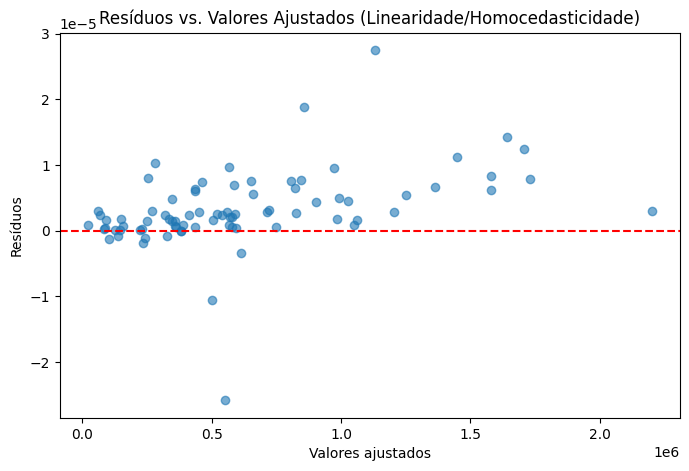


Teste de Breusch-Pagan (Homocedasticidade):
{'LM Statistic': np.float64(80.0), 'LM p-value': np.float64(1.0), 'F-Statistic': np.float64(1.9803066662700886e+20), 'F p-value': np.float64(5.651736497313765e-11)}

Durbin-Watson: 1.486 (ideal: próximo de 2)

Teste de Shapiro-Wilk (Normalidade): estatística=0.8057, p-valor=0.0000


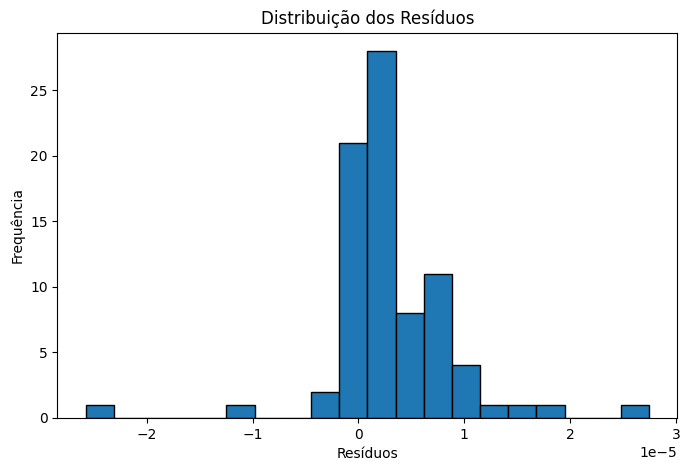

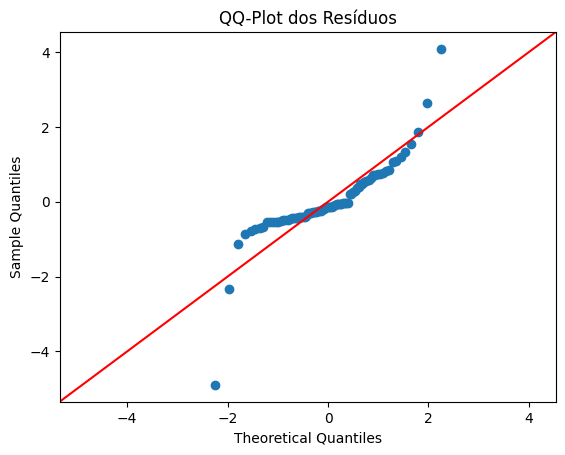

TypeError: ufunc 'isfinite' not supported for the input types, and the inputs could not be safely coerced to any supported types according to the casting rule ''safe''

In [ ]:
# ==============================================================
# REGRESSÃO LINEAR MÚLTIPLA — Dissertação (Conversação Social x Audiência Globoplay)
# Ambiente: Google Colab
# Bibliotecas: pandas + statsmodels
# ==============================================================

# --- 1. INSTALAÇÃO (rodar uma vez no Colab, se necessário) ---
# !pip install pandas statsmodels scipy matplotlib

import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson
from scipy import stats
import matplotlib.pyplot as plt

# --- 2. LEITURA DO ARQUIVO ---
# O arquivo já está no ambiente do Colab (barra lateral de arquivos),
# então basta ler direto pelo nome.
#
# Arquivos .csv exportados do Excel no Brasil podem ter dois problemas comuns:
# 1) Encoding diferente de UTF-8 (ex.: latin-1, cp1252)
# 2) Separador ";" em vez de "," -- e quando isso não é tratado, vírgulas
#    dentro de textos (ex. títulos de programas) quebram a leitura.
#
# O código abaixo tenta detectar automaticamente o separador correto (usando
# o engine "python", que consegue inferir o delimitador com sep=None),
# combinando com os encodings mais comuns.

nome_arquivo = "Base_IPsGloboplay_Mestrado.csv"

encodings_para_tentar = ["utf-8", "latin-1", "cp1252"]

df = None
erro_final = None
for enc in encodings_para_tentar:
    try:
        df = pd.read_csv(nome_arquivo, encoding=enc, sep=None, engine="python")
        print(f"Arquivo carregado com sucesso usando encoding: {enc}")
        print(f"Separador detectado automaticamente. Colunas encontradas: {list(df.columns)}")
        break
    except (UnicodeDecodeError, pd.errors.ParserError) as e:
        erro_final = e
        continue

if df is None:
    raise ValueError(
        f"Não foi possível ler o arquivo automaticamente. Último erro: {erro_final}\n"
        "Isso geralmente indica que alguma linha do arquivo está com vírgulas "
        "ou ponto-e-vírgulas inconsistentes dentro do texto (ex.: título de "
        "programa com vírgula sem estar entre aspas no CSV original). "
        "Abra o arquivo original no Excel e verifique a linha indicada no erro, "
        "ou reexporte o arquivo garantindo que campos de texto com vírgula "
        "estejam entre aspas."
    )

# Confira as primeiras linhas e os tipos de dado
print(df.head())
print(df.info())

# --- 3. DEFINIÇÃO DAS VARIÁVEIS ---
# Nomes das colunas exatamente como aparecem no arquivo original

variavel_dependente = "Alcance (90d)"

variaveis_independentes = [
    "Talkability",
    "Buzz Score",
    "Views por post",
    "Tx de Engajamento",
]

# --- 4. VERIFICAÇÃO DE DADOS FALTANTES ---
print("\nValores ausentes por coluna:")
print(df[[variavel_dependente] + variaveis_independentes].isnull().sum())

# Remova ou trate linhas com dados faltantes antes de seguir, se houver
df = df.dropna(subset=[variavel_dependente] + variaveis_independentes)

# --- 5. ESTIMAÇÃO DO MODELO DE REGRESSÃO MÚLTIPLA ---
# Usando a interface de fórmula do statsmodels (mais legível)
# Como os nomes das colunas têm espaços/parênteses, é preciso "escapar"
# cada nome com Q("...") para a fórmula funcionar corretamente.

def escapar(nome_coluna):
    return f'Q("{nome_coluna}")'

formula = f"{escapar(variavel_dependente)} ~ " + " + ".join(
    escapar(v) for v in variaveis_independentes
)
modelo = smf.ols(formula=formula, data=df).fit()

# --- 6. SAÍDA COMPLETA DO MODELO ---
# Isto já traz: coeficientes, erro padrão, valores-t, p-valores, R², R² ajustado, F-estatística
print(modelo.summary())

# --- 7. TESTES DE PRESSUPOSTOS ---

# 7.1 Linearidade e Homocedasticidade — gráfico de resíduos vs. valores ajustados
plt.figure(figsize=(8, 5))
plt.scatter(modelo.fittedvalues, modelo.resid, alpha=0.6)
plt.axhline(y=0, color="red", linestyle="--")
plt.xlabel("Valores ajustados")
plt.ylabel("Resíduos")
plt.title("Resíduos vs. Valores Ajustados (Linearidade/Homocedasticidade)")
plt.show()

# 7.2 Homocedasticidade — Teste de Breusch-Pagan
# H0: homocedasticidade (variância constante) — p > 0,05 é o resultado desejado
bp_test = het_breuschpagan(modelo.resid, modelo.model.exog)
labels = ["LM Statistic", "LM p-value", "F-Statistic", "F p-value"]
print("\nTeste de Breusch-Pagan (Homocedasticidade):")
print(dict(zip(labels, bp_test)))

# 7.3 Independência dos resíduos — Durbin-Watson
# Valores próximos de 2 indicam ausência de autocorrelação
dw = durbin_watson(modelo.resid)
print(f"\nDurbin-Watson: {dw:.3f} (ideal: próximo de 2)")

# 7.4 Normalidade dos resíduos — Shapiro-Wilk
# H0: resíduos seguem distribuição normal — p > 0,05 é o resultado desejado
shapiro_test = stats.shapiro(modelo.resid)
print(f"\nTeste de Shapiro-Wilk (Normalidade): estatística={shapiro_test[0]:.4f}, p-valor={shapiro_test[1]:.4f}")

# Histograma dos resíduos (inspeção visual da normalidade)
plt.figure(figsize=(8, 5))
plt.hist(modelo.resid, bins=20, edgecolor="black")
plt.xlabel("Resíduos")
plt.ylabel("Frequência")
plt.title("Distribuição dos Resíduos")
plt.show()

# QQ-plot (outra forma visual de checar normalidade)
sm.qqplot(modelo.resid, line="45", fit=True)
plt.title("QQ-Plot dos Resíduos")
plt.show()

# 7.5 Multicolinearidade — VIF (Fator de Inflação da Variância)
# Importante quando há mais de uma variável independente (seu caso)
from statsmodels.stats.outliers_influence import variance_inflation_factor

X = sm.add_constant(df[variaveis_independentes])
vif_data = pd.DataFrame()
vif_data["Variável"] = X.columns
vif_data["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
print("\nFator de Inflação da Variância (VIF):")
print(vif_data)
# Regra prática: VIF > 10 indica problema sério de multicolinearidade

# --- 8. EXPORTAR RESULTADOS (opcional, para anexar na dissertação) ---
with open("resultado_regressao.txt", "w") as f:
    f.write(modelo.summary().as_text())

print("\nResumo do modelo salvo em 'resultado_regressao.txt'")


Arquivo carregado com sucesso usando encoding: latin-1
Separador detectado automaticamente. Colunas encontradas: ['Título/IP', 'Temporada', 'Lançamento', 'Território', 'Gênero Principal', 'Classe', 'Vertical', 'Formato', 'Episódios', 'Alcance (90d)', 'Buzz Score', 'Talkability', 'Posts', 'Audiência (views)', 'Views por post', 'Tx de Engajamento']
                        Título/IP  Temporada  Lançamento   Território  \
0                         As Five        2.0  08/02/2023  dramaturgia   
1                          Origem        1.0  21/03/2023  dramaturgia   
2  The Good Doctor - O Bom Doutor        6.0  21/04/2023  dramaturgia   
3                       Os Outros        1.0  31/05/2023  dramaturgia   
4              A Vida Pela Frente        1.0  22/06/2023  dramaturgia   

    Gênero Principal      Classe        Vertical Formato  Episódios  \
0              Drama    original  Entretenimento  séries          8   
1  Suspense/Thriller  licenciado  Entretenimento  séries         10   

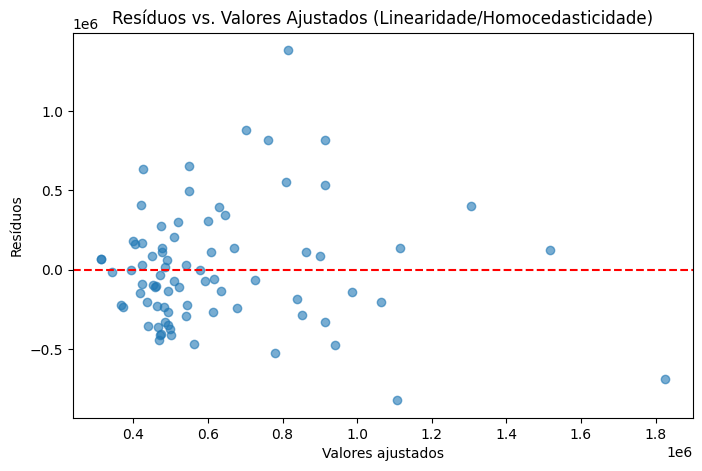


Teste de Breusch-Pagan (Homocedasticidade):
{'LM Statistic': np.float64(7.067358045428129), 'LM p-value': np.float64(0.13237118878317558), 'F-Statistic': np.float64(1.8169225712996497), 'F p-value': np.float64(0.13441885950584112)}

Durbin-Watson: 2.116 (ideal: próximo de 2)

Teste de Shapiro-Wilk (Normalidade): estatística=0.9524, p-valor=0.0047


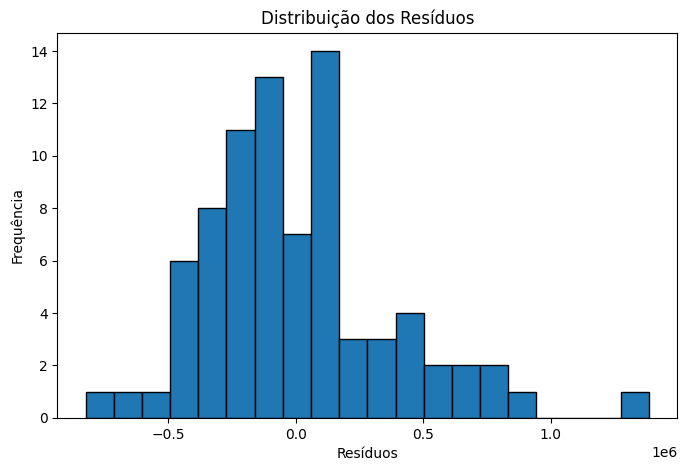

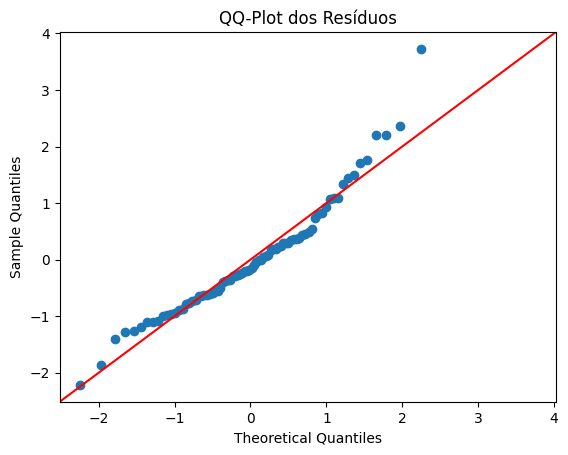


Fator de Inflação da Variância (VIF):
            Variável        VIF
0              const  10.282918
1        Talkability   1.053557
2         Buzz Score   1.028638
3     Views por post   1.051318
4  Tx de Engajamento   1.020298

Resumo do modelo salvo em 'resultado_regressao.txt'


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ==============================================================
# REGRESSÃO LINEAR MÚLTIPLA — Dissertação (Conversação Social x Audiência Globoplay)
# Ambiente: Google Colab
# Bibliotecas: pandas + statsmodels
# ==============================================================

# --- 1. INSTALAÇÃO (rodar uma vez no Colab, se necessário) ---
# !pip install pandas statsmodels scipy matplotlib

import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson
from scipy import stats
import matplotlib.pyplot as plt

# --- 2. LEITURA DO ARQUIVO ---
# O arquivo já está no ambiente do Colab (barra lateral de arquivos),
# então basta ler direto pelo nome.
#
# Arquivos .csv exportados do Excel no Brasil podem ter dois problemas comuns:
# 1) Encoding diferente de UTF-8 (ex.: latin-1, cp1252)
# 2) Separador ";" em vez de "," -- e quando isso não é tratado, vírgulas
#    dentro de textos (ex. títulos de programas) quebram a leitura.
#
# O código abaixo tenta detectar automaticamente o separador correto (usando
# o engine "python", que consegue inferir o delimitador com sep=None),
# combinando com os encodings mais comuns.

nome_arquivo = "Base_IPsGloboplay_Mestrado.csv"

encodings_para_tentar = ["utf-8", "latin-1", "cp1252"]

df = None
erro_final = None
for enc in encodings_para_tentar:
    try:
        df = pd.read_csv(nome_arquivo, encoding=enc, sep=None, engine="python")
        print(f"Arquivo carregado com sucesso usando encoding: {enc}")
        print(f"Separador detectado automaticamente. Colunas encontradas: {list(df.columns)}")
        break
    except (UnicodeDecodeError, pd.errors.ParserError) as e:
        erro_final = e
        continue

if df is None:
    raise ValueError(
        f"Não foi possível ler o arquivo automaticamente. Último erro: {erro_final}\n"
        "Isso geralmente indica que alguma linha do arquivo está com vírgulas "
        "ou ponto-e-vírgulas inconsistentes dentro do texto (ex.: título de "
        "programa com vírgula sem estar entre aspas no CSV original). "
        "Abra o arquivo original no Excel e verifique a linha indicada no erro, "
        "ou reexporte o arquivo garantindo que campos de texto com vírgula "
        "estejam entre aspas."
    )

# Confira as primeiras linhas e os tipos de dado
print(df.head())
print(df.info())

# --- 3. DEFINIÇÃO DAS VARIÁVEIS ---
# Nomes das colunas exatamente como aparecem no arquivo original

variavel_dependente = "Alcance (90d)"

variaveis_independentes = [
    "Talkability",
    "Buzz Score",
    "Views por post",
    "Tx de Engajamento",
]

# --- 3.1 DIAGNÓSTICO E LIMPEZA DE TIPOS DE DADOS ---
# Dados brasileiros exportados do Excel costumam vir como TEXTO, não número,
# por causa de vírgula decimal (ex. "12,5"), símbolo de % (ex. "12,5%") ou
# ponto como separador de milhar (ex. "1.234"). Se isso não for corrigido,
# o statsmodels trata a coluna como categórica e o modelo quebra.

print("Tipos de dados ANTES da limpeza:")
print(df[variaveis_independentes + [variavel_dependente]].dtypes)

def limpar_numero_br(coluna):
    """Converte uma coluna de texto em formato numérico brasileiro para float.
    Trata: espaços, símbolo de %, ponto de milhar e vírgula decimal."""
    if coluna.dtype == object:
        coluna = (
            coluna.astype(str)
            .str.strip()
            .str.replace("%", "", regex=False)
            .str.replace(".", "", regex=False)   # remove ponto de milhar
            .str.replace(",", ".", regex=False)   # vírgula -> ponto decimal
        )
        coluna = pd.to_numeric(coluna, errors="coerce")
    return coluna

for col in variaveis_independentes + [variavel_dependente]:
    df[col] = limpar_numero_br(df[col])

print("\nTipos de dados DEPOIS da limpeza:")
print(df[variaveis_independentes + [variavel_dependente]].dtypes)

# Se a limpeza gerou algum valor ausente (NaN) por não conseguir converter,
# isso aparece aqui -- vale checar antes de seguir:
print("\nValores que viraram NaN após a limpeza (se houver, investigue a fonte):")
print(df[variaveis_independentes + [variavel_dependente]].isnull().sum())

# --- 4. VERIFICAÇÃO DE DADOS FALTANTES ---
print("\nValores ausentes por coluna:")
print(df[[variavel_dependente] + variaveis_independentes].isnull().sum())

# Remova ou trate linhas com dados faltantes antes de seguir, se houver
df = df.dropna(subset=[variavel_dependente] + variaveis_independentes)

# --- 5. ESTIMAÇÃO DO MODELO DE REGRESSÃO MÚLTIPLA ---
# Usando a interface de fórmula do statsmodels (mais legível)
# Como os nomes das colunas têm espaços/parênteses, é preciso "escapar"
# cada nome com Q("...") para a fórmula funcionar corretamente.

def escapar(nome_coluna):
    return f'Q("{nome_coluna}")'

formula = f"{escapar(variavel_dependente)} ~ " + " + ".join(
    escapar(v) for v in variaveis_independentes
)
modelo = smf.ols(formula=formula, data=df).fit()

# --- 6. SAÍDA COMPLETA DO MODELO ---
# Isto já traz: coeficientes, erro padrão, valores-t, p-valores, R², R² ajustado, F-estatística
print(modelo.summary())

# --- 7. TESTES DE PRESSUPOSTOS ---

# 7.1 Linearidade e Homocedasticidade — gráfico de resíduos vs. valores ajustados
plt.figure(figsize=(8, 5))
plt.scatter(modelo.fittedvalues, modelo.resid, alpha=0.6)
plt.axhline(y=0, color="red", linestyle="--")
plt.xlabel("Valores ajustados")
plt.ylabel("Resíduos")
plt.title("Resíduos vs. Valores Ajustados (Linearidade/Homocedasticidade)")
plt.show()

# 7.2 Homocedasticidade — Teste de Breusch-Pagan
# H0: homocedasticidade (variância constante) — p > 0,05 é o resultado desejado
bp_test = het_breuschpagan(modelo.resid, modelo.model.exog)
labels = ["LM Statistic", "LM p-value", "F-Statistic", "F p-value"]
print("\nTeste de Breusch-Pagan (Homocedasticidade):")
print(dict(zip(labels, bp_test)))

# 7.3 Independência dos resíduos — Durbin-Watson
# Valores próximos de 2 indicam ausência de autocorrelação
dw = durbin_watson(modelo.resid)
print(f"\nDurbin-Watson: {dw:.3f} (ideal: próximo de 2)")

# 7.4 Normalidade dos resíduos — Shapiro-Wilk
# H0: resíduos seguem distribuição normal — p > 0,05 é o resultado desejado
shapiro_test = stats.shapiro(modelo.resid)
print(f"\nTeste de Shapiro-Wilk (Normalidade): estatística={shapiro_test[0]:.4f}, p-valor={shapiro_test[1]:.4f}")

# Histograma dos resíduos (inspeção visual da normalidade)
plt.figure(figsize=(8, 5))
plt.hist(modelo.resid, bins=20, edgecolor="black")
plt.xlabel("Resíduos")
plt.ylabel("Frequência")
plt.title("Distribuição dos Resíduos")
plt.show()

# QQ-plot (outra forma visual de checar normalidade)
sm.qqplot(modelo.resid, line="45", fit=True)
plt.title("QQ-Plot dos Resíduos")
plt.show()

# 7.5 Multicolinearidade — VIF (Fator de Inflação da Variância)
# Importante quando há mais de uma variável independente (seu caso)
from statsmodels.stats.outliers_influence import variance_inflation_factor

X = sm.add_constant(df[variaveis_independentes])
vif_data = pd.DataFrame()
vif_data["Variável"] = X.columns
vif_data["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
print("\nFator de Inflação da Variância (VIF):")
print(vif_data)
# Regra prática: VIF > 10 indica problema sério de multicolinearidade

# --- 8. EXPORTAR RESULTADOS (opcional, para anexar na dissertação) ---
with open("resultado_regressao.txt", "w") as f:
    f.write(modelo.summary().as_text())

print("\nResumo do modelo salvo em 'resultado_regressao.txt'")

# Baixa o arquivo automaticamente para o seu computador
from google.colab import files
files.download("resultado_regressao.txt")



Arquivo carregado com sucesso usando encoding: latin-1
Separador detectado automaticamente. Colunas encontradas: ['Título/IP', 'Temporada', 'Lançamento', 'Território', 'Gênero Principal', 'Classe', 'Vertical', 'Formato', 'Episódios', 'Alcance (90d)', 'Buzz Score', 'Talkability', 'Posts', 'Audiência (views)', 'Views por post', 'Tx de Engajamento']
                        Título/IP  Temporada  Lançamento   Território  \
0                         As Five        2.0  08/02/2023  dramaturgia   
1                          Origem        1.0  21/03/2023  dramaturgia   
2  The Good Doctor - O Bom Doutor        6.0  21/04/2023  dramaturgia   
3                       Os Outros        1.0  31/05/2023  dramaturgia   
4              A Vida Pela Frente        1.0  22/06/2023  dramaturgia   

    Gênero Principal      Classe        Vertical Formato  Episódios  \
0              Drama    original  Entretenimento  séries          8   
1  Suspense/Thriller  licenciado  Entretenimento  séries         10   

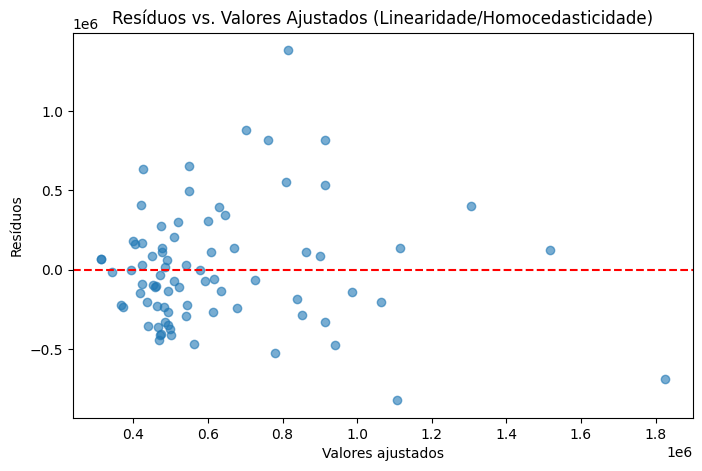


Teste de Breusch-Pagan (Homocedasticidade):
{'LM Statistic': np.float64(7.067358045428129), 'LM p-value': np.float64(0.13237118878317558), 'F-Statistic': np.float64(1.8169225712996497), 'F p-value': np.float64(0.13441885950584112)}

Durbin-Watson: 2.116 (ideal: próximo de 2)

Teste de Shapiro-Wilk (Normalidade): estatística=0.9524, p-valor=0.0047


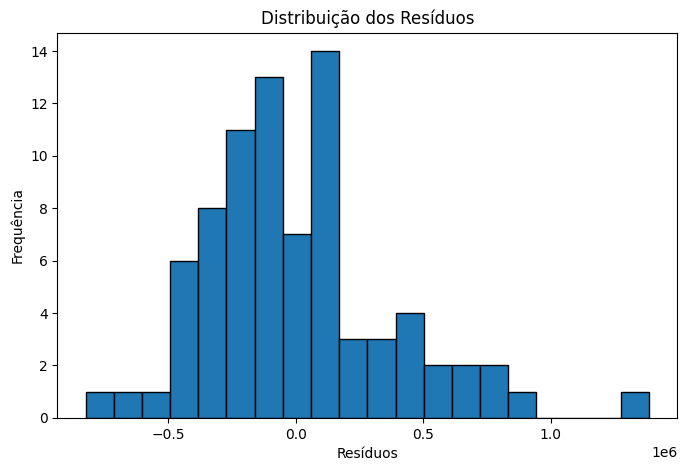

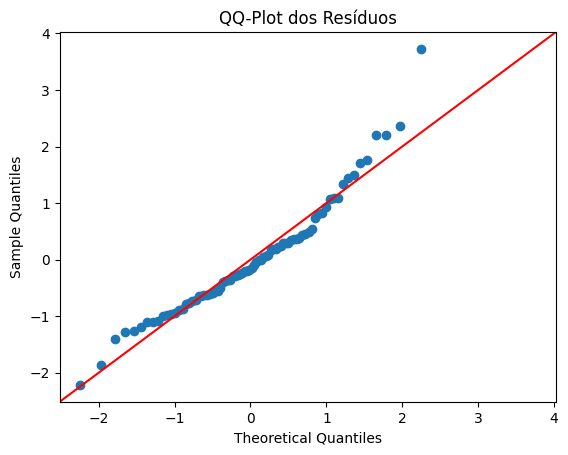


Fator de Inflação da Variância (VIF):
            Variável        VIF
0              const  10.282918
1        Talkability   1.053557
2         Buzz Score   1.028638
3     Views por post   1.051318
4  Tx de Engajamento   1.020298

Resumo do modelo salvo em 'resultado_regressao.txt'


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ==============================================================
# REGRESSÃO LINEAR MÚLTIPLA — Dissertação (Conversação Social x Audiência Globoplay)
# Ambiente: Google Colab
# Bibliotecas: pandas + statsmodels
# ==============================================================

# --- 1. INSTALAÇÃO (rodar uma vez no Colab, se necessário) ---
# !pip install pandas statsmodels scipy matplotlib

import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson
from scipy import stats
import matplotlib.pyplot as plt

# --- 2. LEITURA DO ARQUIVO ---
# O arquivo já está no ambiente do Colab (barra lateral de arquivos),
# então basta ler direto pelo nome.
#
# Arquivos .csv exportados do Excel no Brasil podem ter dois problemas comuns:
# 1) Encoding diferente de UTF-8 (ex.: latin-1, cp1252)
# 2) Separador ";" em vez de "," -- e quando isso não é tratado, vírgulas
#    dentro de textos (ex. títulos de programas) quebram a leitura.
#
# O código abaixo tenta detectar automaticamente o separador correto (usando
# o engine "python", que consegue inferir o delimitador com sep=None),
# combinando com os encodings mais comuns.

nome_arquivo = "Base_IPsGloboplay_Mestrado.csv"

encodings_para_tentar = ["utf-8", "latin-1", "cp1252"]

df = None
erro_final = None
for enc in encodings_para_tentar:
    try:
        df = pd.read_csv(nome_arquivo, encoding=enc, sep=None, engine="python")
        print(f"Arquivo carregado com sucesso usando encoding: {enc}")
        print(f"Separador detectado automaticamente. Colunas encontradas: {list(df.columns)}")
        break
    except (UnicodeDecodeError, pd.errors.ParserError) as e:
        erro_final = e
        continue

if df is None:
    raise ValueError(
        f"Não foi possível ler o arquivo automaticamente. Último erro: {erro_final}\n"
        "Isso geralmente indica que alguma linha do arquivo está com vírgulas "
        "ou ponto-e-vírgulas inconsistentes dentro do texto (ex.: título de "
        "programa com vírgula sem estar entre aspas no CSV original). "
        "Abra o arquivo original no Excel e verifique a linha indicada no erro, "
        "ou reexporte o arquivo garantindo que campos de texto com vírgula "
        "estejam entre aspas."
    )

# Confira as primeiras linhas e os tipos de dado
print(df.head())
print(df.info())

# --- 3. DEFINIÇÃO DAS VARIÁVEIS ---
# Nomes das colunas exatamente como aparecem no arquivo original

variavel_dependente = "Alcance (90d)"

variaveis_independentes = [
    "Talkability",
    "Buzz Score",
    "Views por post",
    "Tx de Engajamento",
]

# --- 3.1 DIAGNÓSTICO E LIMPEZA DE TIPOS DE DADOS ---
# Dados brasileiros exportados do Excel costumam vir como TEXTO, não número,
# por causa de vírgula decimal (ex. "12,5"), símbolo de % (ex. "12,5%") ou
# ponto como separador de milhar (ex. "1.234"). Se isso não for corrigido,
# o statsmodels trata a coluna como categórica e o modelo quebra.

print("Tipos de dados ANTES da limpeza:")
print(df[variaveis_independentes + [variavel_dependente]].dtypes)

def limpar_numero_br(coluna):
    """Converte uma coluna de texto em formato numérico brasileiro para float.
    Trata: espaços, símbolo de %, ponto de milhar e vírgula decimal."""
    if coluna.dtype == object:
        coluna = (
            coluna.astype(str)
            .str.strip()
            .str.replace("%", "", regex=False)
            .str.replace(".", "", regex=False)   # remove ponto de milhar
            .str.replace(",", ".", regex=False)   # vírgula -> ponto decimal
        )
        coluna = pd.to_numeric(coluna, errors="coerce")
    return coluna

for col in variaveis_independentes + [variavel_dependente]:
    df[col] = limpar_numero_br(df[col])

print("\nTipos de dados DEPOIS da limpeza:")
print(df[variaveis_independentes + [variavel_dependente]].dtypes)

# Se a limpeza gerou algum valor ausente (NaN) por não conseguir converter,
# isso aparece aqui -- vale checar antes de seguir:
print("\nValores que viraram NaN após a limpeza (se houver, investigue a fonte):")
print(df[variaveis_independentes + [variavel_dependente]].isnull().sum())

# --- 4. VERIFICAÇÃO DE DADOS FALTANTES ---
print("\nValores ausentes por coluna:")
print(df[[variavel_dependente] + variaveis_independentes].isnull().sum())

# Remova ou trate linhas com dados faltantes antes de seguir, se houver
df = df.dropna(subset=[variavel_dependente] + variaveis_independentes)

# --- 5. ESTIMAÇÃO DO MODELO DE REGRESSÃO MÚLTIPLA ---
# Usando a interface de fórmula do statsmodels (mais legível)
# Como os nomes das colunas têm espaços/parênteses, é preciso "escapar"
# cada nome com Q("...") para a fórmula funcionar corretamente.

def escapar(nome_coluna):
    return f'Q("{nome_coluna}")'

formula = f"{escapar(variavel_dependente)} ~ " + " + ".join(
    escapar(v) for v in variaveis_independentes
)
modelo = smf.ols(formula=formula, data=df).fit()

# --- 6. SAÍDA COMPLETA DO MODELO ---
# Isto já traz: coeficientes, erro padrão, valores-t, p-valores, R², R² ajustado, F-estatística
print(modelo.summary())

# --- 6.1 MODELO PADRONIZADO (Z-SCORE) — para resolver problema de escala ---
# O número de condição alto (Cond. No.) no modelo acima geralmente indica que
# as variáveis estão em escalas muito diferentes entre si (ex. Talkability em
# unidades pequenas vs. Alcance na casa de centenas de milhares), e não
# necessariamente multicolinearidade real.
#
# Padronizar (transformar cada variável para média 0 e desvio padrão 1) resolve
# o problema numérico E torna os coeficientes comparáveis entre si — o maior
# coeficiente padronizado indica a variável com maior peso relativo no modelo.

from scipy.stats import zscore

df_padronizado = df.copy()
todas_variaveis = [variavel_dependente] + variaveis_independentes

for col in todas_variaveis:
    df_padronizado[col] = zscore(df_padronizado[col])

formula_padronizada = f"{escapar(variavel_dependente)} ~ " + " + ".join(
    escapar(v) for v in variaveis_independentes
)
modelo_padronizado = smf.ols(formula=formula_padronizada, data=df_padronizado).fit()

print("\n" + "=" * 78)
print("MODELO PADRONIZADO (coeficientes comparáveis entre si)")
print("=" * 78)
print(modelo_padronizado.summary())

# --- 7. TESTES DE PRESSUPOSTOS ---

# 7.1 Linearidade e Homocedasticidade — gráfico de resíduos vs. valores ajustados
plt.figure(figsize=(8, 5))
plt.scatter(modelo.fittedvalues, modelo.resid, alpha=0.6)
plt.axhline(y=0, color="red", linestyle="--")
plt.xlabel("Valores ajustados")
plt.ylabel("Resíduos")
plt.title("Resíduos vs. Valores Ajustados (Linearidade/Homocedasticidade)")
plt.show()

# 7.2 Homocedasticidade — Teste de Breusch-Pagan
# H0: homocedasticidade (variância constante) — p > 0,05 é o resultado desejado
bp_test = het_breuschpagan(modelo.resid, modelo.model.exog)
labels = ["LM Statistic", "LM p-value", "F-Statistic", "F p-value"]
print("\nTeste de Breusch-Pagan (Homocedasticidade):")
print(dict(zip(labels, bp_test)))

# 7.3 Independência dos resíduos — Durbin-Watson
# Valores próximos de 2 indicam ausência de autocorrelação
dw = durbin_watson(modelo.resid)
print(f"\nDurbin-Watson: {dw:.3f} (ideal: próximo de 2)")

# 7.4 Normalidade dos resíduos — Shapiro-Wilk
# H0: resíduos seguem distribuição normal — p > 0,05 é o resultado desejado
shapiro_test = stats.shapiro(modelo.resid)
print(f"\nTeste de Shapiro-Wilk (Normalidade): estatística={shapiro_test[0]:.4f}, p-valor={shapiro_test[1]:.4f}")

# Histograma dos resíduos (inspeção visual da normalidade)
plt.figure(figsize=(8, 5))
plt.hist(modelo.resid, bins=20, edgecolor="black")
plt.xlabel("Resíduos")
plt.ylabel("Frequência")
plt.title("Distribuição dos Resíduos")
plt.show()

# QQ-plot (outra forma visual de checar normalidade)
sm.qqplot(modelo.resid, line="45", fit=True)
plt.title("QQ-Plot dos Resíduos")
plt.show()

# 7.5 Multicolinearidade — VIF (Fator de Inflação da Variância)
# Importante quando há mais de uma variável independente (seu caso)
from statsmodels.stats.outliers_influence import variance_inflation_factor

X = sm.add_constant(df[variaveis_independentes])
vif_data = pd.DataFrame()
vif_data["Variável"] = X.columns
vif_data["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
print("\nFator de Inflação da Variância (VIF):")
print(vif_data)
# Regra prática: VIF > 10 indica problema sério de multicolinearidade

# --- 8. EXPORTAR RESULTADOS (opcional, para anexar na dissertação) ---
with open("resultado_regressao.txt", "w") as f:
    f.write(modelo.summary().as_text())

print("\nResumo do modelo salvo em 'resultado_regressao.txt'")

# Baixa o arquivo automaticamente para o seu computador
from google.colab import files
files.download("resultado_regressao.txt")


Arquivo carregado com sucesso usando encoding: latin-1
Separador detectado automaticamente. Colunas encontradas: ['Título/IP', 'Temporada', 'Lançamento', 'Território', 'Gênero Principal', 'Classe', 'Vertical', 'Formato', 'Episódios', 'Alcance (90d)', 'Buzz Score', 'Talkability', 'Posts', 'Audiência (views)', 'Views por post', 'Tx de Engajamento']
                        Título/IP  Temporada  Lançamento   Território  \
0                         As Five        2.0  08/02/2023  dramaturgia   
1                          Origem        1.0  21/03/2023  dramaturgia   
2  The Good Doctor - O Bom Doutor        6.0  21/04/2023  dramaturgia   
3                       Os Outros        1.0  31/05/2023  dramaturgia   
4              A Vida Pela Frente        1.0  22/06/2023  dramaturgia   

    Gênero Principal      Classe        Vertical Formato  Episódios  \
0              Drama    original  Entretenimento  séries          8   
1  Suspense/Thriller  licenciado  Entretenimento  séries         10   

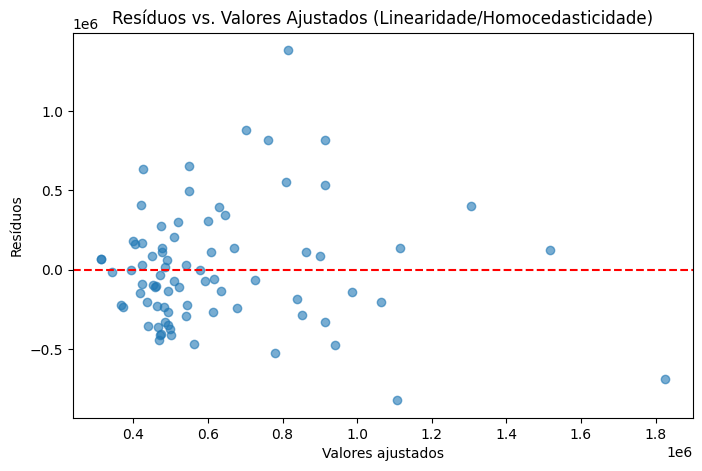


Teste de Breusch-Pagan (Homocedasticidade):
{'LM Statistic': np.float64(7.067358045428129), 'LM p-value': np.float64(0.13237118878317558), 'F-Statistic': np.float64(1.8169225712996497), 'F p-value': np.float64(0.13441885950584112)}

Durbin-Watson: 2.116 (ideal: próximo de 2)

Teste de Shapiro-Wilk (Normalidade): estatística=0.9524, p-valor=0.0047


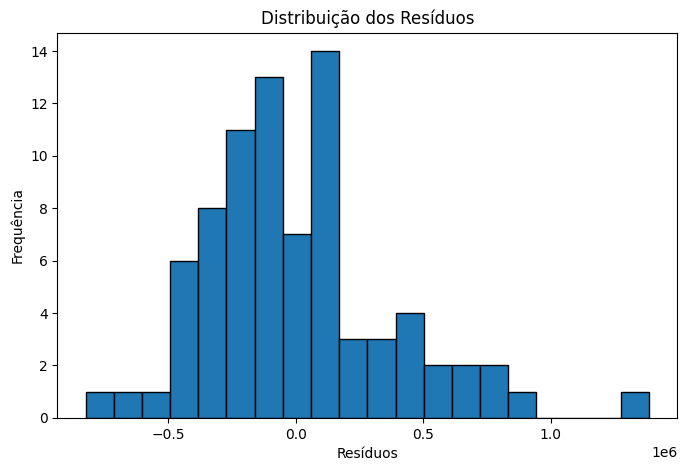

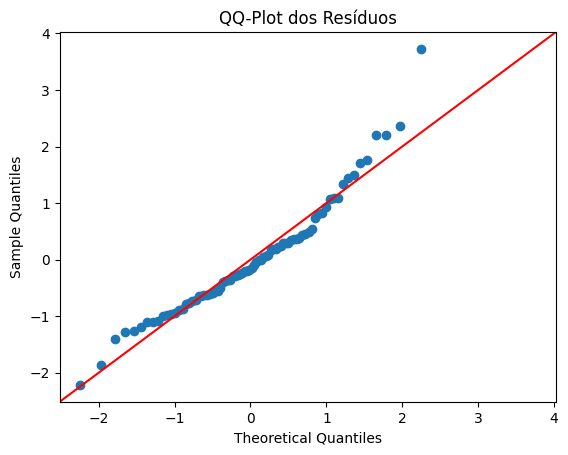


Fator de Inflação da Variância (VIF):
            Variável        VIF
0              const  10.282918
1        Talkability   1.053557
2         Buzz Score   1.028638
3     Views por post   1.051318
4  Tx de Engajamento   1.020298

Resumo do modelo salvo em 'resultado_regressao.txt'


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ==============================================================
# REGRESSÃO LINEAR MÚLTIPLA — Dissertação (Conversação Social x Audiência Globoplay)
# Ambiente: Google Colab
# Bibliotecas: pandas + statsmodels
# ==============================================================

# --- 1. INSTALAÇÃO (rodar uma vez no Colab, se necessário) ---
# !pip install pandas statsmodels scipy matplotlib

import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson
from scipy import stats
import matplotlib.pyplot as plt

# --- 2. LEITURA DO ARQUIVO ---
# O arquivo já está no ambiente do Colab (barra lateral de arquivos),
# então basta ler direto pelo nome.
#
# Arquivos .csv exportados do Excel no Brasil podem ter dois problemas comuns:
# 1) Encoding diferente de UTF-8 (ex.: latin-1, cp1252)
# 2) Separador ";" em vez de "," -- e quando isso não é tratado, vírgulas
#    dentro de textos (ex. títulos de programas) quebram a leitura.
#
# O código abaixo tenta detectar automaticamente o separador correto (usando
# o engine "python", que consegue inferir o delimitador com sep=None),
# combinando com os encodings mais comuns.

nome_arquivo = "Base_IPsGloboplay_Mestrado.csv"

encodings_para_tentar = ["utf-8", "latin-1", "cp1252"]

df = None
erro_final = None
for enc in encodings_para_tentar:
    try:
        df = pd.read_csv(nome_arquivo, encoding=enc, sep=None, engine="python")
        print(f"Arquivo carregado com sucesso usando encoding: {enc}")
        print(f"Separador detectado automaticamente. Colunas encontradas: {list(df.columns)}")
        break
    except (UnicodeDecodeError, pd.errors.ParserError) as e:
        erro_final = e
        continue

if df is None:
    raise ValueError(
        f"Não foi possível ler o arquivo automaticamente. Último erro: {erro_final}\n"
        "Isso geralmente indica que alguma linha do arquivo está com vírgulas "
        "ou ponto-e-vírgulas inconsistentes dentro do texto (ex.: título de "
        "programa com vírgula sem estar entre aspas no CSV original). "
        "Abra o arquivo original no Excel e verifique a linha indicada no erro, "
        "ou reexporte o arquivo garantindo que campos de texto com vírgula "
        "estejam entre aspas."
    )

# Confira as primeiras linhas e os tipos de dado
print(df.head())
print(df.info())

# --- 3. DEFINIÇÃO DAS VARIÁVEIS ---
# Nomes das colunas exatamente como aparecem no arquivo original

variavel_dependente = "Alcance (90d)"

variaveis_independentes = [
    "Talkability",
    "Buzz Score",
    "Views por post",
    "Tx de Engajamento",
]

# --- 3.1 DIAGNÓSTICO E LIMPEZA DE TIPOS DE DADOS ---
# Dados brasileiros exportados do Excel costumam vir como TEXTO, não número,
# por causa de vírgula decimal (ex. "12,5"), símbolo de % (ex. "12,5%") ou
# ponto como separador de milhar (ex. "1.234"). Se isso não for corrigido,
# o statsmodels trata a coluna como categórica e o modelo quebra.

print("Tipos de dados ANTES da limpeza:")
print(df[variaveis_independentes + [variavel_dependente]].dtypes)

def limpar_numero_br(coluna):
    """Converte uma coluna de texto em formato numérico brasileiro para float.
    Trata: espaços, símbolo de %, ponto de milhar e vírgula decimal."""
    if coluna.dtype == object:
        coluna = (
            coluna.astype(str)
            .str.strip()
            .str.replace("%", "", regex=False)
            .str.replace(".", "", regex=False)   # remove ponto de milhar
            .str.replace(",", ".", regex=False)   # vírgula -> ponto decimal
        )
        coluna = pd.to_numeric(coluna, errors="coerce")
    return coluna

for col in variaveis_independentes + [variavel_dependente]:
    df[col] = limpar_numero_br(df[col])

print("\nTipos de dados DEPOIS da limpeza:")
print(df[variaveis_independentes + [variavel_dependente]].dtypes)

# Se a limpeza gerou algum valor ausente (NaN) por não conseguir converter,
# isso aparece aqui -- vale checar antes de seguir:
print("\nValores que viraram NaN após a limpeza (se houver, investigue a fonte):")
print(df[variaveis_independentes + [variavel_dependente]].isnull().sum())

# --- 4. VERIFICAÇÃO DE DADOS FALTANTES ---
print("\nValores ausentes por coluna:")
print(df[[variavel_dependente] + variaveis_independentes].isnull().sum())

# Remova ou trate linhas com dados faltantes antes de seguir, se houver
df = df.dropna(subset=[variavel_dependente] + variaveis_independentes)

# --- 5. ESTIMAÇÃO DO MODELO DE REGRESSÃO MÚLTIPLA ---
# Usando a interface de fórmula do statsmodels (mais legível)
# Como os nomes das colunas têm espaços/parênteses, é preciso "escapar"
# cada nome com Q("...") para a fórmula funcionar corretamente.

def escapar(nome_coluna):
    return f'Q("{nome_coluna}")'

formula = f"{escapar(variavel_dependente)} ~ " + " + ".join(
    escapar(v) for v in variaveis_independentes
)
modelo = smf.ols(formula=formula, data=df).fit()

# --- 6. SAÍDA COMPLETA DO MODELO ---
# Isto já traz: coeficientes, erro padrão, valores-t, p-valores, R², R² ajustado, F-estatística
print(modelo.summary())

# --- 6.1 MODELO PADRONIZADO (Z-SCORE) — para resolver problema de escala ---
# O número de condição alto (Cond. No.) no modelo acima geralmente indica que
# as variáveis estão em escalas muito diferentes entre si (ex. Talkability em
# unidades pequenas vs. Alcance na casa de centenas de milhares), e não
# necessariamente multicolinearidade real.
#
# Padronizar (transformar cada variável para média 0 e desvio padrão 1) resolve
# o problema numérico E torna os coeficientes comparáveis entre si — o maior
# coeficiente padronizado indica a variável com maior peso relativo no modelo.

from scipy.stats import zscore

df_padronizado = df.copy()
todas_variaveis = [variavel_dependente] + variaveis_independentes

for col in todas_variaveis:
    df_padronizado[col] = zscore(df_padronizado[col])

formula_padronizada = f"{escapar(variavel_dependente)} ~ " + " + ".join(
    escapar(v) for v in variaveis_independentes
)
modelo_padronizado = smf.ols(formula=formula_padronizada, data=df_padronizado).fit()

print("\n" + "=" * 78)
print("MODELO PADRONIZADO (coeficientes comparáveis entre si)")
print("=" * 78)
print(modelo_padronizado.summary())

# --- 7. TESTES DE PRESSUPOSTOS ---

# 7.1 Linearidade e Homocedasticidade — gráfico de resíduos vs. valores ajustados
plt.figure(figsize=(8, 5))
plt.scatter(modelo.fittedvalues, modelo.resid, alpha=0.6)
plt.axhline(y=0, color="red", linestyle="--")
plt.xlabel("Valores ajustados")
plt.ylabel("Resíduos")
plt.title("Resíduos vs. Valores Ajustados (Linearidade/Homocedasticidade)")
plt.show()

# 7.2 Homocedasticidade — Teste de Breusch-Pagan
# H0: homocedasticidade (variância constante) — p > 0,05 é o resultado desejado
bp_test = het_breuschpagan(modelo.resid, modelo.model.exog)
labels = ["LM Statistic", "LM p-value", "F-Statistic", "F p-value"]
print("\nTeste de Breusch-Pagan (Homocedasticidade):")
print(dict(zip(labels, bp_test)))

# 7.3 Independência dos resíduos — Durbin-Watson
# Valores próximos de 2 indicam ausência de autocorrelação
dw = durbin_watson(modelo.resid)
print(f"\nDurbin-Watson: {dw:.3f} (ideal: próximo de 2)")

# 7.4 Normalidade dos resíduos — Shapiro-Wilk
# H0: resíduos seguem distribuição normal — p > 0,05 é o resultado desejado
shapiro_test = stats.shapiro(modelo.resid)
print(f"\nTeste de Shapiro-Wilk (Normalidade): estatística={shapiro_test[0]:.4f}, p-valor={shapiro_test[1]:.4f}")

# Histograma dos resíduos (inspeção visual da normalidade)
plt.figure(figsize=(8, 5))
plt.hist(modelo.resid, bins=20, edgecolor="black")
plt.xlabel("Resíduos")
plt.ylabel("Frequência")
plt.title("Distribuição dos Resíduos")
plt.show()

# QQ-plot (outra forma visual de checar normalidade)
sm.qqplot(modelo.resid, line="45", fit=True)
plt.title("QQ-Plot dos Resíduos")
plt.show()

# 7.5 Multicolinearidade — VIF (Fator de Inflação da Variância)
# Importante quando há mais de uma variável independente (seu caso)
from statsmodels.stats.outliers_influence import variance_inflation_factor

X = sm.add_constant(df[variaveis_independentes])
vif_data = pd.DataFrame()
vif_data["Variável"] = X.columns
vif_data["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
print("\nFator de Inflação da Variância (VIF):")
print(vif_data)
# Regra prática: VIF > 10 indica problema sério de multicolinearidade

# --- 8. EXPORTAR RESULTADOS (opcional, para anexar na dissertação) ---
with open("resultado_regressao.txt", "w") as f:
    f.write(modelo.summary().as_text())

print("\nResumo do modelo salvo em 'resultado_regressao.txt'")

# Baixa o arquivo automaticamente para o seu computador
from google.colab import files
files.download("resultado_regressao.txt")

Arquivo carregado com sucesso usando encoding: latin-1
Separador detectado automaticamente. Colunas encontradas: ['Título/IP', 'Temporada', 'Lançamento', 'Território', 'Gênero Principal', 'Classe', 'Vertical', 'Formato', 'Episódios', 'Alcance (90d)', 'Buzz Score', 'Talkability', 'Posts', 'Audiência (views)', 'Views por post', 'Tx de Engajamento']
                        Título/IP  Temporada  Lançamento   Território  \
0                         As Five        2.0  08/02/2023  dramaturgia   
1                          Origem        1.0  21/03/2023  dramaturgia   
2  The Good Doctor - O Bom Doutor        6.0  21/04/2023  dramaturgia   
3                       Os Outros        1.0  31/05/2023  dramaturgia   
4              A Vida Pela Frente        1.0  22/06/2023  dramaturgia   

    Gênero Principal      Classe        Vertical Formato  Episódios  \
0              Drama    original  Entretenimento  séries          8   
1  Suspense/Thriller  licenciado  Entretenimento  séries         10   

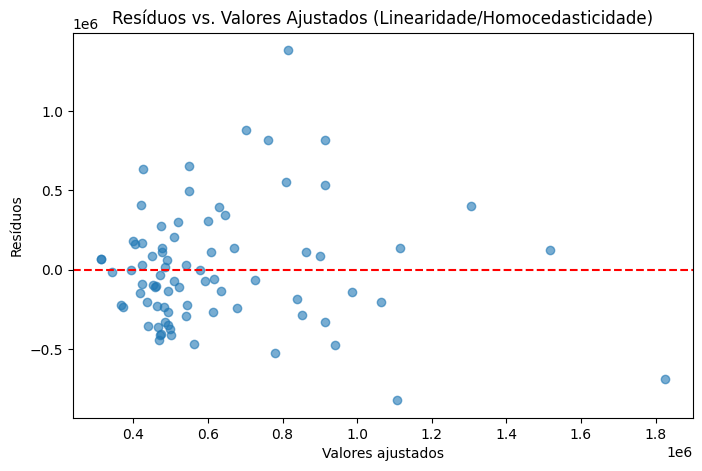


Teste de Breusch-Pagan (Homocedasticidade):
{'LM Statistic': np.float64(7.067358045428129), 'LM p-value': np.float64(0.13237118878317558), 'F-Statistic': np.float64(1.8169225712996497), 'F p-value': np.float64(0.13441885950584112)}

Durbin-Watson: 2.116 (ideal: próximo de 2)

Teste de Shapiro-Wilk (Normalidade): estatística=0.9524, p-valor=0.0047


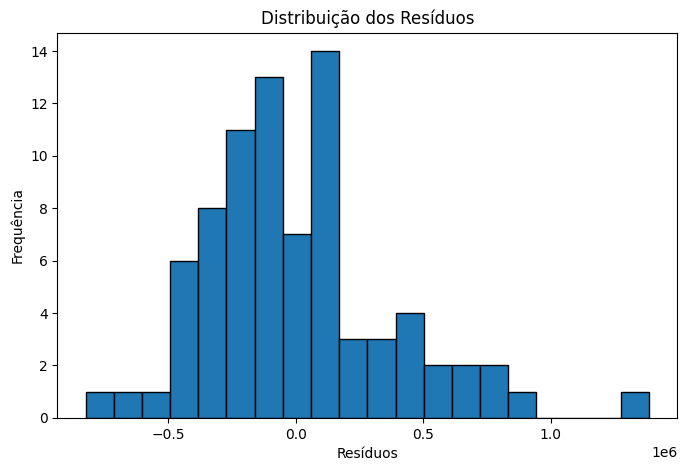

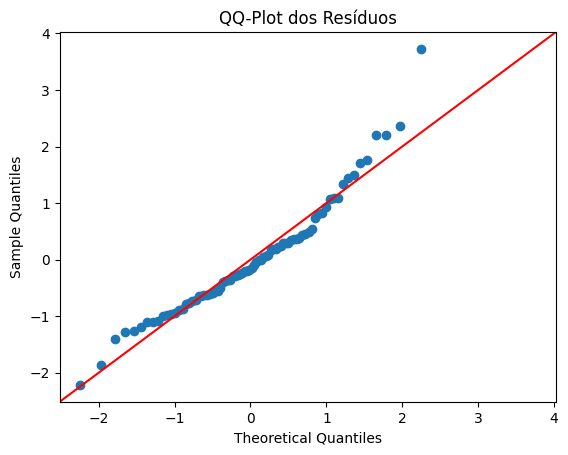


Fator de Inflação da Variância (VIF):
            Variável        VIF
0              const  10.282918
1        Talkability   1.053557
2         Buzz Score   1.028638
3     Views por post   1.051318
4  Tx de Engajamento   1.020298

Resumo do modelo salvo em 'resultado_regressao.txt'


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ==============================================================
# REGRESSÃO LINEAR MÚLTIPLA — Dissertação (Conversação Social x Audiência Globoplay)
# Ambiente: Google Colab
# Bibliotecas: pandas + statsmodels
# ==============================================================

# --- 1. INSTALAÇÃO (rodar uma vez no Colab, se necessário) ---
# !pip install pandas statsmodels scipy matplotlib

import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson
from scipy import stats
import matplotlib.pyplot as plt

# --- 2. LEITURA DO ARQUIVO ---
# O arquivo já está no ambiente do Colab (barra lateral de arquivos),
# então basta ler direto pelo nome.
#
# Arquivos .csv exportados do Excel no Brasil podem ter dois problemas comuns:
# 1) Encoding diferente de UTF-8 (ex.: latin-1, cp1252)
# 2) Separador ";" em vez de "," -- e quando isso não é tratado, vírgulas
#    dentro de textos (ex. títulos de programas) quebram a leitura.
#
# O código abaixo tenta detectar automaticamente o separador correto (usando
# o engine "python", que consegue inferir o delimitador com sep=None),
# combinando com os encodings mais comuns.

nome_arquivo = "Base_IPsGloboplay_Mestrado.csv"

encodings_para_tentar = ["utf-8", "latin-1", "cp1252"]

df = None
erro_final = None
for enc in encodings_para_tentar:
    try:
        df = pd.read_csv(nome_arquivo, encoding=enc, sep=None, engine="python")
        print(f"Arquivo carregado com sucesso usando encoding: {enc}")
        print(f"Separador detectado automaticamente. Colunas encontradas: {list(df.columns)}")
        break
    except (UnicodeDecodeError, pd.errors.ParserError) as e:
        erro_final = e
        continue

if df is None:
    raise ValueError(
        f"Não foi possível ler o arquivo automaticamente. Último erro: {erro_final}\n"
        "Isso geralmente indica que alguma linha do arquivo está com vírgulas "
        "ou ponto-e-vírgulas inconsistentes dentro do texto (ex.: título de "
        "programa com vírgula sem estar entre aspas no CSV original). "
        "Abra o arquivo original no Excel e verifique a linha indicada no erro, "
        "ou reexporte o arquivo garantindo que campos de texto com vírgula "
        "estejam entre aspas."
    )

# Confira as primeiras linhas e os tipos de dado
print(df.head())
print(df.info())

# --- 3. DEFINIÇÃO DAS VARIÁVEIS ---
# Nomes das colunas exatamente como aparecem no arquivo original

variavel_dependente = "Alcance (90d)"

variaveis_independentes = [
    "Talkability",
    "Buzz Score",
    "Views por post",
    "Tx de Engajamento",
]

# --- 3.1 DIAGNÓSTICO E LIMPEZA DE TIPOS DE DADOS ---
# Dados brasileiros exportados do Excel costumam vir como TEXTO, não número,
# por causa de vírgula decimal (ex. "12,5"), símbolo de % (ex. "12,5%") ou
# ponto como separador de milhar (ex. "1.234"). Se isso não for corrigido,
# o statsmodels trata a coluna como categórica e o modelo quebra.

print("Tipos de dados ANTES da limpeza:")
print(df[variaveis_independentes + [variavel_dependente]].dtypes)

def limpar_numero_br(coluna):
    """Converte uma coluna de texto em formato numérico brasileiro para float.
    Trata: espaços, símbolo de %, ponto de milhar e vírgula decimal."""
    if coluna.dtype == object:
        coluna = (
            coluna.astype(str)
            .str.strip()
            .str.replace("%", "", regex=False)
            .str.replace(".", "", regex=False)   # remove ponto de milhar
            .str.replace(",", ".", regex=False)   # vírgula -> ponto decimal
        )
        coluna = pd.to_numeric(coluna, errors="coerce")
    return coluna

for col in variaveis_independentes + [variavel_dependente]:
    df[col] = limpar_numero_br(df[col])

print("\nTipos de dados DEPOIS da limpeza:")
print(df[variaveis_independentes + [variavel_dependente]].dtypes)

# Se a limpeza gerou algum valor ausente (NaN) por não conseguir converter,
# isso aparece aqui -- vale checar antes de seguir:
print("\nValores que viraram NaN após a limpeza (se houver, investigue a fonte):")
print(df[variaveis_independentes + [variavel_dependente]].isnull().sum())

# --- 4. VERIFICAÇÃO DE DADOS FALTANTES ---
print("\nValores ausentes por coluna:")
print(df[[variavel_dependente] + variaveis_independentes].isnull().sum())

# Remova ou trate linhas com dados faltantes antes de seguir, se houver
df = df.dropna(subset=[variavel_dependente] + variaveis_independentes)

# --- 5. ESTIMAÇÃO DO MODELO DE REGRESSÃO MÚLTIPLA ---
# Usando a interface de fórmula do statsmodels (mais legível)
# Como os nomes das colunas têm espaços/parênteses, é preciso "escapar"
# cada nome com Q("...") para a fórmula funcionar corretamente.

def escapar(nome_coluna):
    return f'Q("{nome_coluna}")'

formula = f"{escapar(variavel_dependente)} ~ " + " + ".join(
    escapar(v) for v in variaveis_independentes
)
modelo = smf.ols(formula=formula, data=df).fit()

# --- 6. SAÍDA COMPLETA DO MODELO ---
# Isto já traz: coeficientes, erro padrão, valores-t, p-valores, R², R² ajustado, F-estatística
print(modelo.summary())

# --- 6.1 MODELO PADRONIZADO (Z-SCORE) — para resolver problema de escala ---
# O número de condição alto (Cond. No.) no modelo acima geralmente indica que
# as variáveis estão em escalas muito diferentes entre si (ex. Talkability em
# unidades pequenas vs. Alcance na casa de centenas de milhares), e não
# necessariamente multicolinearidade real.
#
# Padronizar (transformar cada variável para média 0 e desvio padrão 1) resolve
# o problema numérico E torna os coeficientes comparáveis entre si — o maior
# coeficiente padronizado indica a variável com maior peso relativo no modelo.

from scipy.stats import zscore

df_padronizado = df.copy()
todas_variaveis = [variavel_dependente] + variaveis_independentes

for col in todas_variaveis:
    df_padronizado[col] = zscore(df_padronizado[col])

formula_padronizada = f"{escapar(variavel_dependente)} ~ " + " + ".join(
    escapar(v) for v in variaveis_independentes
)
modelo_padronizado = smf.ols(formula=formula_padronizada, data=df_padronizado).fit()

print("\n" + "=" * 78)
print("MODELO PADRONIZADO (coeficientes comparáveis entre si)")
print("=" * 78)
print(modelo_padronizado.summary())

# --- 7. TESTES DE PRESSUPOSTOS ---

# 7.1 Linearidade e Homocedasticidade — gráfico de resíduos vs. valores ajustados
plt.figure(figsize=(8, 5))
plt.scatter(modelo.fittedvalues, modelo.resid, alpha=0.6)
plt.axhline(y=0, color="red", linestyle="--")
plt.xlabel("Valores ajustados")
plt.ylabel("Resíduos")
plt.title("Resíduos vs. Valores Ajustados (Linearidade/Homocedasticidade)")
plt.show()

# 7.2 Homocedasticidade — Teste de Breusch-Pagan
# H0: homocedasticidade (variância constante) — p > 0,05 é o resultado desejado
bp_test = het_breuschpagan(modelo.resid, modelo.model.exog)
labels = ["LM Statistic", "LM p-value", "F-Statistic", "F p-value"]
print("\nTeste de Breusch-Pagan (Homocedasticidade):")
print(dict(zip(labels, bp_test)))

# 7.3 Independência dos resíduos — Durbin-Watson
# Valores próximos de 2 indicam ausência de autocorrelação
dw = durbin_watson(modelo.resid)
print(f"\nDurbin-Watson: {dw:.3f} (ideal: próximo de 2)")

# 7.4 Normalidade dos resíduos — Shapiro-Wilk
# H0: resíduos seguem distribuição normal — p > 0,05 é o resultado desejado
shapiro_test = stats.shapiro(modelo.resid)
print(f"\nTeste de Shapiro-Wilk (Normalidade): estatística={shapiro_test[0]:.4f}, p-valor={shapiro_test[1]:.4f}")

# Histograma dos resíduos (inspeção visual da normalidade)
plt.figure(figsize=(8, 5))
plt.hist(modelo.resid, bins=20, edgecolor="black")
plt.xlabel("Resíduos")
plt.ylabel("Frequência")
plt.title("Distribuição dos Resíduos")
plt.show()

# QQ-plot (outra forma visual de checar normalidade)
sm.qqplot(modelo.resid, line="45", fit=True)
plt.title("QQ-Plot dos Resíduos")
plt.show()

# 7.5 Multicolinearidade — VIF (Fator de Inflação da Variância)
# Importante quando há mais de uma variável independente (seu caso)
from statsmodels.stats.outliers_influence import variance_inflation_factor

X = sm.add_constant(df[variaveis_independentes])
vif_data = pd.DataFrame()
vif_data["Variável"] = X.columns
vif_data["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
print("\nFator de Inflação da Variância (VIF):")
print(vif_data)
# Regra prática: VIF > 10 indica problema sério de multicolinearidade

# --- 8. EXPORTAR RESULTADOS (opcional, para anexar na dissertação) ---
with open("resultado_regressao.txt", "w") as f:
    f.write(modelo.summary().as_text())

print("\nResumo do modelo salvo em 'resultado_regressao.txt'")

# Baixa o arquivo automaticamente para o seu computador
from google.colab import files
files.download("resultado_regressao.txt")


Arquivo carregado com sucesso usando encoding: latin-1
Separador detectado automaticamente. Colunas encontradas: ['Título/IP', 'Temporada', 'Lançamento', 'Território', 'Gênero Principal', 'Classe', 'Vertical', 'Formato', 'Episódios', 'Alcance (90d)', 'Buzz Score', 'Talkability', 'Posts', 'Audiência (views)', 'Views por post', 'Tx de Engajamento']
                        Título/IP  Temporada  Lançamento   Território  \
0                         As Five        2.0  08/02/2023  dramaturgia   
1                          Origem        1.0  21/03/2023  dramaturgia   
2  The Good Doctor - O Bom Doutor        6.0  21/04/2023  dramaturgia   
3                       Os Outros        1.0  31/05/2023  dramaturgia   
4              A Vida Pela Frente        1.0  22/06/2023  dramaturgia   

    Gênero Principal      Classe        Vertical Formato  Episódios  \
0              Drama    original  Entretenimento  séries          8   
1  Suspense/Thriller  licenciado  Entretenimento  séries         10   

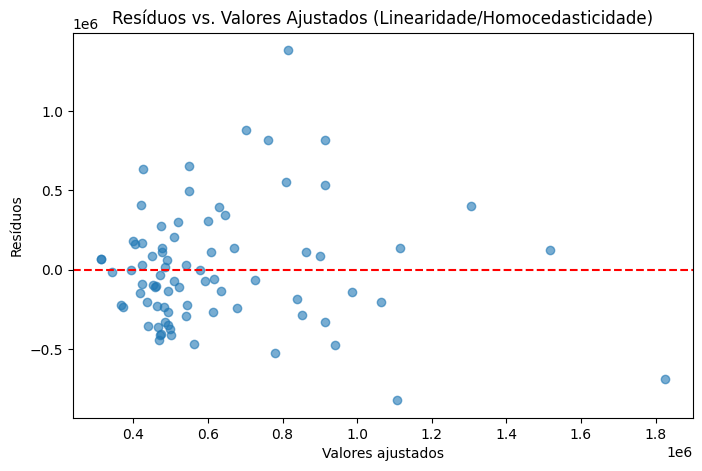


Teste de Breusch-Pagan (Homocedasticidade):
{'LM Statistic': np.float64(7.067358045428129), 'LM p-value': np.float64(0.13237118878317558), 'F-Statistic': np.float64(1.8169225712996497), 'F p-value': np.float64(0.13441885950584112)}

Durbin-Watson: 2.116 (ideal: próximo de 2)

Teste de Shapiro-Wilk (Normalidade): estatística=0.9524, p-valor=0.0047


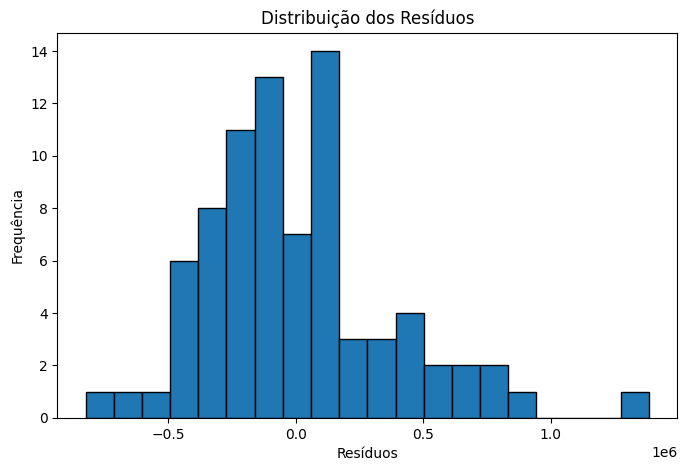

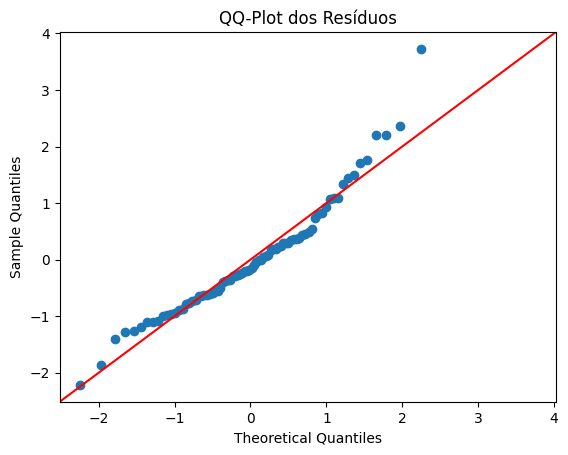


Fator de Inflação da Variância (VIF):
            Variável        VIF
0              const  10.282918
1        Talkability   1.053557
2         Buzz Score   1.028638
3     Views por post   1.051318
4  Tx de Engajamento   1.020298

Limite de referência para Distância de Cook (4/n): 0.0500

Casos com resíduo padronizado > |3| (outliers pelo critério de resíduo):
           Título/IP  Residuo_Padronizado  Distancia_Cook
72  Arcanjo Renegado             3.659457        0.077815

Casos com Distância de Cook acima do limite (observações influentes):
               Título/IP  Residuo_Padronizado  Distancia_Cook
34  Pra Sempre Paquitas             -2.397774        0.887464
63                Chaves            -2.247004        0.097624
72      Arcanjo Renegado             3.659457        0.077815

Diagnóstico específico para 'Arcanjo Renegado':
           Título/IP  Alcance (90d)  Residuo_Padronizado  Distancia_Cook
42  Arcanjo Renegado        1580886             2.163691        0.022478
72  Ar

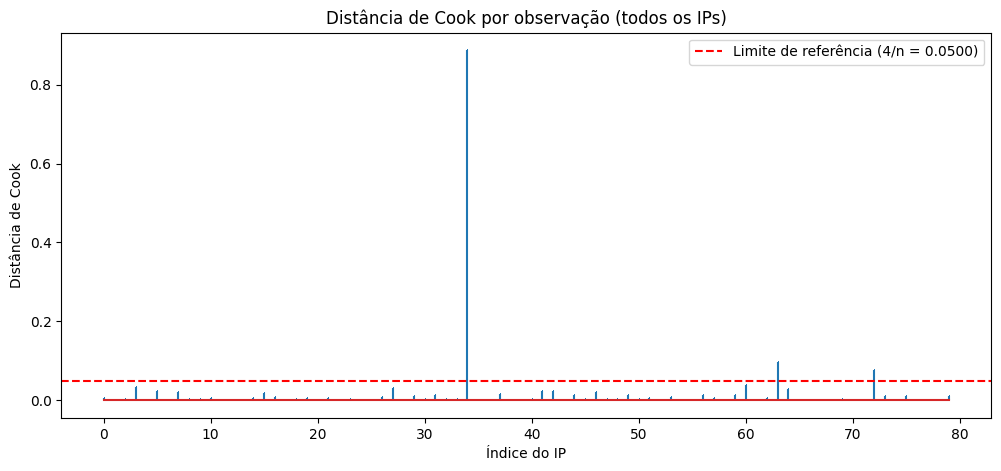


Resumo do modelo salvo em 'resultado_regressao.txt'


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ==============================================================
# REGRESSÃO LINEAR MÚLTIPLA — Dissertação (Conversação Social x Audiência Globoplay)
# Ambiente: Google Colab
# Bibliotecas: pandas + statsmodels
# ==============================================================

# --- 1. INSTALAÇÃO (rodar uma vez no Colab, se necessário) ---
# !pip install pandas statsmodels scipy matplotlib

import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson
from scipy import stats
import matplotlib.pyplot as plt

# --- 2. LEITURA DO ARQUIVO ---
# O arquivo já está no ambiente do Colab (barra lateral de arquivos),
# então basta ler direto pelo nome.
#
# Arquivos .csv exportados do Excel no Brasil podem ter dois problemas comuns:
# 1) Encoding diferente de UTF-8 (ex.: latin-1, cp1252)
# 2) Separador ";" em vez de "," -- e quando isso não é tratado, vírgulas
#    dentro de textos (ex. títulos de programas) quebram a leitura.
#
# O código abaixo tenta detectar automaticamente o separador correto (usando
# o engine "python", que consegue inferir o delimitador com sep=None),
# combinando com os encodings mais comuns.

nome_arquivo = "Base_IPsGloboplay_Mestrado.csv"

encodings_para_tentar = ["utf-8", "latin-1", "cp1252"]

df = None
erro_final = None
for enc in encodings_para_tentar:
    try:
        df = pd.read_csv(nome_arquivo, encoding=enc, sep=None, engine="python")
        print(f"Arquivo carregado com sucesso usando encoding: {enc}")
        print(f"Separador detectado automaticamente. Colunas encontradas: {list(df.columns)}")
        break
    except (UnicodeDecodeError, pd.errors.ParserError) as e:
        erro_final = e
        continue

if df is None:
    raise ValueError(
        f"Não foi possível ler o arquivo automaticamente. Último erro: {erro_final}\n"
        "Isso geralmente indica que alguma linha do arquivo está com vírgulas "
        "ou ponto-e-vírgulas inconsistentes dentro do texto (ex.: título de "
        "programa com vírgula sem estar entre aspas no CSV original). "
        "Abra o arquivo original no Excel e verifique a linha indicada no erro, "
        "ou reexporte o arquivo garantindo que campos de texto com vírgula "
        "estejam entre aspas."
    )

# Confira as primeiras linhas e os tipos de dado
print(df.head())
print(df.info())

# --- 3. DEFINIÇÃO DAS VARIÁVEIS ---
# Nomes das colunas exatamente como aparecem no arquivo original

variavel_dependente = "Alcance (90d)"

variaveis_independentes = [
    "Talkability",
    "Buzz Score",
    "Views por post",
    "Tx de Engajamento",
]

# --- 3.1 DIAGNÓSTICO E LIMPEZA DE TIPOS DE DADOS ---
# Dados brasileiros exportados do Excel costumam vir como TEXTO, não número,
# por causa de vírgula decimal (ex. "12,5"), símbolo de % (ex. "12,5%") ou
# ponto como separador de milhar (ex. "1.234"). Se isso não for corrigido,
# o statsmodels trata a coluna como categórica e o modelo quebra.

print("Tipos de dados ANTES da limpeza:")
print(df[variaveis_independentes + [variavel_dependente]].dtypes)

def limpar_numero_br(coluna):
    """Converte uma coluna de texto em formato numérico brasileiro para float.
    Trata: espaços, símbolo de %, ponto de milhar e vírgula decimal."""
    if coluna.dtype == object:
        coluna = (
            coluna.astype(str)
            .str.strip()
            .str.replace("%", "", regex=False)
            .str.replace(".", "", regex=False)   # remove ponto de milhar
            .str.replace(",", ".", regex=False)   # vírgula -> ponto decimal
        )
        coluna = pd.to_numeric(coluna, errors="coerce")
    return coluna

for col in variaveis_independentes + [variavel_dependente]:
    df[col] = limpar_numero_br(df[col])

print("\nTipos de dados DEPOIS da limpeza:")
print(df[variaveis_independentes + [variavel_dependente]].dtypes)

# Se a limpeza gerou algum valor ausente (NaN) por não conseguir converter,
# isso aparece aqui -- vale checar antes de seguir:
print("\nValores que viraram NaN após a limpeza (se houver, investigue a fonte):")
print(df[variaveis_independentes + [variavel_dependente]].isnull().sum())

# --- 4. VERIFICAÇÃO DE DADOS FALTANTES ---
print("\nValores ausentes por coluna:")
print(df[[variavel_dependente] + variaveis_independentes].isnull().sum())

# Remova ou trate linhas com dados faltantes antes de seguir, se houver
df = df.dropna(subset=[variavel_dependente] + variaveis_independentes)

# --- 5. ESTIMAÇÃO DO MODELO DE REGRESSÃO MÚLTIPLA ---
# Usando a interface de fórmula do statsmodels (mais legível)
# Como os nomes das colunas têm espaços/parênteses, é preciso "escapar"
# cada nome com Q("...") para a fórmula funcionar corretamente.

def escapar(nome_coluna):
    return f'Q("{nome_coluna}")'

formula = f"{escapar(variavel_dependente)} ~ " + " + ".join(
    escapar(v) for v in variaveis_independentes
)
modelo = smf.ols(formula=formula, data=df).fit()

# --- 6. SAÍDA COMPLETA DO MODELO ---
# Isto já traz: coeficientes, erro padrão, valores-t, p-valores, R², R² ajustado, F-estatística
print(modelo.summary())

# --- 6.1 MODELO PADRONIZADO (Z-SCORE) — para resolver problema de escala ---
# O número de condição alto (Cond. No.) no modelo acima geralmente indica que
# as variáveis estão em escalas muito diferentes entre si (ex. Talkability em
# unidades pequenas vs. Alcance na casa de centenas de milhares), e não
# necessariamente multicolinearidade real.
#
# Padronizar (transformar cada variável para média 0 e desvio padrão 1) resolve
# o problema numérico E torna os coeficientes comparáveis entre si — o maior
# coeficiente padronizado indica a variável com maior peso relativo no modelo.

from scipy.stats import zscore

df_padronizado = df.copy()
todas_variaveis = [variavel_dependente] + variaveis_independentes

for col in todas_variaveis:
    df_padronizado[col] = zscore(df_padronizado[col])

formula_padronizada = f"{escapar(variavel_dependente)} ~ " + " + ".join(
    escapar(v) for v in variaveis_independentes
)
modelo_padronizado = smf.ols(formula=formula_padronizada, data=df_padronizado).fit()

print("\n" + "=" * 78)
print("MODELO PADRONIZADO (coeficientes comparáveis entre si)")
print("=" * 78)
print(modelo_padronizado.summary())

# --- 7. TESTES DE PRESSUPOSTOS ---

# 7.1 Linearidade e Homocedasticidade — gráfico de resíduos vs. valores ajustados
plt.figure(figsize=(8, 5))
plt.scatter(modelo.fittedvalues, modelo.resid, alpha=0.6)
plt.axhline(y=0, color="red", linestyle="--")
plt.xlabel("Valores ajustados")
plt.ylabel("Resíduos")
plt.title("Resíduos vs. Valores Ajustados (Linearidade/Homocedasticidade)")
plt.show()

# 7.2 Homocedasticidade — Teste de Breusch-Pagan
# H0: homocedasticidade (variância constante) — p > 0,05 é o resultado desejado
bp_test = het_breuschpagan(modelo.resid, modelo.model.exog)
labels = ["LM Statistic", "LM p-value", "F-Statistic", "F p-value"]
print("\nTeste de Breusch-Pagan (Homocedasticidade):")
print(dict(zip(labels, bp_test)))

# 7.3 Independência dos resíduos — Durbin-Watson
# Valores próximos de 2 indicam ausência de autocorrelação
dw = durbin_watson(modelo.resid)
print(f"\nDurbin-Watson: {dw:.3f} (ideal: próximo de 2)")

# 7.4 Normalidade dos resíduos — Shapiro-Wilk
# H0: resíduos seguem distribuição normal — p > 0,05 é o resultado desejado
shapiro_test = stats.shapiro(modelo.resid)
print(f"\nTeste de Shapiro-Wilk (Normalidade): estatística={shapiro_test[0]:.4f}, p-valor={shapiro_test[1]:.4f}")

# Histograma dos resíduos (inspeção visual da normalidade)
plt.figure(figsize=(8, 5))
plt.hist(modelo.resid, bins=20, edgecolor="black")
plt.xlabel("Resíduos")
plt.ylabel("Frequência")
plt.title("Distribuição dos Resíduos")
plt.show()

# QQ-plot (outra forma visual de checar normalidade)
sm.qqplot(modelo.resid, line="45", fit=True)
plt.title("QQ-Plot dos Resíduos")
plt.show()

# 7.5 Multicolinearidade — VIF (Fator de Inflação da Variância)
# Importante quando há mais de uma variável independente (seu caso)
from statsmodels.stats.outliers_influence import variance_inflation_factor

X = sm.add_constant(df[variaveis_independentes])
vif_data = pd.DataFrame()
vif_data["Variável"] = X.columns
vif_data["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
print("\nFator de Inflação da Variância (VIF):")
print(vif_data)
# Regra prática: VIF > 10 indica problema sério de multicolinearidade

# --- 7.6 DIAGNÓSTICO DE OUTLIERS E OBSERVAÇÕES INFLUENTES ---
# Antes de remover qualquer caso do modelo, é preciso justificativa estatística
# objetiva — não basta "achar" que um caso é outlier. Duas métricas padrão:
#
# 1) Resíduo padronizado: valores acima de |3| (ou às vezes |2|) indicam que
#    aquele caso está muito distante do que o modelo previu.
# 2) Distância de Cook: mede o quanto aquele caso, sozinho, influencia as
#    estimativas do modelo. Regra prática: valores acima de 4/n são notáveis.

influence = modelo.get_influence()
residuos_padronizados = influence.resid_studentized_internal
distancia_cook = influence.cooks_distance[0]

diagnostico = df.copy()
diagnostico["Residuo_Padronizado"] = residuos_padronizados
diagnostico["Distancia_Cook"] = distancia_cook

limite_cook = 4 / len(df)

print(f"\nLimite de referência para Distância de Cook (4/n): {limite_cook:.4f}")
print("\nCasos com resíduo padronizado > |3| (outliers pelo critério de resíduo):")
print(diagnostico[diagnostico["Residuo_Padronizado"].abs() > 3][
    ["Título/IP", "Residuo_Padronizado", "Distancia_Cook"]
])

print("\nCasos com Distância de Cook acima do limite (observações influentes):")
print(diagnostico[diagnostico["Distancia_Cook"] > limite_cook][
    ["Título/IP", "Residuo_Padronizado", "Distancia_Cook"]
])

# Para checar um IP específico (ex. "Arcanjo Renegado"), use:
ip_para_checar = "Arcanjo Renegado"
print(f"\nDiagnóstico específico para '{ip_para_checar}':")
print(diagnostico[diagnostico["Título/IP"] == ip_para_checar][
    ["Título/IP", variavel_dependente, "Residuo_Padronizado", "Distancia_Cook"]
])

# --- 7.7 DISTÂNCIA DE COOK — TODOS OS 80 IPs, ORDENADOS DO MAIS INFLUENTE ---
# Visão completa para identificar rapidamente se há outros candidatos a
# observação influente além do que já foi identificado manualmente.

tabela_cook_completa = diagnostico[
    ["Título/IP", variavel_dependente, "Residuo_Padronizado", "Distancia_Cook"]
].sort_values("Distancia_Cook", ascending=False).reset_index(drop=True)

print("\n" + "=" * 78)
print("DISTÂNCIA DE COOK — TODOS OS IPs (ordenado do mais para o menos influente)")
print("=" * 78)
print(tabela_cook_completa.to_string())

# Gráfico de distância de Cook por observação (facilita visualizar outliers)
plt.figure(figsize=(12, 5))
plt.stem(range(len(diagnostico)), diagnostico["Distancia_Cook"], markerfmt=",")
plt.axhline(y=limite_cook, color="red", linestyle="--",
            label=f"Limite de referência (4/n = {limite_cook:.4f})")
plt.xlabel("Índice do IP")
plt.ylabel("Distância de Cook")
plt.title("Distância de Cook por observação (todos os IPs)")
plt.legend()
plt.show()

# --- 8. EXPORTAR RESULTADOS (opcional, para anexar na dissertação) ---
with open("resultado_regressao.txt", "w") as f:
    f.write(modelo.summary().as_text())

print("\nResumo do modelo salvo em 'resultado_regressao.txt'")

# Baixa o arquivo automaticamente para o seu computador
from google.colab import files
files.download("resultado_regressao.txt")


In [ ]:
# ==============================================================
# REGRESSÃO LINEAR MÚLTIPLA — Dissertação (Conversação Social x Audiência Globoplay)
# Ambiente: Google Colab
# Bibliotecas: pandas + statsmodels
# ==============================================================

# --- 1. INSTALAÇÃO (rodar uma vez no Colab, se necessário) ---
# !pip install pandas statsmodels scipy matplotlib

import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson
from scipy import stats
import matplotlib.pyplot as plt

# --- 2. LEITURA DO ARQUIVO ---
# O arquivo já está no ambiente do Colab (barra lateral de arquivos),
# então basta ler direto pelo nome.
#
# Arquivos .csv exportados do Excel no Brasil podem ter dois problemas comuns:
# 1) Encoding diferente de UTF-8 (ex.: latin-1, cp1252)
# 2) Separador ";" em vez de "," -- e quando isso não é tratado, vírgulas
#    dentro de textos (ex. títulos de programas) quebram a leitura.
#
# O código abaixo tenta detectar automaticamente o separador correto (usando
# o engine "python", que consegue inferir o delimitador com sep=None),
# combinando com os encodings mais comuns.

nome_arquivo = "Base_IPsGloboplay_Mestrado.csv"

encodings_para_tentar = ["utf-8", "latin-1", "cp1252"]

df = None
erro_final = None
for enc in encodings_para_tentar:
    try:
        df = pd.read_csv(nome_arquivo, encoding=enc, sep=None, engine="python")
        print(f"Arquivo carregado com sucesso usando encoding: {enc}")
        print(f"Separador detectado automaticamente. Colunas encontradas: {list(df.columns)}")
        break
    except (UnicodeDecodeError, pd.errors.ParserError) as e:
        erro_final = e
        continue

if df is None:
    raise ValueError(
        f"Não foi possível ler o arquivo automaticamente. Último erro: {erro_final}\n"
        "Isso geralmente indica que alguma linha do arquivo está com vírgulas "
        "ou ponto-e-vírgulas inconsistentes dentro do texto (ex.: título de "
        "programa com vírgula sem estar entre aspas no CSV original). "
        "Abra o arquivo original no Excel e verifique a linha indicada no erro, "
        "ou reexporte o arquivo garantindo que campos de texto com vírgula "
        "estejam entre aspas."
    )

# Confira as primeiras linhas e os tipos de dado
print(df.head())
print(df.info())

# --- 3. DEFINIÇÃO DAS VARIÁVEIS ---
# Nomes das colunas exatamente como aparecem no arquivo original

variavel_dependente = "Alcance (90d)"

variaveis_independentes = [
    "Talkability",
    "Buzz Score",
    "Views por post",
    "Tx de Engajamento",
]

# --- 3.1 DIAGNÓSTICO E LIMPEZA DE TIPOS DE DADOS ---
# Dados brasileiros exportados do Excel costumam vir como TEXTO, não número,
# por causa de vírgula decimal (ex. "12,5"), símbolo de % (ex. "12,5%") ou
# ponto como separador de milhar (ex. "1.234"). Se isso não for corrigido,
# o statsmodels trata a coluna como categórica e o modelo quebra.

print("Tipos de dados ANTES da limpeza:")
print(df[variaveis_independentes + [variavel_dependente]].dtypes)

def limpar_numero_br(coluna):
    """Converte uma coluna de texto em formato numérico brasileiro para float.
    Trata: espaços, símbolo de %, ponto de milhar e vírgula decimal."""
    if coluna.dtype == object:
        coluna = (
            coluna.astype(str)
            .str.strip()
            .str.replace("%", "", regex=False)
            .str.replace(".", "", regex=False)   # remove ponto de milhar
            .str.replace(",", ".", regex=False)   # vírgula -> ponto decimal
        )
        coluna = pd.to_numeric(coluna, errors="coerce")
    return coluna

for col in variaveis_independentes + [variavel_dependente]:
    df[col] = limpar_numero_br(df[col])

print("\nTipos de dados DEPOIS da limpeza:")
print(df[variaveis_independentes + [variavel_dependente]].dtypes)

# Se a limpeza gerou algum valor ausente (NaN) por não conseguir converter,
# isso aparece aqui -- vale checar antes de seguir:
print("\nValores que viraram NaN após a limpeza (se houver, investigue a fonte):")
print(df[variaveis_independentes + [variavel_dependente]].isnull().sum())

# --- 3.2 ANÁLISE DESCRITIVA DOS DADOS ---
# Estatísticas descritivas (média, mediana, desvio padrão, mínimo, máximo,
# quartis) e visualização da distribuição de cada variável, antes de rodar
# o modelo de regressão. Essa etapa costuma abrir a seção de Resultados,
# caracterizando a amostra antes de entrar na análise inferencial.

todas_variaveis_descritiva = [variavel_dependente] + variaveis_independentes

# Tabela de estatísticas descritivas
estatisticas_descritivas = df[todas_variaveis_descritiva].describe().T
estatisticas_descritivas["mediana"] = df[todas_variaveis_descritiva].median()
estatisticas_descritivas = estatisticas_descritivas[
    ["count", "mean", "mediana", "std", "min", "25%", "50%", "75%", "max"]
]
estatisticas_descritivas.columns = [
    "N", "Média", "Mediana", "Desvio Padrão", "Mínimo",
    "1º Quartil", "2º Quartil", "3º Quartil", "Máximo"
]

print("=" * 78)
print("ESTATÍSTICAS DESCRITIVAS")
print("=" * 78)
print(estatisticas_descritivas.round(2))

# Salvar a tabela descritiva em CSV (útil para colar direto numa tabela ABNT)
estatisticas_descritivas.round(2).to_csv("estatisticas_descritivas.csv")
print("\nTabela salva em 'estatisticas_descritivas.csv'")

# --- 3.3 HISTOGRAMAS — DISTRIBUIÇÃO DE CADA VARIÁVEL ---
fig, eixos = plt.subplots(2, 3, figsize=(16, 9))
eixos = eixos.flatten()

for i, col in enumerate(todas_variaveis_descritiva):
    eixos[i].hist(df[col], bins=15, edgecolor="black", color="#4C72B0")
    eixos[i].axvline(df[col].mean(), color="red", linestyle="--", label="Média")
    eixos[i].axvline(df[col].median(), color="green", linestyle="--", label="Mediana")
    eixos[i].set_title(col)
    eixos[i].set_xlabel("Valor")
    eixos[i].set_ylabel("Frequência")
    eixos[i].legend(fontsize=8)

# Remove eixo extra não utilizado (5 variáveis em grade 2x3 = 1 espaço sobra)
for j in range(len(todas_variaveis_descritiva), len(eixos)):
    fig.delaxes(eixos[j])

plt.tight_layout()
plt.suptitle("Distribuição das Variáveis", y=1.02, fontsize=14)
plt.savefig("histogramas_distribuicao.png", bbox_inches="tight", dpi=150)
plt.show()

# --- 3.4 BOXPLOTS — VISUALIZAR DISPERSÃO E OUTLIERS POR VARIÁVEL ---
fig, eixos = plt.subplots(2, 3, figsize=(16, 9))
eixos = eixos.flatten()

for i, col in enumerate(todas_variaveis_descritiva):
    eixos[i].boxplot(df[col], vert=True)
    eixos[i].set_title(col)
    eixos[i].set_ylabel("Valor")

for j in range(len(todas_variaveis_descritiva), len(eixos)):
    fig.delaxes(eixos[j])

plt.tight_layout()
plt.suptitle("Dispersão e Outliers por Variável (Boxplot)", y=1.02, fontsize=14)
plt.savefig("boxplots_variaveis.png", bbox_inches="tight", dpi=150)
plt.show()

# --- 4. VERIFICAÇÃO DE DADOS FALTANTES ---
print("\nValores ausentes por coluna:")
print(df[[variavel_dependente] + variaveis_independentes].isnull().sum())

# Remova ou trate linhas com dados faltantes antes de seguir, se houver
df = df.dropna(subset=[variavel_dependente] + variaveis_independentes)

# --- 5. ESTIMAÇÃO DO MODELO DE REGRESSÃO MÚLTIPLA ---
# Usando a interface de fórmula do statsmodels (mais legível)
# Como os nomes das colunas têm espaços/parênteses, é preciso "escapar"
# cada nome com Q("...") para a fórmula funcionar corretamente.

def escapar(nome_coluna):
    return f'Q("{nome_coluna}")'

formula = f"{escapar(variavel_dependente)} ~ " + " + ".join(
    escapar(v) for v in variaveis_independentes
)
modelo = smf.ols(formula=formula, data=df).fit()

# --- 6. SAÍDA COMPLETA DO MODELO ---
# Isto já traz: coeficientes, erro padrão, valores-t, p-valores, R², R² ajustado, F-estatística
print(modelo.summary())

# --- 6.1 MODELO PADRONIZADO (Z-SCORE) — para resolver problema de escala ---
# O número de condição alto (Cond. No.) no modelo acima geralmente indica que
# as variáveis estão em escalas muito diferentes entre si (ex. Talkability em
# unidades pequenas vs. Alcance na casa de centenas de milhares), e não
# necessariamente multicolinearidade real.
#
# Padronizar (transformar cada variável para média 0 e desvio padrão 1) resolve
# o problema numérico E torna os coeficientes comparáveis entre si — o maior
# coeficiente padronizado indica a variável com maior peso relativo no modelo.

from scipy.stats import zscore

df_padronizado = df.copy()
todas_variaveis = [variavel_dependente] + variaveis_independentes

for col in todas_variaveis:
    df_padronizado[col] = zscore(df_padronizado[col])

formula_padronizada = f"{escapar(variavel_dependente)} ~ " + " + ".join(
    escapar(v) for v in variaveis_independentes
)
modelo_padronizado = smf.ols(formula=formula_padronizada, data=df_padronizado).fit()

print("\n" + "=" * 78)
print("MODELO PADRONIZADO (coeficientes comparáveis entre si)")
print("=" * 78)
print(modelo_padronizado.summary())

# --- 7. TESTES DE PRESSUPOSTOS ---

# 7.1 Linearidade e Homocedasticidade — gráfico de resíduos vs. valores ajustados
plt.figure(figsize=(8, 5))
plt.scatter(modelo.fittedvalues, modelo.resid, alpha=0.6)
plt.axhline(y=0, color="red", linestyle="--")
plt.xlabel("Valores ajustados")
plt.ylabel("Resíduos")
plt.title("Resíduos vs. Valores Ajustados (Linearidade/Homocedasticidade)")
plt.show()

# 7.2 Homocedasticidade — Teste de Breusch-Pagan
# H0: homocedasticidade (variância constante) — p > 0,05 é o resultado desejado
bp_test = het_breuschpagan(modelo.resid, modelo.model.exog)
labels = ["LM Statistic", "LM p-value", "F-Statistic", "F p-value"]
print("\nTeste de Breusch-Pagan (Homocedasticidade):")
print(dict(zip(labels, bp_test)))

# 7.3 Independência dos resíduos — Durbin-Watson
# Valores próximos de 2 indicam ausência de autocorrelação
dw = durbin_watson(modelo.resid)
print(f"\nDurbin-Watson: {dw:.3f} (ideal: próximo de 2)")

# 7.4 Normalidade dos resíduos — Shapiro-Wilk
# H0: resíduos seguem distribuição normal — p > 0,05 é o resultado desejado
shapiro_test = stats.shapiro(modelo.resid)
print(f"\nTeste de Shapiro-Wilk (Normalidade): estatística={shapiro_test[0]:.4f}, p-valor={shapiro_test[1]:.4f}")

# Histograma dos resíduos (inspeção visual da normalidade)
plt.figure(figsize=(8, 5))
plt.hist(modelo.resid, bins=20, edgecolor="black")
plt.xlabel("Resíduos")
plt.ylabel("Frequência")
plt.title("Distribuição dos Resíduos")
plt.show()

# QQ-plot (outra forma visual de checar normalidade)
sm.qqplot(modelo.resid, line="45", fit=True)
plt.title("QQ-Plot dos Resíduos")
plt.show()

# 7.5 Multicolinearidade — VIF (Fator de Inflação da Variância)
# Importante quando há mais de uma variável independente (seu caso)
from statsmodels.stats.outliers_influence import variance_inflation_factor

X = sm.add_constant(df[variaveis_independentes])
vif_data = pd.DataFrame()
vif_data["Variável"] = X.columns
vif_data["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
print("\nFator de Inflação da Variância (VIF):")
print(vif_data)
# Regra prática: VIF > 10 indica problema sério de multicolinearidade

# --- 7.6 DIAGNÓSTICO DE OUTLIERS E OBSERVAÇÕES INFLUENTES ---
# Antes de remover qualquer caso do modelo, é preciso justificativa estatística
# objetiva — não basta "achar" que um caso é outlier. Duas métricas padrão:
#
# 1) Resíduo padronizado: valores acima de |3| (ou às vezes |2|) indicam que
#    aquele caso está muito distante do que o modelo previu.
# 2) Distância de Cook: mede o quanto aquele caso, sozinho, influencia as
#    estimativas do modelo. Regra prática: valores acima de 4/n são notáveis.

influence = modelo.get_influence()
residuos_padronizados = influence.resid_studentized_internal
distancia_cook = influence.cooks_distance[0]

diagnostico = df.copy()
diagnostico["Residuo_Padronizado"] = residuos_padronizados
diagnostico["Distancia_Cook"] = distancia_cook

limite_cook = 4 / len(df)

print(f"\nLimite de referência para Distância de Cook (4/n): {limite_cook:.4f}")
print("\nCasos com resíduo padronizado > |3| (outliers pelo critério de resíduo):")
print(diagnostico[diagnostico["Residuo_Padronizado"].abs() > 3][
    ["Título/IP", "Residuo_Padronizado", "Distancia_Cook"]
])

print("\nCasos com Distância de Cook acima do limite (observações influentes):")
print(diagnostico[diagnostico["Distancia_Cook"] > limite_cook][
    ["Título/IP", "Residuo_Padronizado", "Distancia_Cook"]
])

# Para checar um IP específico (ex. "Arcanjo Renegado"), use:
ip_para_checar = "Arcanjo Renegado"
print(f"\nDiagnóstico específico para '{ip_para_checar}':")
print(diagnostico[diagnostico["Título/IP"] == ip_para_checar][
    ["Título/IP", variavel_dependente, "Residuo_Padronizado", "Distancia_Cook"]
])

# --- 7.7 DISTÂNCIA DE COOK — TODOS OS 80 IPs, ORDENADOS DO MAIS INFLUENTE ---
# Visão completa para identificar rapidamente se há outros candidatos a
# observação influente além do que já foi identificado manualmente.

tabela_cook_completa = diagnostico[
    ["Título/IP", variavel_dependente, "Residuo_Padronizado", "Distancia_Cook"]
].sort_values("Distancia_Cook", ascending=False).reset_index(drop=True)

print("\n" + "=" * 78)
print("DISTÂNCIA DE COOK — TODOS OS IPs (ordenado do mais para o menos influente)")
print("=" * 78)
print(tabela_cook_completa.to_string())

# Gráfico de distância de Cook por observação (facilita visualizar outliers)
plt.figure(figsize=(12, 5))
plt.stem(range(len(diagnostico)), diagnostico["Distancia_Cook"], markerfmt=",")
plt.axhline(y=limite_cook, color="red", linestyle="--",
            label=f"Limite de referência (4/n = {limite_cook:.4f})")
plt.xlabel("Índice do IP")
plt.ylabel("Distância de Cook")
plt.title("Distância de Cook por observação (todos os IPs)")
plt.legend()
plt.show()

# --- 8. EXPORTAR RESULTADOS (opcional, para anexar na dissertação) ---
with open("resultado_regressao.txt", "w") as f:
    f.write(modelo.summary().as_text())

print("\nResumo do modelo salvo em 'resultado_regressao.txt'")

# Baixa o arquivo automaticamente para o seu computador
from google.colab import files
files.download("resultado_regressao.txt")


FileNotFoundError: [Errno 2] No such file or directory: 'Base_IPsGloboplay_Mestrado.csv'

In [ ]:
from google.colab import drive
drive.mount('/content/drive')